# 3.0-Second CRNN-BiGRU-Attention Model Training: 3.0-Second CRNN-BiGRU-Attention Model Training, Evaluation, and INT8 Quantization

This notebook conducts end-to-end training, evaluation, and full INT8 post-training quantization for the **3.0-second** temporal resolution Philippine eagle call classifier:
- **3.0s Standard Split**: Grouped by recording source, leak-free, augmented samples in train only
- **3.0s Leave-One-Site-Out (LOSO) - Davao del Sur**: Geographic generalization benchmark
- **3.0s Leave-One-Site-Out (LOSO) - Cotabato**: Geographic generalization benchmark
- **INT8 Post-Training Quantization**: Edge MCU optimization with representative calibration

## 1. Imports and Configuration

In [1]:
import os
import sys
import time
import json
import gc
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm.auto import tqdm

import tensorflow as tf
from sklearn.model_selection import GroupShuffleSplit
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report, roc_auc_score,
    precision_recall_curve, roc_curve, auc
)

# Suppress minor warnings and configure styling
warnings.filterwarnings("ignore", category=UserWarning)
warnings.filterwarnings("ignore", category=FutureWarning)
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["font.sans-serif"] = "DejaVu Sans"
plt.rcParams["figure.dpi"] = 150

# Reproducibility Seeds
SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)
os.environ["PYTHONHASHSEED"] = str(SEED)

# Configure GPU Memory Growth to prevent OOM
gpus = tf.config.list_physical_devices('GPU')
if gpus:
    try:
        for gpu in gpus:
            tf.config.experimental.set_memory_growth(gpu, True)
    except RuntimeError as e:
        print(f'Memory growth setting failed: {e}')

# Project Paths
def find_project_root():
    p = Path.cwd().resolve()
    while p != p.parent:
        if (p / "data").exists() and (p / "AGENTS.md").exists():
            return p
        p = p.parent
    return Path.cwd().resolve().parent.parent

PROJECT_ROOT = find_project_root()
EXPERIMENT_DIR = Path.cwd().resolve()
OUTPUTS_DIR = EXPERIMENT_DIR / "outputs"
MODELS_DIR = EXPERIMENT_DIR / "models"
DATA_DIR = PROJECT_ROOT / "data"
FEATURES_DIR = DATA_DIR / "features"



FIGURES_DIR = OUTPUTS_DIR / "figures"
CONFUSION_DIR = OUTPUTS_DIR / "confusion-matrices"
HISTORY_DIR = OUTPUTS_DIR / "training-history"

for d in [FIGURES_DIR, CONFUSION_DIR, HISTORY_DIR]:
    d.mkdir(parents=True, exist_ok=True)

# 5.0s and 3.0s Feature Paths
FEATURES_5S_DIR = FEATURES_DIR / "5-seconds" / "pcen-melSpectrogram"
META_5S_PATH = FEATURES_5S_DIR / "features_metadata.csv"
if not META_5S_PATH.exists():
    META_5S_PATH = FEATURES_DIR / "5-seconds" / "features_metadata.csv"

FEATURES_3S_DIR = FEATURES_DIR / "3-seconds" / "pcen-melSpectrogram"
META_3S_PATH = FEATURES_3S_DIR / "features_metadata.csv"
if not META_3S_PATH.exists():
    META_3S_PATH = FEATURES_DIR / "3-seconds" / "features_metadata.csv"

# Model Checkpoints Output Directories
MODELS_5S_STD = MODELS_DIR / "5-seconds" / "standard"
MODELS_5S_LOSO_DAVAO = MODELS_DIR / "5-seconds" / "loso-davao"
MODELS_5S_LOSO_COTABATO = MODELS_DIR / "5-seconds" / "loso-cotabato"

MODELS_3S_STD = MODELS_DIR / "3-seconds" / "standard"
MODELS_3S_LOSO_DAVAO = MODELS_DIR / "3-seconds" / "loso-davao"
MODELS_3S_LOSO_COTABATO = MODELS_DIR / "3-seconds" / "loso-cotabato"

for d in [MODELS_5S_STD, MODELS_5S_LOSO_DAVAO, MODELS_5S_LOSO_COTABATO,
          MODELS_3S_STD, MODELS_3S_LOSO_DAVAO, MODELS_3S_LOSO_COTABATO]:
    (d / "checkpoints").mkdir(parents=True, exist_ok=True)

# Training Hyperparameters
BATCH_SIZE = 32
EPOCHS = 50
PATIENCE = 10
LEARNING_RATE = 1e-3
SHAPE_5S = (128, 216, 1)
SHAPE_3S = (128, 130, 1)
NOTEBOOK_ID = "crnn-bi-gru-attention-training"

print("=" * 60)
print("EXPERIMENT ENVIRONMENT CONFIGURED")
print("=" * 60)
print(f"TensorFlow Version: {tf.__version__}")
print(f"Available GPUs:     {tf.config.list_physical_devices('GPU')}")
print(f"Project Root:       {PROJECT_ROOT}")
print(f"5.0s Features Path: {FEATURES_5S_DIR}")
print(f"3.0s Features Path: {FEATURES_3S_DIR}")
print("=" * 60)

I0000 00:00:1791471937.101973   20200 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1791471937.137143   20200 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1791471937.943890   20200 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


EXPERIMENT ENVIRONMENT CONFIGURED
TensorFlow Version: 2.21.0
Available GPUs:     [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Project Root:       /home/fumei/Documents/MachineLearning/EagleSoundClassification
5.0s Features Path: /home/fumei/Documents/MachineLearning/EagleSoundClassification/data/features/5-seconds/pcen-melSpectrogram
3.0s Features Path: /home/fumei/Documents/MachineLearning/EagleSoundClassification/data/features/3-seconds/pcen-melSpectrogram


## 2. Load 3.0-Second Dataset and Feature Arrays

### 2.1 Load 3.0-Second Feature Arrays (128, 130)

In [2]:
# Load 3.0-second features metadata and arrays (Guarded)
if META_3S_PATH.exists():
    df_meta_3s = pd.read_csv(META_3S_PATH)
    df_clean_3s = df_meta_3s[~df_meta_3s["has_ambiguous"]].reset_index(drop=True)
    num_samples_3s = len(df_clean_3s)

    X_all_3s = np.zeros((num_samples_3s, 128, 130, 1), dtype=np.float32)
    print(f"Loading {num_samples_3s} 3.0s PCEN Mel Spectrogram arrays into memory...")
    for i, row in enumerate(tqdm(df_clean_3s.itertuples(), total=num_samples_3s, desc="Loading 3s features")):
        arr_path = FEATURES_3S_DIR / row.feature_file
        arr = np.load(arr_path)
        t_frames = min(arr.shape[1], 130)
        X_all_3s[i, :, :t_frames, 0] = arr[:, :t_frames]

    y_all_3s = df_clean_3s["label"].values.astype(np.float32)
    groups_all_3s = df_clean_3s["source_audio"].values
    sites_all_3s = df_clean_3s["site"].values
    is_aug_all_3s = df_clean_3s["is_augmented"].values

    print(f"\n3.0s Feature tensor shape: {X_all_3s.shape} ({X_all_3s.nbytes / (1024**2):.1f} MB in RAM)")
    print(f"3.0s Label tensor shape:   {y_all_3s.shape} (Positives: {int(np.sum(y_all_3s == 1)):,}, Negatives: {int(np.sum(y_all_3s == 0)):,})")
    print(f"3.0s Augmented samples:    {int(np.sum(is_aug_all_3s)):,} / {len(is_aug_all_3s):,}")
else:
    print(f"Notice: 3.0s metadata not found at {META_3S_PATH}. 3.0s experiments will be skipped if features are absent.")

Loading 14421 3.0s PCEN Mel Spectrogram arrays into memory...


Loading 3s features:   0%|          | 0/14421 [00:00<?, ?it/s]


3.0s Feature tensor shape: (14421, 128, 130, 1) (915.4 MB in RAM)
3.0s Label tensor shape:   (14421,) (Positives: 6,674, Negatives: 7,747)
3.0s Augmented samples:    3,337 / 14,421


## 3. Model Architecture, INT8 Quantization, and Training Pipeline Utilities

In [3]:
def build_crnn_bi_gru_attention_model(input_shape, learning_rate=LEARNING_RATE):
    """
    CRNN with Bidirectional GRU and Learned Temporal Attention Pooling:
    - 3 Conv2D blocks with BatchNorm and MaxPool
    - Spatial-to-temporal transformation (time dimension dynamically calculated)
    - Bidirectional GRU (32 units/dir -> 64 total features, return_sequences=True, unroll=True)
    - Temporal Attention Mechanism (learns dynamic frame-level weights alpha_t in [0, 1])
    - Dot-product context vector: sum_t(alpha_t * h_t)
    - Dense Classification Head
    Optimized for ESP32-S3 microcontroller deployment (TFLite Float16 & INT8 compatible).
    """
    inputs = tf.keras.Input(shape=input_shape, batch_size=None, name="audio_input")

    # Conv Block 1
    x = tf.keras.layers.Conv2D(32, (3, 3), padding="same", activation="relu", name="conv1")(inputs)
    x = tf.keras.layers.BatchNormalization(name="bn1")(x)
    x = tf.keras.layers.MaxPooling2D((2, 2), name="pool1")(x)

    # Conv Block 2
    x = tf.keras.layers.Conv2D(64, (3, 3), padding="same", activation="relu", name="conv2")(x)
    x = tf.keras.layers.BatchNormalization(name="bn2")(x)
    x = tf.keras.layers.MaxPooling2D((2, 2), name="pool2")(x)

    # Conv Block 3
    x = tf.keras.layers.Conv2D(128, (3, 3), padding="same", activation="relu", name="conv3")(x)
    x = tf.keras.layers.BatchNormalization(name="bn3")(x)
    x = tf.keras.layers.MaxPooling2D((4, 2), name="pool3")(x)

    # Dynamic time-step calculation: 130 // 8 = 16 for 3s; 216 // 8 = 27 for 5s
    time_steps = input_shape[1] // 8

    # Permute to (batch, time, freq, channels) -> Reshape to (batch, time_steps, 8 * 128 = 1024)
    x = tf.keras.layers.Permute((2, 1, 3), name="permute_time_first")(x)
    x = tf.keras.layers.Reshape((time_steps, -1), name="time_flatten")(x)

    # Bidirectional GRU (Unrolled for full TFLite INT8 / Float16 compatibility on edge MCUs)
    gru_seq = tf.keras.layers.Bidirectional(
        tf.keras.layers.GRU(32, return_sequences=True, unroll=True),
        name="bidirectional_gru"
    )(x)
    gru_seq = tf.keras.layers.Dropout(0.3, name="gru_dropout")(gru_seq)

    # Temporal Attention Mechanism (Frame-level learned dynamic pooling)
    attn_score = tf.keras.layers.Dense(32, activation="tanh", name="attn_dense")(gru_seq)
    attn_raw = tf.keras.layers.Dense(1, activation=None, name="attn_raw")(attn_score)
    attn_flat = tf.keras.layers.Reshape((16,), name="attn_flat")(attn_raw)
    attn_weights = tf.keras.layers.Softmax(axis=-1, name="temporal_attention_weights")(attn_flat)

    # Weighted context vector: (batch, time) . (batch, time, 64) -> (batch, 64)
    context = tf.keras.layers.Dot(axes=1, name="attn_context")([attn_weights, gru_seq])

    # Dense Output Head
    dense = tf.keras.layers.Dense(32, activation="relu", name="dense1")(context)
    dense = tf.keras.layers.Dropout(0.3, name="dense_dropout")(dense)
    outputs = tf.keras.layers.Dense(1, activation="sigmoid", name="eagle_prob")(dense)

    model = tf.keras.Model(inputs=inputs, outputs=outputs, name="CRNN_BiGRU_Attention_Eagle_Classifier")
    optimizer = tf.keras.optimizers.Adam(learning_rate=learning_rate, clipnorm=1.0)
    model.compile(
        optimizer=optimizer,
        loss="binary_crossentropy",
        metrics=[
            "accuracy",
            tf.keras.metrics.AUC(name="auc"),
            tf.keras.metrics.Precision(name="precision"),
            tf.keras.metrics.Recall(name="recall")
        ]
    )
    return model


class SpecAugmentDataGenerator(tf.keras.utils.Sequence):
    """
    On-the-fly SpecAugment data generator for robust audio spectrogram training:
    - Subtle Gain Scaling (0.85x to 1.15x) applied to both classes (simulating distance variation)
    - SpecAugment Frequency Masking (up to F mel bins) applied to positive eagle calls
    - SpecAugment Time Masking (up to T time steps) applied to positive eagle calls
    Validation and Test sets should use clean arrays directly without generator masking.
    """
    def __init__(self, X, y, batch_size=BATCH_SIZE, is_training=True,
                 freq_mask_max=12, time_mask_max=15,
                 gain_min=0.85, gain_max=1.15,
                 p_gain=0.5, p_freq=0.5, p_time=0.5,
                 shuffle=True, seed=SEED):
        self.X = X
        self.y = y
        self.batch_size = batch_size
        self.is_training = is_training
        self.freq_mask_max = freq_mask_max
        self.time_mask_max = time_mask_max
        self.gain_min = gain_min
        self.gain_max = gain_max
        self.p_gain = p_gain
        self.p_freq = p_freq
        self.p_time = p_time
        self.shuffle = shuffle
        self.rng = np.random.default_rng(seed)
        self.indices = np.arange(len(self.X))
        if self.shuffle:
            self.rng.shuffle(self.indices)

    def __len__(self):
        return int(np.ceil(len(self.X) / self.batch_size))

    def on_epoch_end(self):
        if self.shuffle:
            self.rng.shuffle(self.indices)

    def __getitem__(self, idx):
        batch_idx = self.indices[idx * self.batch_size:(idx + 1) * self.batch_size]
        X_batch = np.copy(self.X[batch_idx])
        y_batch = np.copy(self.y[batch_idx])

        if self.is_training:
            for i in range(len(X_batch)):
                # 1. Subtle Gain Scaling (both classes)
                if self.rng.random() < self.p_gain:
                    gain = self.rng.uniform(self.gain_min, self.gain_max)
                    X_batch[i] = X_batch[i] * gain

                # 2. SpecAugment Masking (prioritized on positive eagle calls)
                if y_batch[i] == 1.0:
                    # Frequency Masking (horizontal band)
                    if self.rng.random() < self.p_freq:
                        f_width = int(self.rng.integers(1, self.freq_mask_max + 1))
                        f_start = int(self.rng.integers(0, max(1, X_batch.shape[1] - f_width)))
                        X_batch[i, f_start:f_start + f_width, :, :] = 0.0

                    # Time Masking (vertical band)
                    if self.rng.random() < self.p_time:
                        t_width = int(self.rng.integers(1, self.time_mask_max + 1))
                        t_start = int(self.rng.integers(0, max(1, X_batch.shape[2] - t_width)))
                        X_batch[i, :, t_start:t_start + t_width, :] = 0.0

        return X_batch, y_batch


def create_standard_split(df_clean, train_ratio=0.70, val_ratio=0.15, random_state=SEED):
    """
    Leak-free standard split grouped by source_audio:
    1. Splits unaugmented recordings into Train, Val, and Test.
    2. Injects augmented recordings ONLY into the Train split.
    3. Guarantees Val and Test have 0 augmented samples.
    """
    orig_indices = np.where(~df_clean["is_augmented"].values)[0]
    df_orig = df_clean.iloc[orig_indices].reset_index(drop=True)

    pos_sources = df_orig[df_orig["label"] == 1]["source_audio"].unique()
    neg_sources = df_orig[df_orig["label"] == 0]["source_audio"].unique()

    rng = np.random.default_rng(random_state)
    pos_sources = rng.permutation(pos_sources)
    neg_sources = rng.permutation(neg_sources)

    n_pos_tr = int(len(pos_sources) * train_ratio)
    n_pos_val = int(len(pos_sources) * val_ratio)
    tr_pos_src = set(pos_sources[:n_pos_tr])
    val_pos_src = set(pos_sources[n_pos_tr:n_pos_tr + n_pos_val])
    test_pos_src = set(pos_sources[n_pos_tr + n_pos_val:])

    n_neg_tr = int(len(neg_sources) * train_ratio)
    n_neg_val = int(len(neg_sources) * val_ratio)
    tr_neg_src = set(neg_sources[:n_neg_tr])
    val_neg_src = set(neg_sources[n_neg_tr:n_neg_tr + n_neg_val])
    test_neg_src = set(neg_sources[n_neg_tr + n_neg_val:])

    train_sources = tr_pos_src | tr_neg_src
    val_sources = val_pos_src | val_neg_src
    test_sources = test_pos_src | test_neg_src

    orig_train_idx = [orig_indices[i] for i, s in enumerate(df_orig["source_audio"]) if s in train_sources]
    val_idx = [orig_indices[i] for i, s in enumerate(df_orig["source_audio"]) if s in val_sources]
    test_idx = [orig_indices[i] for i, s in enumerate(df_orig["source_audio"]) if s in test_sources]

    aug_indices = np.where(df_clean["is_augmented"].values)[0]
    train_aug_idx = [i for i in aug_indices if df_clean.iloc[i]["source_audio"] in train_sources]

    train_idx = orig_train_idx + train_aug_idx
    return np.array(train_idx), np.array(val_idx), np.array(test_idx)


def create_loso_split(df_clean, holdout_site, val_ratio=0.15, random_state=SEED):
    """
    Leak-free Leave-One-Site-Out (LOSO) split:
    1. Test set consists ONLY of unaugmented samples from the holdout site.
    2. Remaining sites form the train pool (unaugmented).
    3. GroupShuffleSplit partitions train pool into Train and Val by source_audio.
    4. Augmented samples from training sources are injected ONLY into Train.
    5. Guarantees Val and Test have 0 augmented samples.
    """
    orig_indices = np.where(~df_clean["is_augmented"].values)[0]
    df_orig = df_clean.iloc[orig_indices].reset_index(drop=True)

    test_orig_sub_idx = [i for i, row in enumerate(df_orig.itertuples()) if row.site == holdout_site]
    test_idx = [orig_indices[i] for i in test_orig_sub_idx]

    pool_orig_sub_idx = [i for i, row in enumerate(df_orig.itertuples()) if row.site != holdout_site]
    df_pool = df_orig.iloc[pool_orig_sub_idx].reset_index(drop=True)
    pool_indices = [orig_indices[i] for i in pool_orig_sub_idx]

    gss = GroupShuffleSplit(n_splits=1, test_size=val_ratio, random_state=random_state)
    tr_sub, val_sub = next(gss.split(df_pool, df_pool["label"], df_pool["source_audio"]))

    orig_train_idx = [pool_indices[i] for i in tr_sub]
    val_idx = [pool_indices[i] for i in val_sub]

    train_sources = set(df_pool.iloc[tr_sub]["source_audio"])
    aug_indices = np.where(df_clean["is_augmented"].values)[0]
    train_aug_idx = [i for i in aug_indices if df_clean.iloc[i]["source_audio"] in train_sources]

    train_idx = orig_train_idx + train_aug_idx
    return np.array(train_idx), np.array(val_idx), np.array(test_idx)


def report_and_plot_split_distribution(df_clean, train_idx, val_idx, test_idx, experiment_name, save_path=None):
    """
    Displays a distribution summary table and saves a dual-panel distribution figure:
    - Panel 1: Eagle Calls vs Non-Eagle Class Counts
    - Panel 2: Original vs Augmented Counts (Verifying 0 Augmented in Val and Test)
    """
    df_train = df_clean.iloc[train_idx]
    df_val = df_clean.iloc[val_idx]
    df_test = df_clean.iloc[test_idx]

    splits = [("Train", df_train), ("Val", df_val), ("Test", df_test)]
    summary_rows = []

    for name, d in splits:
        total = len(d)
        pos = int((d["label"] == 1).sum())
        neg = int((d["label"] == 0).sum())
        aug = int(d["is_augmented"].sum())
        orig = total - aug
        sources = int(d["source_audio"].nunique())
        summary_rows.append({
            "Split": name,
            "Total Samples": f"{total:,}",
            "Eagle Calls (1)": f"{pos:,} ({pos/total*100:.1f}%)" if total else "0",
            "Non-Eagle (0)": f"{neg:,} ({neg/total*100:.1f}%)" if total else "0",
            "Original Field Audio": f"{orig:,} ({orig/total*100:.1f}%)" if total else "0",
            "Offline Augmented": f"{aug:,} ({aug/total*100:.1f}%)" if total else "0",
            "Unique Audio Sources": f"{sources:,}"
        })

    summary_df = pd.DataFrame(summary_rows)
    print(f"\n=========================================================================================")
    print(f" Partition Distribution Summary: {experiment_name}")
    print(f"=========================================================================================")
    print(summary_df.to_string(index=False))
    print(f"=========================================================================================\n")

    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    split_names = ["Train", "Val", "Test"]
    x = np.arange(len(split_names))
    width = 0.35

    # 1. Class Breakdown
    pos_counts = [(d["label"] == 1).sum() for _, d in splits]
    neg_counts = [(d["label"] == 0).sum() for _, d in splits]

    r1 = axes[0].bar(x - width/2, pos_counts, width, label="Eagle Call (1)", color="#2ca02c")
    r2 = axes[0].bar(x + width/2, neg_counts, width, label="No Eagle Call (0)", color="#1f77b4")
    axes[0].set_title(f"{experiment_name} - Class Balance", fontsize=12, fontweight="bold")
    axes[0].set_ylabel("Number of Samples", fontsize=11)
    axes[0].set_xticks(x)
    axes[0].set_xticklabels(split_names, fontsize=11)
    axes[0].legend(loc="upper right")
    axes[0].grid(axis="y", linestyle="--", alpha=0.5)

    for rects in [r1, r2]:
        for rect in rects:
            h = rect.get_height()
            axes[0].annotate(f"{h:,}", xy=(rect.get_x() + rect.get_width() / 2, h),
                             xytext=(0, 3), textcoords="offset points",
                             ha="center", va="bottom", fontsize=9, fontweight="bold")

    # 2. Provenance Breakdown
    orig_counts = [(~d["is_augmented"]).sum() for _, d in splits]
    aug_counts = [d["is_augmented"].sum() for _, d in splits]

    r3 = axes[1].bar(x - width/2, orig_counts, width, label="Original Field Audio", color="#4a7c59")
    r4 = axes[1].bar(x + width/2, aug_counts, width, label="Offline Augmented", color="#d95f02")
    axes[1].set_title(f"{experiment_name} - Leakage Verification", fontsize=12, fontweight="bold")
    axes[1].set_ylabel("Number of Samples", fontsize=11)
    axes[1].set_xticks(x)
    axes[1].set_xticklabels(split_names, fontsize=11)
    axes[1].legend(loc="upper right")
    axes[1].grid(axis="y", linestyle="--", alpha=0.5)

    for rects in [r3, r4]:
        for rect in rects:
            h = rect.get_height()
            axes[1].annotate(f"{h:,}", xy=(rect.get_x() + rect.get_width() / 2, h),
                             xytext=(0, 3), textcoords="offset points",
                             ha="center", va="bottom", fontsize=9, fontweight="bold")

    plt.tight_layout()
    if save_path:
        save_path = Path(save_path)
        save_path.parent.mkdir(parents=True, exist_ok=True)
        fig.savefig(save_path, dpi=300, bbox_inches="tight")
        print(f"Saved partition distribution figure to: {save_path}")
    plt.show()

    return summary_df


def compute_class_weights(y_train):
    """Compute balanced class weights for binary classification to mitigate class imbalance."""
    n_samples = len(y_train)
    n_pos = np.sum(y_train == 1.0)
    n_neg = n_samples - n_pos
    w0 = (1 / n_neg) * (n_samples / 2.0)
    w1 = (1 / n_pos) * (n_samples / 2.0)
    return {0: float(w0), 1: float(w1)}



def convert_to_tflite_fp16(keras_model, tflite_path):
    """Quantize Keras model weights to Float16 precision for mobile/embedded deployment."""
    converter = tf.lite.TFLiteConverter.from_keras_model(keras_model)
    converter.optimizations = [tf.lite.Optimize.DEFAULT]
    converter.target_spec.supported_types = [tf.float16]
    tflite_model = converter.convert()
    with open(tflite_path, "wb") as f:
        f.write(tflite_model)
    return tflite_path


def convert_to_tflite_int8(keras_model, representative_data, tflite_path):
    """Quantize Keras model to full INT8 precision using representative dataset calibration."""
    converter = tf.lite.TFLiteConverter.from_keras_model(keras_model)
    converter.optimizations = [tf.lite.Optimize.DEFAULT]

    def representative_dataset_gen():
        for sample in representative_data:
            yield [np.expand_dims(sample, axis=0).astype(np.float32)]

    converter.representative_dataset = representative_dataset_gen
    converter.target_spec.supported_ops = [tf.lite.OpsSet.TFLITE_BUILTINS_INT8]
    converter.inference_input_type = tf.int8
    converter.inference_output_type = tf.int8

    tflite_model = converter.convert()
    with open(tflite_path, "wb") as f:
        f.write(tflite_model)
    return tflite_path


def evaluate_tflite_model(tflite_path, X_test, y_test):
    """Evaluate INT8 quantized TFLite model on test set and measure edge inference latency."""
    interpreter = tf.lite.Interpreter(model_path=str(tflite_path))
    interpreter.allocate_tensors()

    input_details = interpreter.get_input_details()[0]
    output_details = interpreter.get_output_details()[0]

    input_scale, input_zero_point = input_details["quantization"]
    output_scale, output_zero_point = output_details["quantization"]

    preds = []
    start_time = time.time()
    for i in range(len(X_test)):
        sample = X_test[i:i+1]
        if input_scale > 0:
            sample_quant = np.clip(np.round(sample / input_scale) + input_zero_point, -128, 127).astype(np.int8)
        else:
            sample_quant = sample.astype(np.float32)

        interpreter.set_tensor(input_details["index"], sample_quant)
        interpreter.invoke()
        output_quant = interpreter.get_tensor(output_details["index"])

        if output_scale > 0:
            output_dequant = (output_quant.astype(np.float32) - output_zero_point) * output_scale
        else:
            output_dequant = output_quant.astype(np.float32)
        preds.append(output_dequant[0][0])

    elapsed_time = time.time() - start_time
    latency_ms_per_sample = (elapsed_time / len(X_test)) * 1000.0

    preds = np.array(preds)
    preds_binary = (preds >= 0.5).astype(int)

    acc = accuracy_score(y_test, preds_binary)
    prec = precision_score(y_test, preds_binary, zero_division=0)
    rec = recall_score(y_test, preds_binary, zero_division=0)
    f1 = f1_score(y_test, preds_binary, zero_division=0)
    roc_auc = roc_auc_score(y_test, preds)

    model_size_kb = os.path.getsize(tflite_path) / 1024.0

    return {
        "accuracy": float(acc),
        "precision": float(prec),
        "recall": float(rec),
        "f1_score": float(f1),
        "roc_auc": float(roc_auc),
        "latency_ms": float(latency_ms_per_sample),
        "model_size_kb": float(model_size_kb),
        "predictions": preds
    }


def plot_training_history(history_dict, out_path, title_prefix="CRNN-BiGRU-Attention"):
    """Plot and save multi-panel training and validation metrics."""
    fig, axes = plt.subplots(2, 2, figsize=(14, 10))

    epochs_range = range(1, len(history_dict["loss"]) + 1)

    # Loss
    axes[0, 0].plot(epochs_range, history_dict["loss"], label="Train Loss", color="#1f77b4", lw=2)
    axes[0, 0].plot(epochs_range, history_dict["val_loss"], label="Val Loss", color="#d62728", lw=2, linestyle="--")
    axes[0, 0].set_title(f"{title_prefix} - Binary Crossentropy Loss", fontweight="bold")
    axes[0, 0].set_xlabel("Epoch")
    axes[0, 0].set_ylabel("Loss")
    axes[0, 0].legend()
    axes[0, 0].grid(True, linestyle="--", alpha=0.6)

    # Accuracy
    axes[0, 1].plot(epochs_range, history_dict["accuracy"], label="Train Accuracy", color="#1f77b4", lw=2)
    axes[0, 1].plot(epochs_range, history_dict["val_accuracy"], label="Val Accuracy", color="#2ca02c", lw=2, linestyle="--")
    axes[0, 1].set_title(f"{title_prefix} - Accuracy", fontweight="bold")
    axes[0, 1].set_xlabel("Epoch")
    axes[0, 1].set_ylabel("Accuracy")
    axes[0, 1].legend()
    axes[0, 1].grid(True, linestyle="--", alpha=0.6)

    # AUC
    auc_key = [k for k in history_dict.keys() if "auc" in k and not k.startswith("val")][0]
    val_auc_key = f"val_{auc_key}"
    axes[1, 0].plot(epochs_range, history_dict[auc_key], label="Train AUC", color="#1f77b4", lw=2)
    axes[1, 0].plot(epochs_range, history_dict[val_auc_key], label="Val AUC", color="#9467bd", lw=2, linestyle="--")
    axes[1, 0].set_title(f"{title_prefix} - ROC-AUC", fontweight="bold")
    axes[1, 0].set_xlabel("Epoch")
    axes[1, 0].set_ylabel("AUC")
    axes[1, 0].legend()
    axes[1, 0].grid(True, linestyle="--", alpha=0.6)

    # Precision & Recall
    prec_key = [k for k in history_dict.keys() if "precision" in k and not k.startswith("val")][0]
    rec_key = [k for k in history_dict.keys() if "recall" in k and not k.startswith("val")][0]
    axes[1, 1].plot(epochs_range, history_dict[f"val_{prec_key}"], label="Val Precision", color="#ff7f0e", lw=2)
    axes[1, 1].plot(epochs_range, history_dict[f"val_{rec_key}"], label="Val Recall", color="#8c564b", lw=2, linestyle="--")
    axes[1, 1].set_title(f"{title_prefix} - Validation Precision vs Recall", fontweight="bold")
    axes[1, 1].set_xlabel("Epoch")
    axes[1, 1].set_ylabel("Score")
    axes[1, 1].legend()
    axes[1, 1].grid(True, linestyle="--", alpha=0.6)

    plt.tight_layout()
    fig.savefig(out_path, dpi=300, bbox_inches="tight")
    print(f"Saved training history figure to: {out_path}")
    plt.show()


def evaluate_predictions(y_true, y_pred_prob, exp_name, output_cm_path):
    """Print classification report and save confusion matrix figure."""
    y_pred = (y_pred_prob >= 0.5).astype(int)
    cm = confusion_matrix(y_true, y_pred)
    tn, fp, fn, tp = cm.ravel()

    report = classification_report(y_true, y_pred, target_names=["No Eagle (0)", "Eagle (1)"], output_dict=True)
    acc = accuracy_score(y_true, y_pred)
    prec = precision_score(y_true, y_pred, zero_division=0)
    rec = recall_score(y_true, y_pred, zero_division=0)
    f1 = f1_score(y_true, y_pred, zero_division=0)
    roc_auc = roc_auc_score(y_true, y_pred_prob)

    print("=" * 60)
    print(f"EVALUATION RESULTS: {exp_name}")
    print("=" * 60)
    print(f"Accuracy:    {acc:.4f} ({acc*100:.2f}%)")
    print(f"Precision:   {prec:.4f} ({prec*100:.2f}%)")
    print(f"Recall:      {rec:.4f} ({rec*100:.2f}%)")
    print(f"F1-Score:    {f1:.4f} ({f1*100:.2f}%)")
    print(f"Specificity: {tn / (tn + fp):.4f} ({(tn / (tn + fp))*100:.2f}%)")
    print(f"ROC-AUC:     {roc_auc:.4f}")
    print("=" * 60)
    print(classification_report(y_true, y_pred, target_names=["No Eagle (0)", "Eagle (1)"]))

    fig, ax = plt.subplots(figsize=(6, 5))
    sns.heatmap(
        cm, annot=True, fmt="d", cmap="Blues", cbar=False,
        xticklabels=["No Eagle (0)", "Eagle (1)"],
        yticklabels=["No Eagle (0)", "Eagle (1)"],
        ax=ax
    )
    ax.set_title(f"Confusion Matrix: {exp_name}", fontsize=12, fontweight="bold")
    ax.set_xlabel("Predicted Label")
    ax.set_ylabel("True Label")
    plt.tight_layout()
    fig.savefig(output_cm_path, dpi=300, bbox_inches="tight")
    print(f"Saved confusion matrix to: {output_cm_path}")
    plt.show()

    return {
        "accuracy": float(acc),
        "precision": float(prec),
        "recall": float(rec),
        "f1_score": float(f1),
        "specificity": float(tn / (tn + fp)),
        "roc_auc": float(roc_auc),
        "confusion_matrix": cm.tolist()
    }

## 4. 3.0-Second CRNN-BiGRU-Attention Experiments (128, 130)

### 4.1. Experiment 1: Standard Split (3.0s)

#### 4.1.1 Partition Dataset and Visualize Distribution (3.0s Standard Split)


 Partition Distribution Summary: 3.0s Standard Split
Split Total Samples Eagle Calls (1) Non-Eagle (0) Original Field Audio Offline Augmented Unique Audio Sources
Train        11,673   5,494 (47.1%) 6,179 (52.9%)        8,926 (76.5%)     2,747 (23.5%)                  404
  Val         3,834   1,269 (33.1%) 2,565 (66.9%)       3,834 (100.0%)          0 (0.0%)                   88
 Test         3,741   1,281 (34.2%) 2,460 (65.8%)       3,741 (100.0%)          0 (0.0%)                   93

Saved partition distribution figure to: /home/fumei/Documents/MachineLearning/EagleSoundClassification/experiments/crnn-bi-gru-attention-training/outputs/figures/3s-std-distribution.png


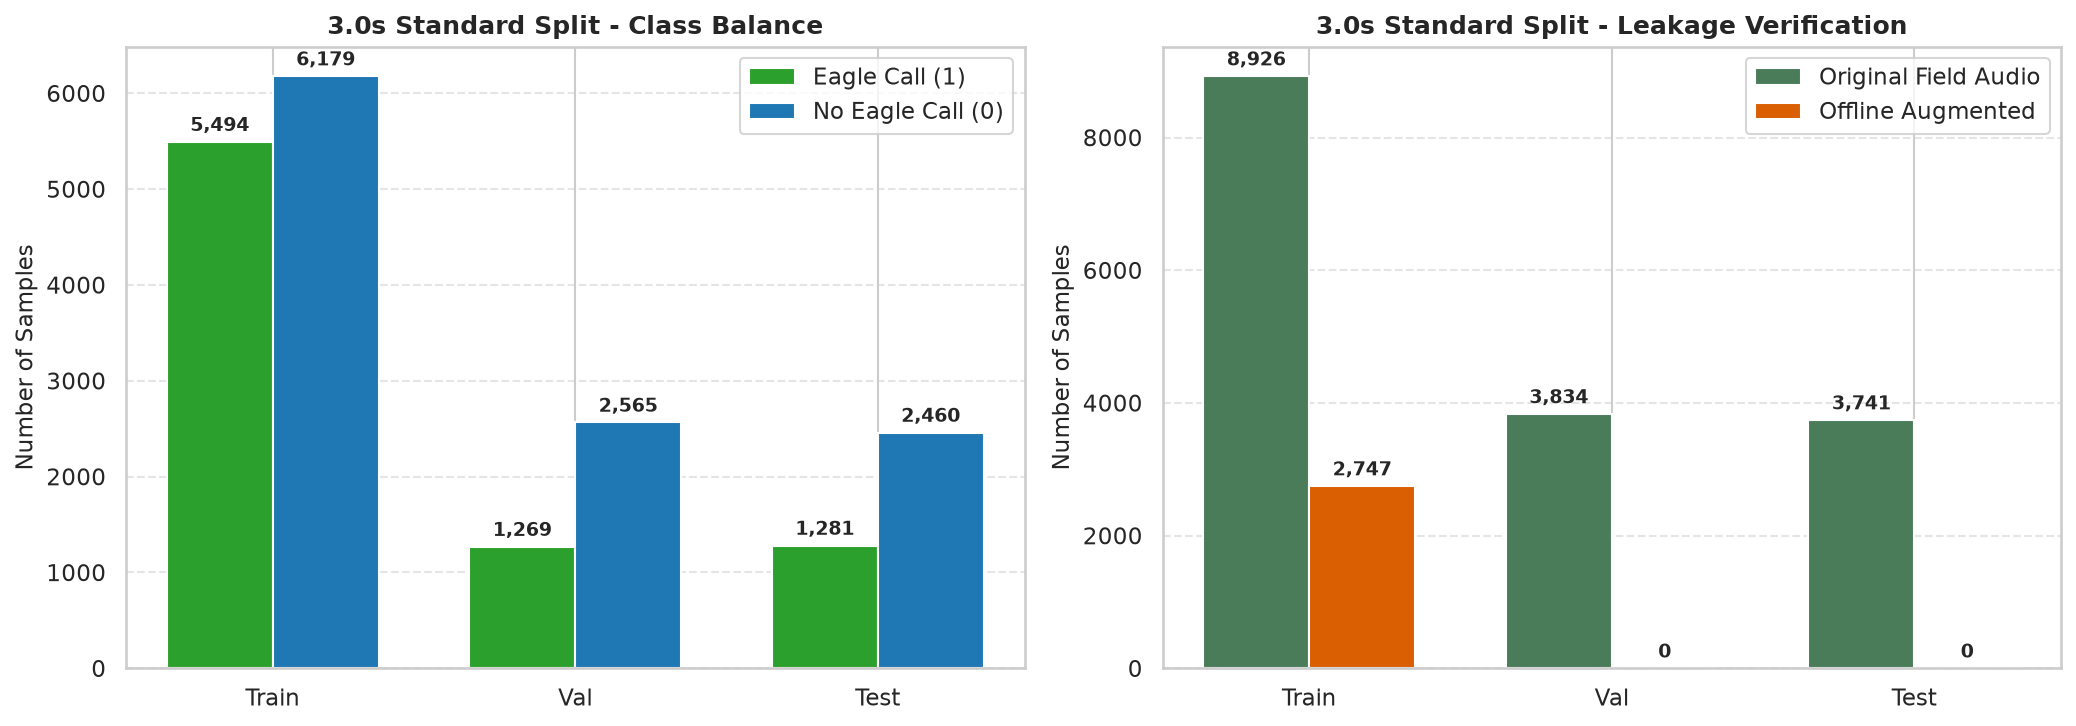

,Split,Total Samples,Eagle Calls (1),Non-Eagle (0),Original Field Audio,Offline Augmented,Unique Audio Sources
0,Train,"11,673","5,494 (47.1%)","6,179 (52.9%)","8,926 (76.5%)","2,747 (23.5%)",404
1,Val,"3,834","1,269 (33.1%)","2,565 (66.9%)","3,834 (100.0%)",0 (0.0%),88
2,Test,"3,741","1,281 (34.2%)","2,460 (65.8%)","3,741 (100.0%)",0 (0.0%),93


In [4]:
# Partition dataset into Train, Val, and Test for 3.0s Standard Split
train_idx_3s_std, val_idx_3s_std, test_idx_3s_std = create_standard_split(df_clean_3s, train_ratio=0.70, val_ratio=0.15, random_state=SEED)

X_train_3s_std = X_all_3s[train_idx_3s_std]
y_train_3s_std = y_all_3s[train_idx_3s_std]

X_val_3s_std = X_all_3s[val_idx_3s_std]
y_val_3s_std = y_all_3s[val_idx_3s_std]

X_test_3s_std = X_all_3s[test_idx_3s_std]
y_test_3s_std = y_all_3s[test_idx_3s_std]

# Display distribution table and save visualization
dist_fig_path_3s_std = FIGURES_DIR / "3s-std-distribution.png"
report_and_plot_split_distribution(
    df_clean_3s,
    train_idx_3s_std,
    val_idx_3s_std,
    test_idx_3s_std,
    experiment_name="3.0s Standard Split",
    save_path=dist_fig_path_3s_std
)

#### 4.1.2 Train or Load Model (3.0s Standard Split)

In [5]:
# Clear previous Keras session and reclaim GPU VRAM
tf.keras.backend.clear_session()
gc.collect()

# Train or load 3.0s Standard Split CRNN-BiGRU-Attention model (Guarded)
model_3s_std_path = MODELS_3S_STD / "crnn-bi-gru-attention-std.keras"
history_3s_std_path = MODELS_3S_STD / "training_history.json"

class_weights_3s_std = compute_class_weights(y_train_3s_std)
print(f"Balanced Class Weights: {class_weights_3s_std}")

if model_3s_std_path.exists():
    print(f"Model already exists at: {model_3s_std_path}")
    print("Loading cached model...")
    model_3s_std = tf.keras.models.load_model(model_3s_std_path)
    with open(history_3s_std_path, "r") as f:
        history_3s_std = json.load(f)
    print("Model and training history loaded successfully from cache!")
else:
    print("Training 3.0s Standard Split CRNN-BiGRU-Attention model with on-the-fly SpecAugment...")
    model_3s_std = build_crnn_bi_gru_attention_model(input_shape=SHAPE_3S, learning_rate=LEARNING_RATE)

    # On-the-fly training generator (Gain jitter + SpecAugment time/freq masking)
    train_gen_3s_std = SpecAugmentDataGenerator(
        X_train_3s_std,
        y_train_3s_std,
        batch_size=BATCH_SIZE,
        is_training=True,
        shuffle=True
    )

    callbacks = [
        tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=PATIENCE, restore_best_weights=True, verbose=1),
        tf.keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=3, min_lr=1e-5, verbose=1),
        tf.keras.callbacks.ModelCheckpoint(str(MODELS_3S_STD / "checkpoints" / "best_model.keras"), monitor="val_loss", save_best_only=True)
    ]

    fit_res = model_3s_std.fit(
        train_gen_3s_std,
        validation_data=(X_val_3s_std, y_val_3s_std),
        epochs=EPOCHS,
        callbacks=callbacks,
        class_weight=class_weights_3s_std,
        verbose=1
    )

    history_3s_std = fit_res.history
    model_3s_std.save(model_3s_std_path)
    with open(history_3s_std_path, "w") as f:
        json.dump(history_3s_std, f)
    print(f"Saved trained model to: {model_3s_std_path}")

Balanced Class Weights: {0: 0.9445703188218159, 1: 1.062340735347652}
Model already exists at: /home/fumei/Documents/MachineLearning/EagleSoundClassification/experiments/crnn-bi-gru-attention-training/models/3-seconds/standard/crnn-bi-gru-attention-std.keras
Loading cached model...


I0000 00:00:1791471941.285177   20200 gpu_device.cc:2043] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 4075 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 4050 Laptop GPU, pci bus id: 0000:01:00.0, compute capability: 8.9


Model and training history loaded successfully from cache!


#### 4.1.3 Training History Visualization (3.0s Standard Split)

Saved training history figure to: /home/fumei/Documents/MachineLearning/EagleSoundClassification/experiments/crnn-bi-gru-attention-training/outputs/training-history/3s-std-training-history.png


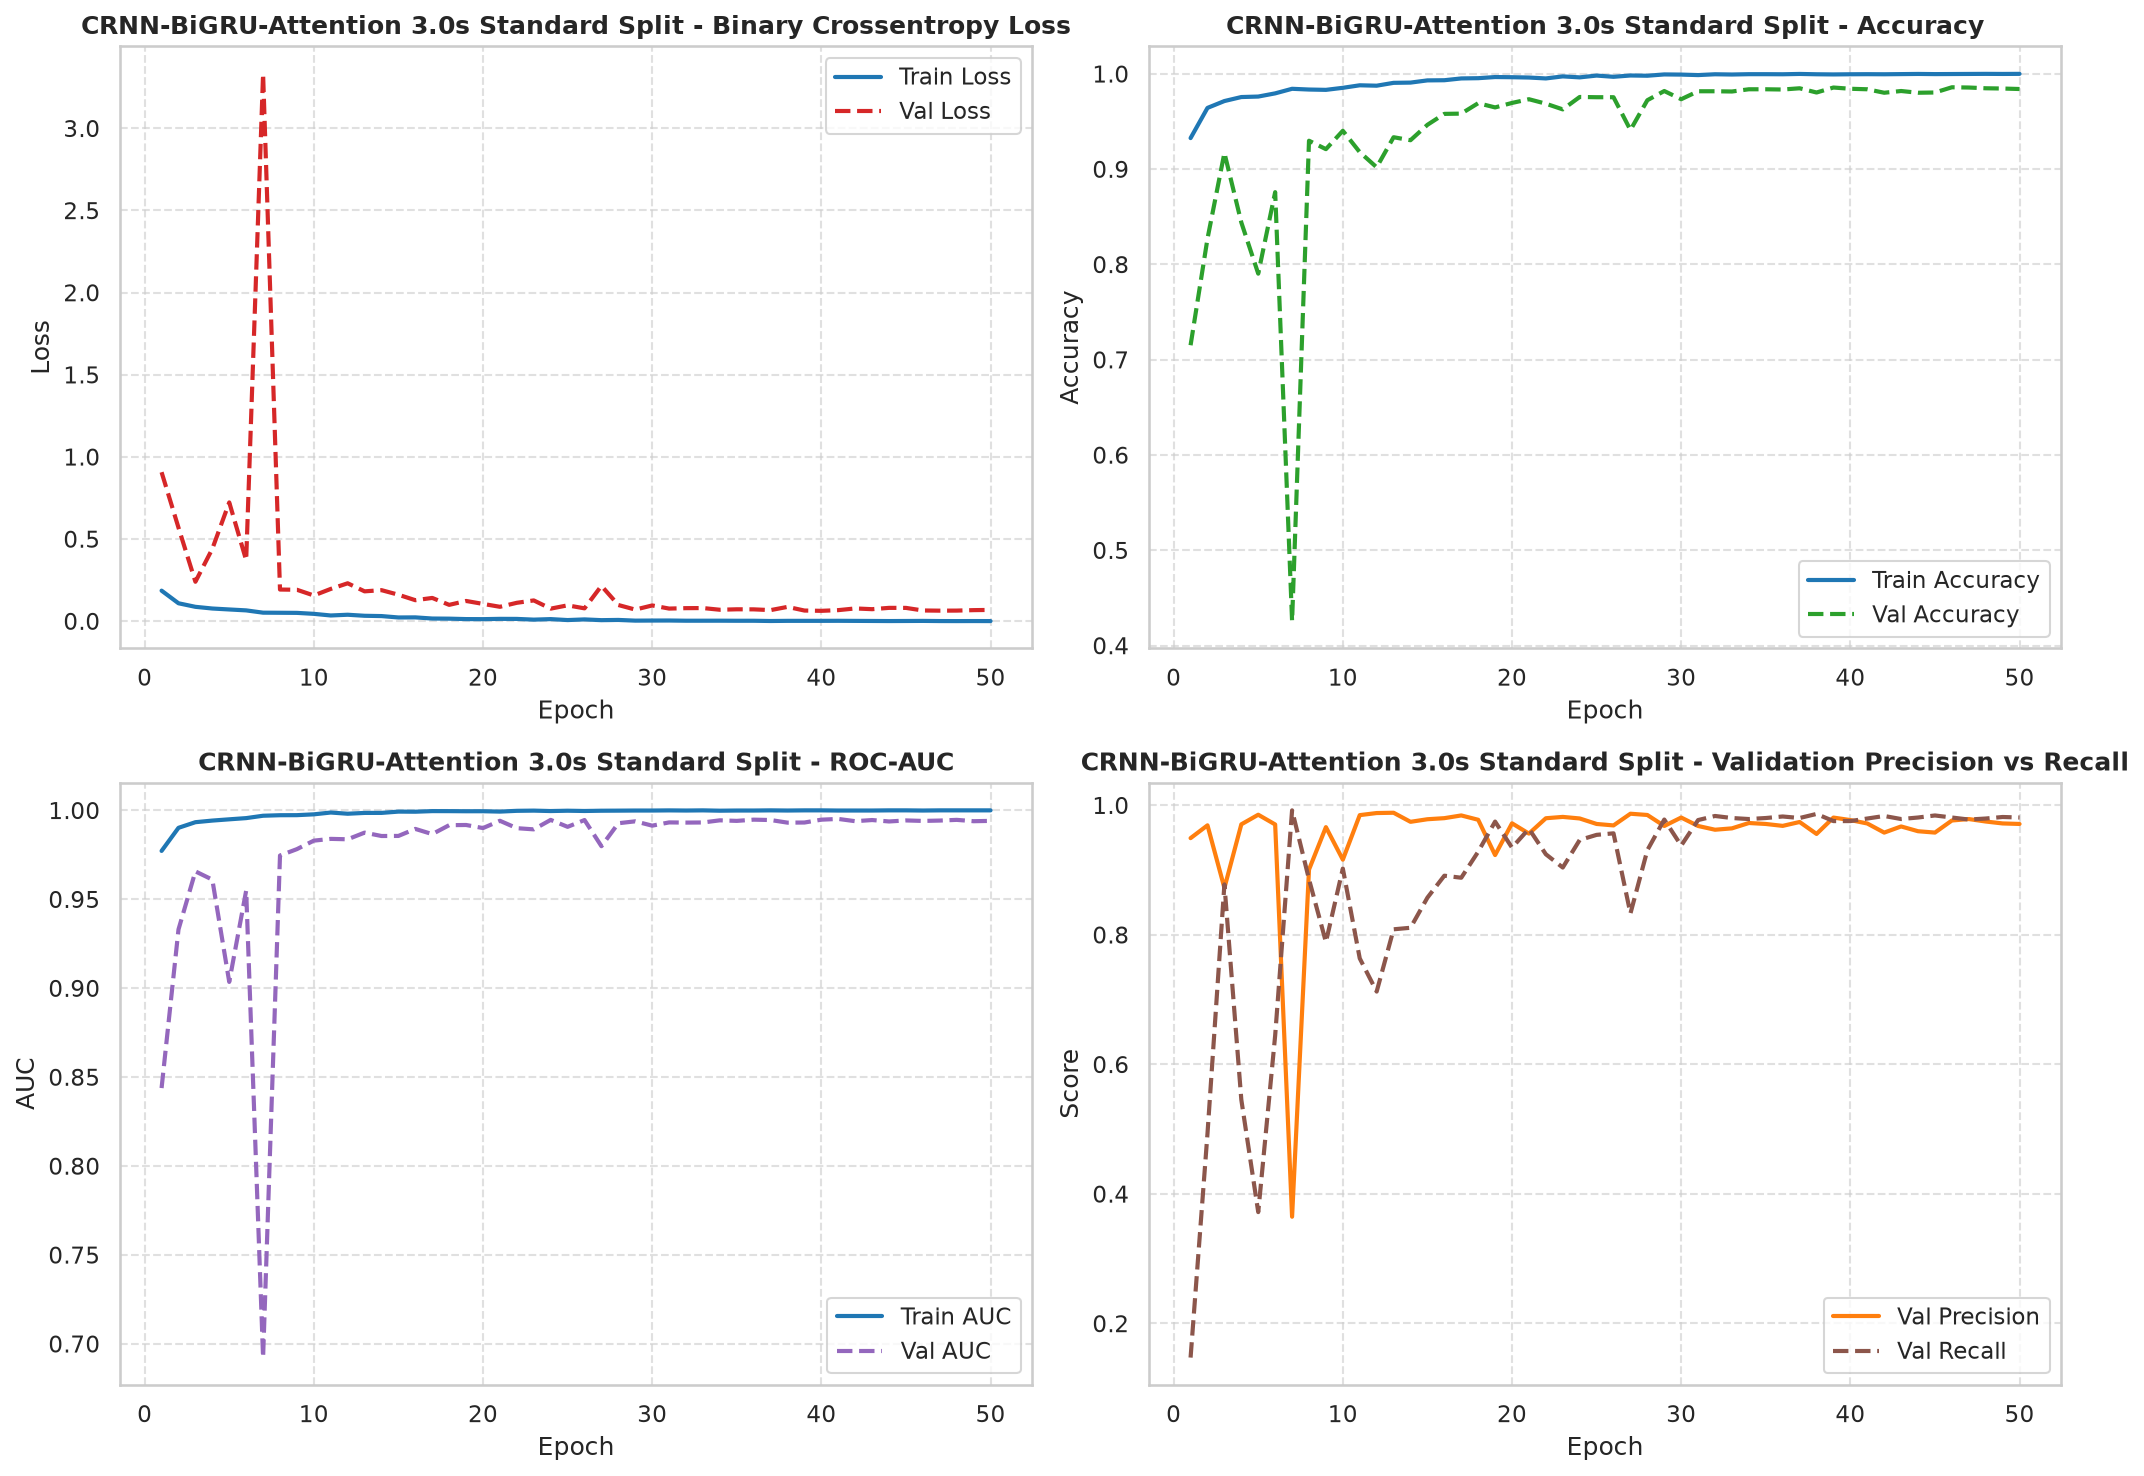

In [6]:
# Visualize training curves (3.0s Standard Split)
history_fig_3s_std = HISTORY_DIR / "3s-std-training-history.png"
plot_training_history(history_3s_std, history_fig_3s_std, title_prefix="CRNN-BiGRU-Attention 3.0s Standard Split")

#### 4.1.4 FP32 Model Evaluation on Test Set (3.0s Standard Split)

I0000 00:00:1791471944.007969   20288 service.cc:153] XLA service 0x7fb7f0051e30 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1791471944.007986   20288 service.cc:161]   StreamExecutor [0]: NVIDIA GeForce RTX 4050 Laptop GPU, Compute Capability 8.9 (Driver: 13.4.0; Runtime: 12.9.0; Toolkit: 12.5.0; DNN: 9.25.1)
I0000 00:00:1791471944.076762   20288 dump_mlir_util.cc:269] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.
I0000 00:00:1791471944.516868   20288 cuda_dnn.cc:461] Loaded cuDNN version 92501
I0000 00:00:1791471944.533216   20288 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_2336__.9
I0000 00:00:1791471946.131750   20366 subprocess_compilation.cc:348] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_17', 8724 bytes spill stores, 8724 bytes spill loads



 34/117 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step

I0000 00:00:1791471949.519220   20288 device_compiler.h:208] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


107/117 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step

I0000 00:00:1791471951.090334   20285 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_4185__.13
I0000 00:00:1791471952.162634   20531 subprocess_compilation.cc:348] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_17', 28 bytes spill stores, 28 bytes spill loads

I0000 00:00:1791471952.214799   20533 subprocess_compilation.cc:348] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_17', 28 bytes spill stores, 28 bytes spill loads

I0000 00:00:1791471952.649628   20536 subprocess_compilation.cc:348] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_17', 9196 bytes spill stores, 9276 bytes spill loads



117/117 ━━━━━━━━━━━━━━━━━━━━ 12s 52ms/step
EVALUATION RESULTS: 3.0s Standard Split (FP32)
Accuracy:    0.9628 (96.28%)
Precision:   0.9665 (96.65%)
Recall:      0.9235 (92.35%)
F1-Score:    0.9445 (94.45%)
Specificity: 0.9833 (98.33%)
ROC-AUC:     0.9833
              precision    recall  f1-score   support

No Eagle (0)       0.96      0.98      0.97      2460
   Eagle (1)       0.97      0.92      0.94      1281

    accuracy                           0.96      3741
   macro avg       0.96      0.95      0.96      3741
weighted avg       0.96      0.96      0.96      3741

Saved confusion matrix to: /home/fumei/Documents/MachineLearning/EagleSoundClassification/experiments/crnn-bi-gru-attention-training/outputs/confusion-matrices/3s-std-confusion-matrix.png


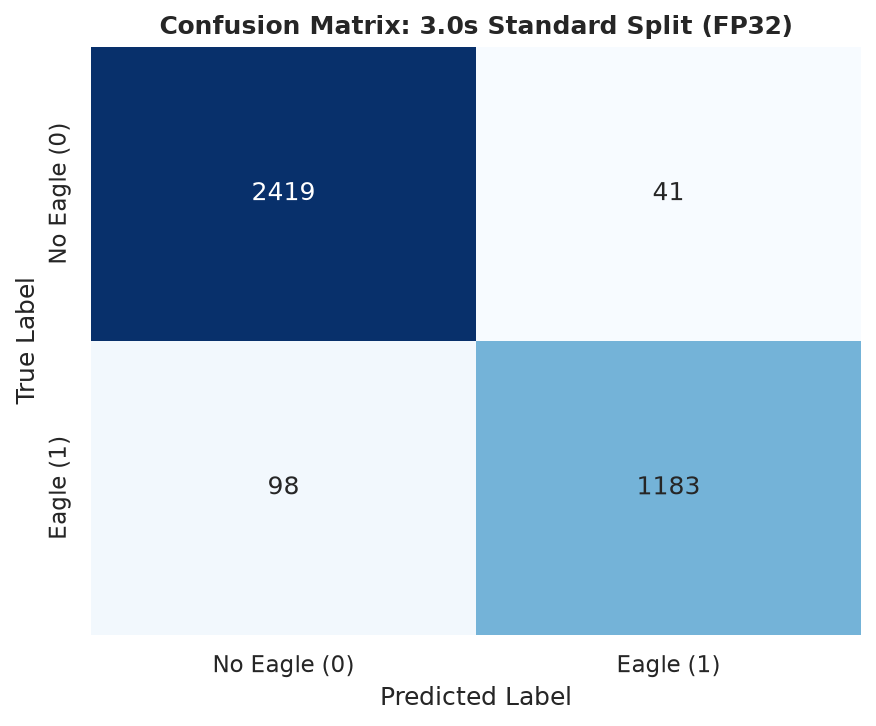

In [7]:
# Evaluate FP32 model on clean test set (3.0s Standard Split)
y_pred_prob_3s_std = model_3s_std.predict(X_test_3s_std, batch_size=BATCH_SIZE).ravel()
cm_fig_3s_std = CONFUSION_DIR / "3s-std-confusion-matrix.png"
metrics_3s_std = evaluate_predictions(y_test_3s_std, y_pred_prob_3s_std, "3.0s Standard Split (FP32)", cm_fig_3s_std)

#### 4.1.5 Edge Quantization Benchmark: Float16 & INT8 (3.0s Standard Split)

In [8]:
# Edge Quantization Benchmark: Float16 & INT8 (3.0s Standard Split, Guarded)
tflite_3s_std_fp16_path = MODELS_3S_STD / "crnn-bi-gru-attention-std-fp16.tflite"
tflite_3s_std_int8_path = MODELS_3S_STD / "crnn-bi-gru-attention-std-int8.tflite"

# 1. Float16 Quantization
if not tflite_3s_std_fp16_path.exists():
    print("Converting model to Float16 TFLite...")
    convert_to_tflite_fp16(model_3s_std, tflite_3s_std_fp16_path)
    print(f"Saved Float16 TFLite model to: {tflite_3s_std_fp16_path}")
else:
    print(f"Loading cached Float16 model from: {tflite_3s_std_fp16_path}")

fp16_res_3s_std = evaluate_tflite_model(tflite_3s_std_fp16_path, X_test_3s_std, y_test_3s_std)

# 2. Full INT8 Quantization
if not tflite_3s_std_int8_path.exists():
    print("Converting model to INT8 TFLite with representative dataset calibration...")
    convert_to_tflite_int8(model_3s_std, X_train_3s_std[:300], tflite_3s_std_int8_path)
    print(f"Saved INT8 TFLite model to: {tflite_3s_std_int8_path}")
else:
    print(f"Loading cached INT8 model from: {tflite_3s_std_int8_path}")

int8_res_3s_std = evaluate_tflite_model(tflite_3s_std_int8_path, X_test_3s_std, y_test_3s_std)

fp32_size_kb = os.path.getsize(model_3s_std_path) / 1024.0
fp16_size_kb = fp16_res_3s_std["model_size_kb"]
int8_size_kb = int8_res_3s_std["model_size_kb"]

print("=" * 75)
print("3.0S STANDARD SPLIT: FP32 vs. FLOAT16 vs. INT8 EDGE BENCHMARK")
print("=" * 75)
print(f"FP32 Model:      Size = {fp32_size_kb:6.1f} KB | Acc = {metrics_3s_std['accuracy']*100:.2f}% | F1 = {metrics_3s_std['f1_score']:.4f}")
print(f"Float16 Model:   Size = {fp16_size_kb:6.1f} KB | Acc = {fp16_res_3s_std['accuracy']*100:.2f}% | F1 = {fp16_res_3s_std['f1_score']:.4f} | Latency = {fp16_res_3s_std['latency_ms']:.2f} ms")
print(f"Full INT8 Model: Size = {int8_size_kb:6.1f} KB | Acc = {int8_res_3s_std['accuracy']*100:.2f}% | F1 = {int8_res_3s_std['f1_score']:.4f} | Latency = {int8_res_3s_std['latency_ms']:.2f} ms")
print("=" * 75)

Loading cached Float16 model from: /home/fumei/Documents/MachineLearning/EagleSoundClassification/experiments/crnn-bi-gru-attention-training/models/3-seconds/standard/crnn-bi-gru-attention-std-fp16.tflite


INFO: Created TensorFlow Lite XNNPACK delegate for CPU.


Loading cached INT8 model from: /home/fumei/Documents/MachineLearning/EagleSoundClassification/experiments/crnn-bi-gru-attention-training/models/3-seconds/standard/crnn-bi-gru-attention-std-int8.tflite
3.0S STANDARD SPLIT: FP32 vs. FLOAT16 vs. INT8 EDGE BENCHMARK
FP32 Model:      Size = 3632.6 KB | Acc = 96.28% | F1 = 0.9445
Float16 Model:   Size =  746.8 KB | Acc = 96.28% | F1 = 0.9445 | Latency = 3.72 ms
Full INT8 Model: Size =  608.6 KB | Acc = 87.65% | F1 = 0.8351 | Latency = 1.82 ms


### 4.2. Experiment 2: Leave-One-Site-Out (LOSO) - Davao del Sur (3.0s)

#### 4.2.1 Partition Dataset and Visualize Distribution (3.0s Leave-One-Site-Out (LOSO) - Davao del Sur)


 Partition Distribution Summary: 3.0s Leave-One-Site-Out (LOSO) - Davao del Sur
Split Total Samples Eagle Calls (1) Non-Eagle (0) Original Field Audio Offline Augmented Unique Audio Sources
Train         6,627   2,798 (42.2%) 3,829 (57.8%)        5,228 (78.9%)     1,399 (21.1%)                  459
  Val           892     246 (27.6%)   646 (72.4%)         892 (100.0%)          0 (0.0%)                   81
 Test         4,964   1,692 (34.1%) 3,272 (65.9%)       4,964 (100.0%)          0 (0.0%)                   22

Saved partition distribution figure to: /home/fumei/Documents/MachineLearning/EagleSoundClassification/experiments/crnn-bi-gru-attention-training/outputs/figures/3s-loso_davao-distribution.png


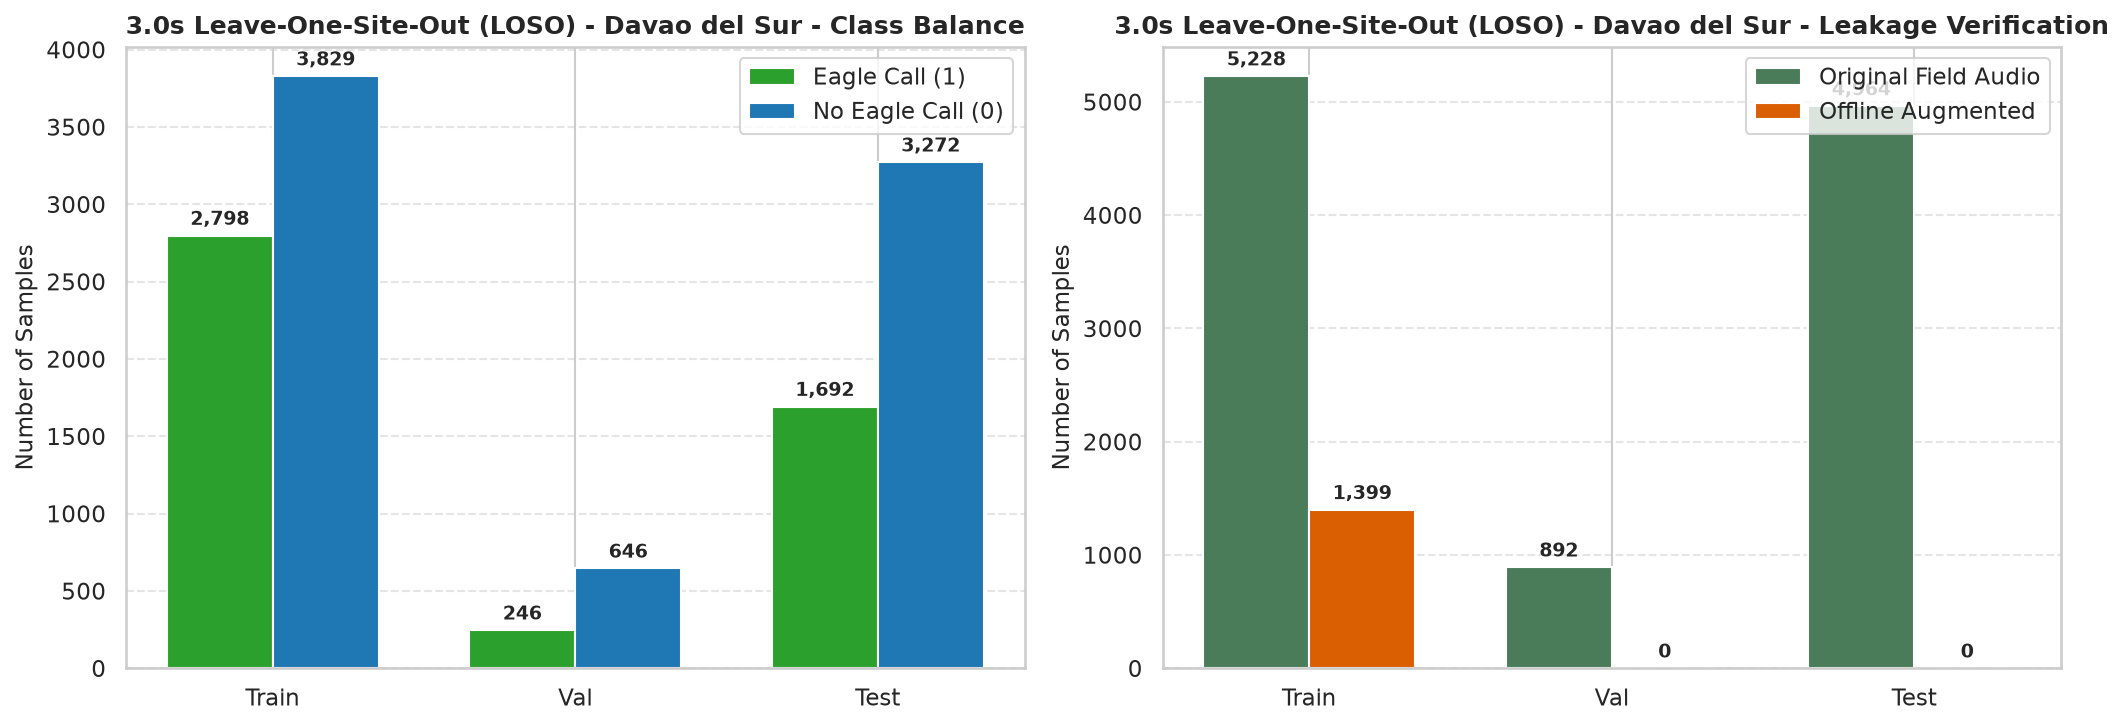

,Split,Total Samples,Eagle Calls (1),Non-Eagle (0),Original Field Audio,Offline Augmented,Unique Audio Sources
0,Train,"6,627","2,798 (42.2%)","3,829 (57.8%)","5,228 (78.9%)","1,399 (21.1%)",459
1,Val,892,246 (27.6%),646 (72.4%),892 (100.0%),0 (0.0%),81
2,Test,"4,964","1,692 (34.1%)","3,272 (65.9%)","4,964 (100.0%)",0 (0.0%),22


In [9]:
# Partition dataset into Train, Val, and Test for 3.0s Leave-One-Site-Out (LOSO) - Davao del Sur
train_idx_3s_loso_davao, val_idx_3s_loso_davao, test_idx_3s_loso_davao = create_loso_split(df_clean_3s, holdout_site='Davao del Sur', val_ratio=0.15, random_state=SEED)

X_train_3s_loso_davao = X_all_3s[train_idx_3s_loso_davao]
y_train_3s_loso_davao = y_all_3s[train_idx_3s_loso_davao]

X_val_3s_loso_davao = X_all_3s[val_idx_3s_loso_davao]
y_val_3s_loso_davao = y_all_3s[val_idx_3s_loso_davao]

X_test_3s_loso_davao = X_all_3s[test_idx_3s_loso_davao]
y_test_3s_loso_davao = y_all_3s[test_idx_3s_loso_davao]

# Display distribution table and save visualization
dist_fig_path_3s_loso_davao = FIGURES_DIR / "3s-loso_davao-distribution.png"
report_and_plot_split_distribution(
    df_clean_3s,
    train_idx_3s_loso_davao,
    val_idx_3s_loso_davao,
    test_idx_3s_loso_davao,
    experiment_name="3.0s Leave-One-Site-Out (LOSO) - Davao del Sur",
    save_path=dist_fig_path_3s_loso_davao
)

#### 4.2.2 Train or Load Model (3.0s Leave-One-Site-Out (LOSO) - Davao del Sur)

In [10]:
# Clear previous Keras session and reclaim GPU VRAM
tf.keras.backend.clear_session()
gc.collect()

# Train or load 3.0s Leave-One-Site-Out (LOSO) - Davao del Sur CRNN-BiGRU-Attention model (Guarded)
model_3s_loso_davao_path = MODELS_3S_LOSO_DAVAO / "crnn-bi-gru-attention-loso_davao.keras"
history_3s_loso_davao_path = MODELS_3S_LOSO_DAVAO / "training_history.json"

class_weights_3s_loso_davao = compute_class_weights(y_train_3s_loso_davao)
print(f"Balanced Class Weights: {class_weights_3s_loso_davao}")

if model_3s_loso_davao_path.exists():
    print(f"Model already exists at: {model_3s_loso_davao_path}")
    print("Loading cached model...")
    model_3s_loso_davao = tf.keras.models.load_model(model_3s_loso_davao_path)
    with open(history_3s_loso_davao_path, "r") as f:
        history_3s_loso_davao = json.load(f)
    print("Model and training history loaded successfully from cache!")
else:
    print("Training 3.0s Leave-One-Site-Out (LOSO) - Davao del Sur CRNN-BiGRU-Attention model with on-the-fly SpecAugment...")
    model_3s_loso_davao = build_crnn_bi_gru_attention_model(input_shape=SHAPE_3S, learning_rate=LEARNING_RATE)

    # On-the-fly training generator (Gain jitter + SpecAugment time/freq masking)
    train_gen_3s_loso_davao = SpecAugmentDataGenerator(
        X_train_3s_loso_davao,
        y_train_3s_loso_davao,
        batch_size=BATCH_SIZE,
        is_training=True,
        shuffle=True
    )

    callbacks = [
        tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=PATIENCE, restore_best_weights=True, verbose=1),
        tf.keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=3, min_lr=1e-5, verbose=1),
        tf.keras.callbacks.ModelCheckpoint(str(MODELS_3S_LOSO_DAVAO / "checkpoints" / "best_model.keras"), monitor="val_loss", save_best_only=True)
    ]

    fit_res = model_3s_loso_davao.fit(
        train_gen_3s_loso_davao,
        validation_data=(X_val_3s_loso_davao, y_val_3s_loso_davao),
        epochs=EPOCHS,
        callbacks=callbacks,
        class_weight=class_weights_3s_loso_davao,
        verbose=1
    )

    history_3s_loso_davao = fit_res.history
    model_3s_loso_davao.save(model_3s_loso_davao_path)
    with open(history_3s_loso_davao_path, "w") as f:
        json.dump(history_3s_loso_davao, f)
    print(f"Saved trained model to: {model_3s_loso_davao_path}")

Balanced Class Weights: {0: 0.8653695481849047, 1: 1.1842387419585418}
Model already exists at: /home/fumei/Documents/MachineLearning/EagleSoundClassification/experiments/crnn-bi-gru-attention-training/models/3-seconds/loso-davao/crnn-bi-gru-attention-loso_davao.keras
Loading cached model...
Model and training history loaded successfully from cache!


#### 4.2.3 Training History Visualization (3.0s Leave-One-Site-Out (LOSO) - Davao del Sur)

Saved training history figure to: /home/fumei/Documents/MachineLearning/EagleSoundClassification/experiments/crnn-bi-gru-attention-training/outputs/training-history/3s-loso_davao-training-history.png


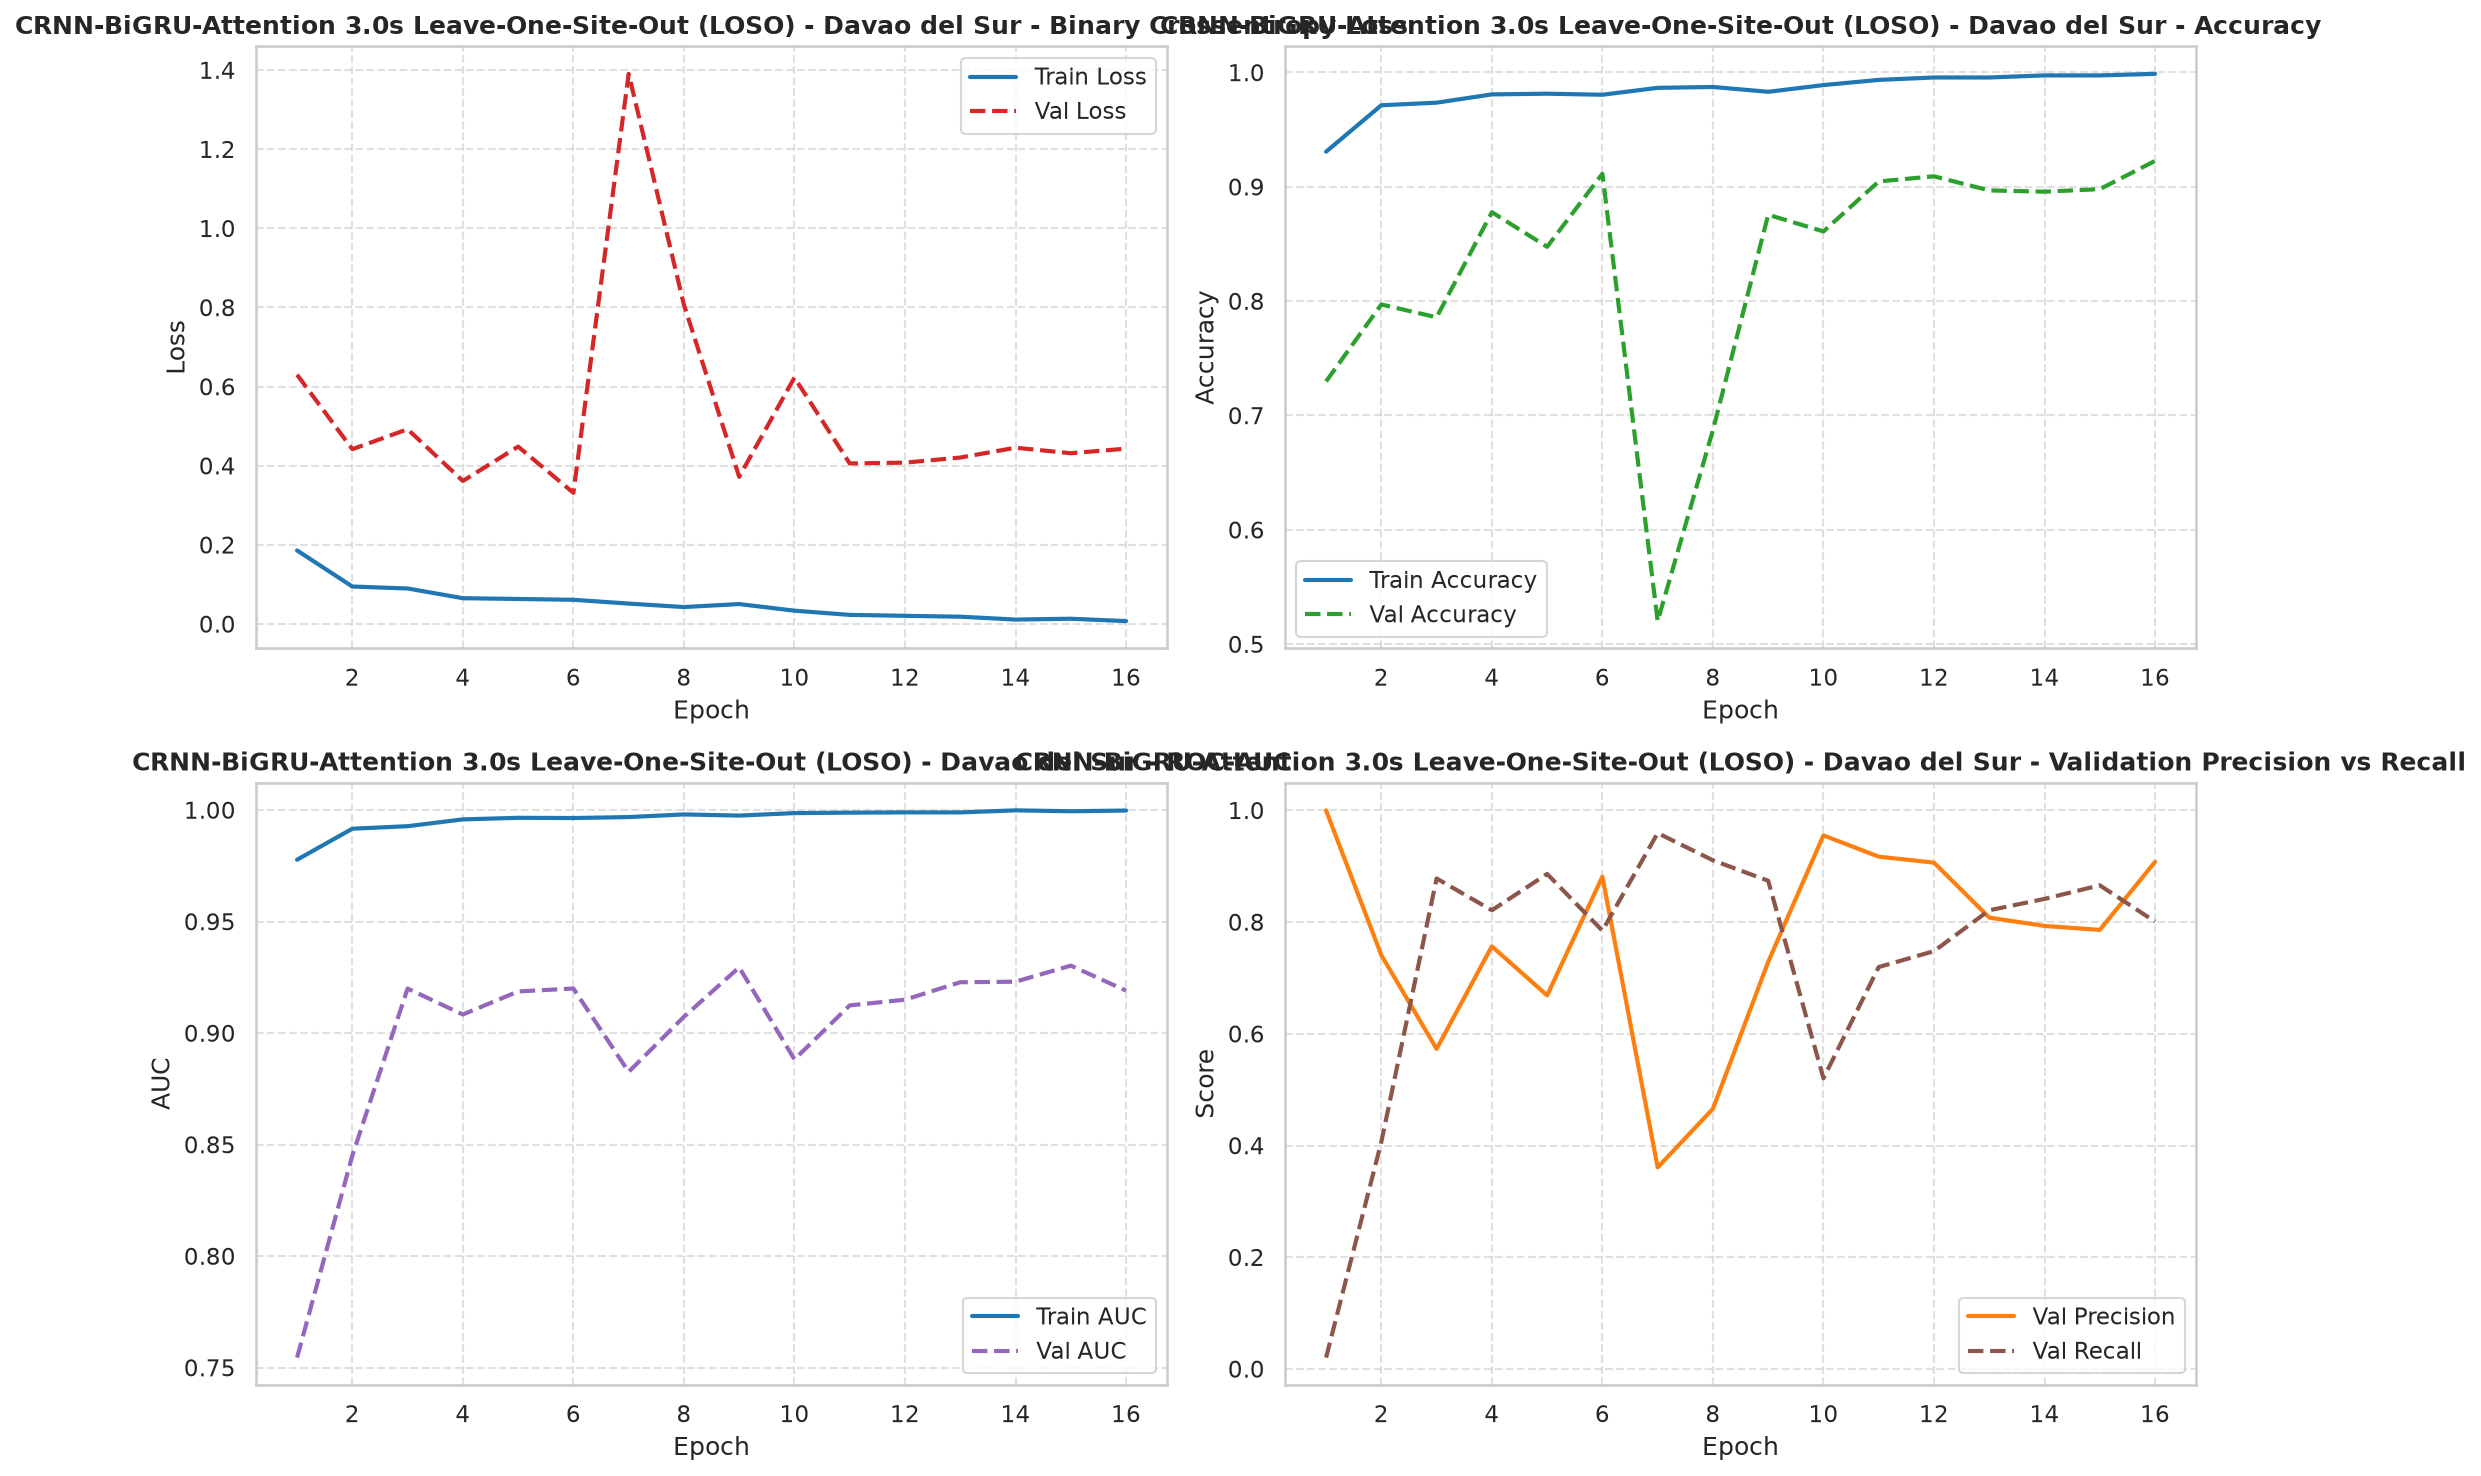

In [11]:
# Visualize training curves (3.0s Leave-One-Site-Out (LOSO) - Davao del Sur)
history_fig_3s_loso_davao = HISTORY_DIR / "3s-loso_davao-training-history.png"
plot_training_history(history_3s_loso_davao, history_fig_3s_loso_davao, title_prefix="CRNN-BiGRU-Attention 3.0s Leave-One-Site-Out (LOSO) - Davao del Sur")

#### 4.2.4 FP32 Model Evaluation on Test Set (3.0s Leave-One-Site-Out (LOSO) - Davao del Sur)

I0000 00:00:1791471980.949859   20285 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_7188__.9


151/156 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step

I0000 00:00:1791471984.036001   20292 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_9115__.13
I0000 00:00:1791471984.957305   20292 dot_search_space.cc:240] All configs were filtered out because none of them sufficiently match the hints. Maybe the hints set does not contain a good representative set of valid configs? Working around this by using the full hints set instead.


156/156 ━━━━━━━━━━━━━━━━━━━━ 9s 39ms/step
EVALUATION RESULTS: 3.0s Leave-One-Site-Out (LOSO) - Davao del Sur (FP32)
Accuracy:    0.8296 (82.96%)
Precision:   0.8439 (84.39%)
Recall:      0.6135 (61.35%)
F1-Score:    0.7105 (71.05%)
Specificity: 0.9413 (94.13%)
ROC-AUC:     0.8838
              precision    recall  f1-score   support

No Eagle (0)       0.82      0.94      0.88      3272
   Eagle (1)       0.84      0.61      0.71      1692

    accuracy                           0.83      4964
   macro avg       0.83      0.78      0.79      4964
weighted avg       0.83      0.83      0.82      4964

Saved confusion matrix to: /home/fumei/Documents/MachineLearning/EagleSoundClassification/experiments/crnn-bi-gru-attention-training/outputs/confusion-matrices/3s-loso_davao-confusion-matrix.png


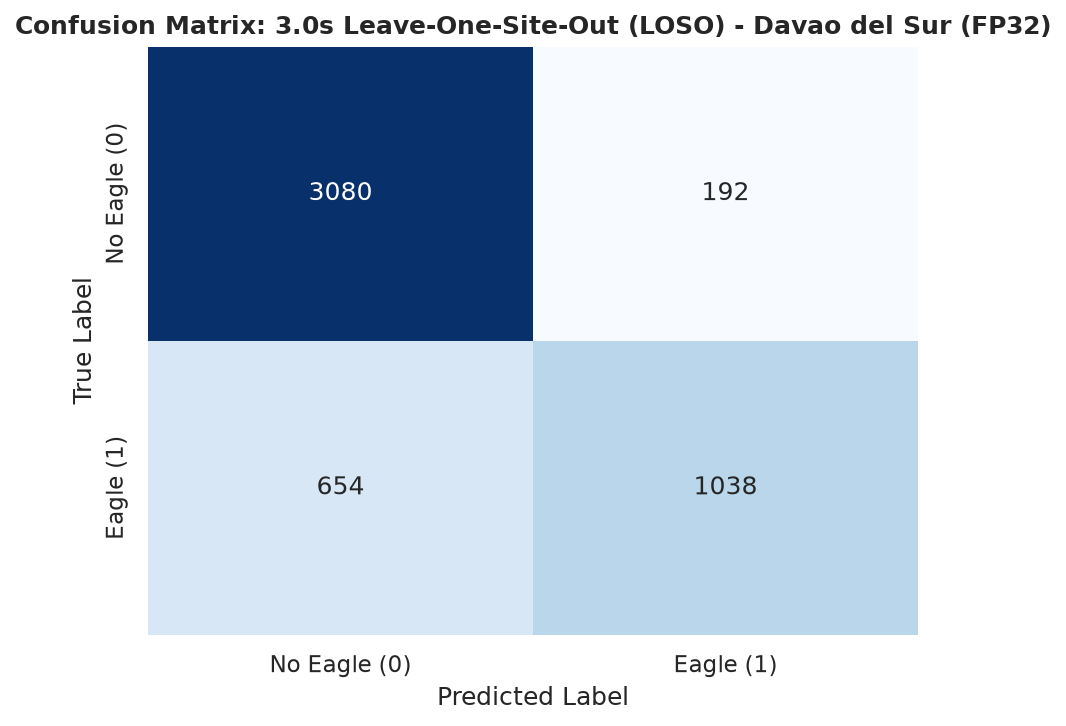

In [12]:
# Evaluate FP32 model on clean test set (3.0s Leave-One-Site-Out (LOSO) - Davao del Sur)
y_pred_prob_3s_loso_davao = model_3s_loso_davao.predict(X_test_3s_loso_davao, batch_size=BATCH_SIZE).ravel()
cm_fig_3s_loso_davao = CONFUSION_DIR / "3s-loso_davao-confusion-matrix.png"
metrics_3s_loso_davao = evaluate_predictions(y_test_3s_loso_davao, y_pred_prob_3s_loso_davao, "3.0s Leave-One-Site-Out (LOSO) - Davao del Sur (FP32)", cm_fig_3s_loso_davao)

### 4.3. Experiment 3: Leave-One-Site-Out (LOSO) - Cotabato (3.0s)

#### 4.3.1 Partition Dataset and Visualize Distribution (3.0s Leave-One-Site-Out (LOSO) - Cotabato)


 Partition Distribution Summary: 3.0s Leave-One-Site-Out (LOSO) - Cotabato
Split Total Samples Eagle Calls (1) Non-Eagle (0) Original Field Audio Offline Augmented Unique Audio Sources
Train         7,703   3,024 (39.3%) 4,679 (60.7%)        6,191 (80.4%)     1,512 (19.6%)                  450
  Val         1,491     344 (23.1%) 1,147 (76.9%)       1,491 (100.0%)          0 (0.0%)                   80
 Test         3,402   1,481 (43.5%) 1,921 (56.5%)       3,402 (100.0%)          0 (0.0%)                   32

Saved partition distribution figure to: /home/fumei/Documents/MachineLearning/EagleSoundClassification/experiments/crnn-bi-gru-attention-training/outputs/figures/3s-loso_cotabato-distribution.png


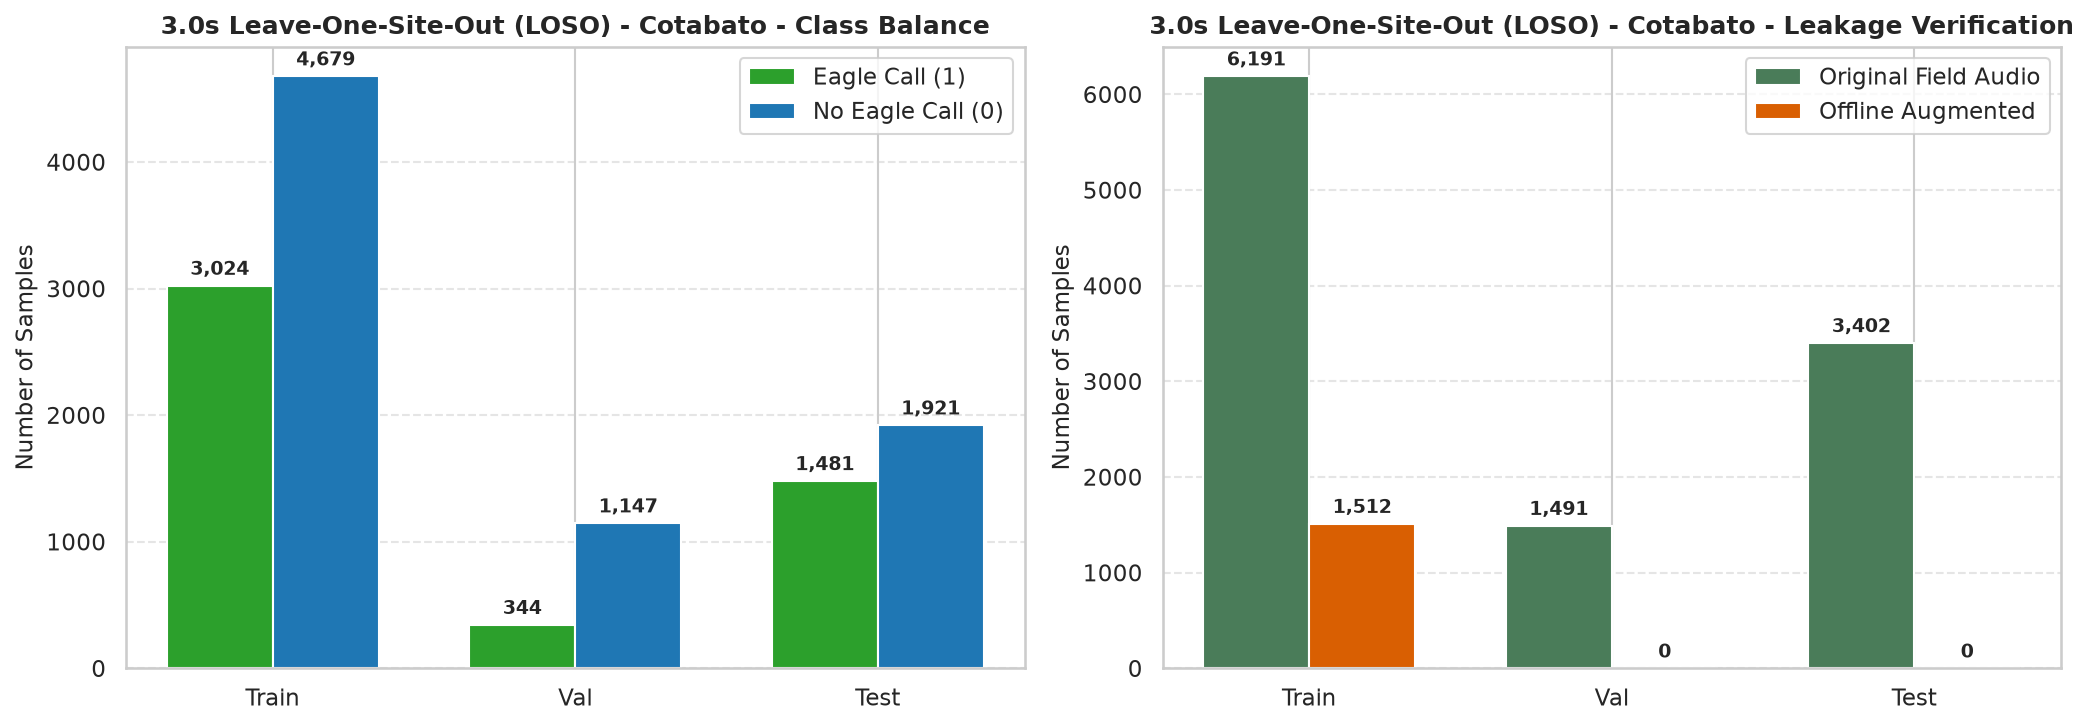

,Split,Total Samples,Eagle Calls (1),Non-Eagle (0),Original Field Audio,Offline Augmented,Unique Audio Sources
0,Train,"7,703","3,024 (39.3%)","4,679 (60.7%)","6,191 (80.4%)","1,512 (19.6%)",450
1,Val,"1,491",344 (23.1%),"1,147 (76.9%)","1,491 (100.0%)",0 (0.0%),80
2,Test,"3,402","1,481 (43.5%)","1,921 (56.5%)","3,402 (100.0%)",0 (0.0%),32


In [13]:
# Partition dataset into Train, Val, and Test for 3.0s Leave-One-Site-Out (LOSO) - Cotabato
train_idx_3s_loso_cotabato, val_idx_3s_loso_cotabato, test_idx_3s_loso_cotabato = create_loso_split(df_clean_3s, holdout_site='Cotabato', val_ratio=0.15, random_state=SEED)

X_train_3s_loso_cotabato = X_all_3s[train_idx_3s_loso_cotabato]
y_train_3s_loso_cotabato = y_all_3s[train_idx_3s_loso_cotabato]

X_val_3s_loso_cotabato = X_all_3s[val_idx_3s_loso_cotabato]
y_val_3s_loso_cotabato = y_all_3s[val_idx_3s_loso_cotabato]

X_test_3s_loso_cotabato = X_all_3s[test_idx_3s_loso_cotabato]
y_test_3s_loso_cotabato = y_all_3s[test_idx_3s_loso_cotabato]

# Display distribution table and save visualization
dist_fig_path_3s_loso_cotabato = FIGURES_DIR / "3s-loso_cotabato-distribution.png"
report_and_plot_split_distribution(
    df_clean_3s,
    train_idx_3s_loso_cotabato,
    val_idx_3s_loso_cotabato,
    test_idx_3s_loso_cotabato,
    experiment_name="3.0s Leave-One-Site-Out (LOSO) - Cotabato",
    save_path=dist_fig_path_3s_loso_cotabato
)

#### 4.3.2 Train or Load Model (3.0s Leave-One-Site-Out (LOSO) - Cotabato)

In [14]:
# Clear previous Keras session and reclaim GPU VRAM
tf.keras.backend.clear_session()
gc.collect()

# Train or load 3.0s Leave-One-Site-Out (LOSO) - Cotabato CRNN-BiGRU-Attention model (Guarded)
model_3s_loso_cotabato_path = MODELS_3S_LOSO_COTABATO / "crnn-bi-gru-attention-loso_cotabato.keras"
history_3s_loso_cotabato_path = MODELS_3S_LOSO_COTABATO / "training_history.json"

class_weights_3s_loso_cotabato = compute_class_weights(y_train_3s_loso_cotabato)
print(f"Balanced Class Weights: {class_weights_3s_loso_cotabato}")

if model_3s_loso_cotabato_path.exists():
    print(f"Model already exists at: {model_3s_loso_cotabato_path}")
    print("Loading cached model...")
    model_3s_loso_cotabato = tf.keras.models.load_model(model_3s_loso_cotabato_path)
    with open(history_3s_loso_cotabato_path, "r") as f:
        history_3s_loso_cotabato = json.load(f)
    print("Model and training history loaded successfully from cache!")
else:
    print("Training 3.0s Leave-One-Site-Out (LOSO) - Cotabato CRNN-BiGRU-Attention model with on-the-fly SpecAugment...")
    model_3s_loso_cotabato = build_crnn_bi_gru_attention_model(input_shape=SHAPE_3S, learning_rate=LEARNING_RATE)

    # On-the-fly training generator (Gain jitter + SpecAugment time/freq masking)
    train_gen_3s_loso_cotabato = SpecAugmentDataGenerator(
        X_train_3s_loso_cotabato,
        y_train_3s_loso_cotabato,
        batch_size=BATCH_SIZE,
        is_training=True,
        shuffle=True
    )

    callbacks = [
        tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=PATIENCE, restore_best_weights=True, verbose=1),
        tf.keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=3, min_lr=1e-5, verbose=1),
        tf.keras.callbacks.ModelCheckpoint(str(MODELS_3S_LOSO_COTABATO / "checkpoints" / "best_model.keras"), monitor="val_loss", save_best_only=True)
    ]

    fit_res = model_3s_loso_cotabato.fit(
        train_gen_3s_loso_cotabato,
        validation_data=(X_val_3s_loso_cotabato, y_val_3s_loso_cotabato),
        epochs=EPOCHS,
        callbacks=callbacks,
        class_weight=class_weights_3s_loso_cotabato,
        verbose=1
    )

    history_3s_loso_cotabato = fit_res.history
    model_3s_loso_cotabato.save(model_3s_loso_cotabato_path)
    with open(history_3s_loso_cotabato_path, "w") as f:
        json.dump(history_3s_loso_cotabato, f)
    print(f"Saved trained model to: {model_3s_loso_cotabato_path}")

Balanced Class Weights: {0: 0.823145971361402, 1: 1.2736441798941798}
Model already exists at: /home/fumei/Documents/MachineLearning/EagleSoundClassification/experiments/crnn-bi-gru-attention-training/models/3-seconds/loso-cotabato/crnn-bi-gru-attention-loso_cotabato.keras
Loading cached model...
Model and training history loaded successfully from cache!


#### 4.3.3 Training History Visualization (3.0s Leave-One-Site-Out (LOSO) - Cotabato)

Saved training history figure to: /home/fumei/Documents/MachineLearning/EagleSoundClassification/experiments/crnn-bi-gru-attention-training/outputs/training-history/3s-loso_cotabato-training-history.png


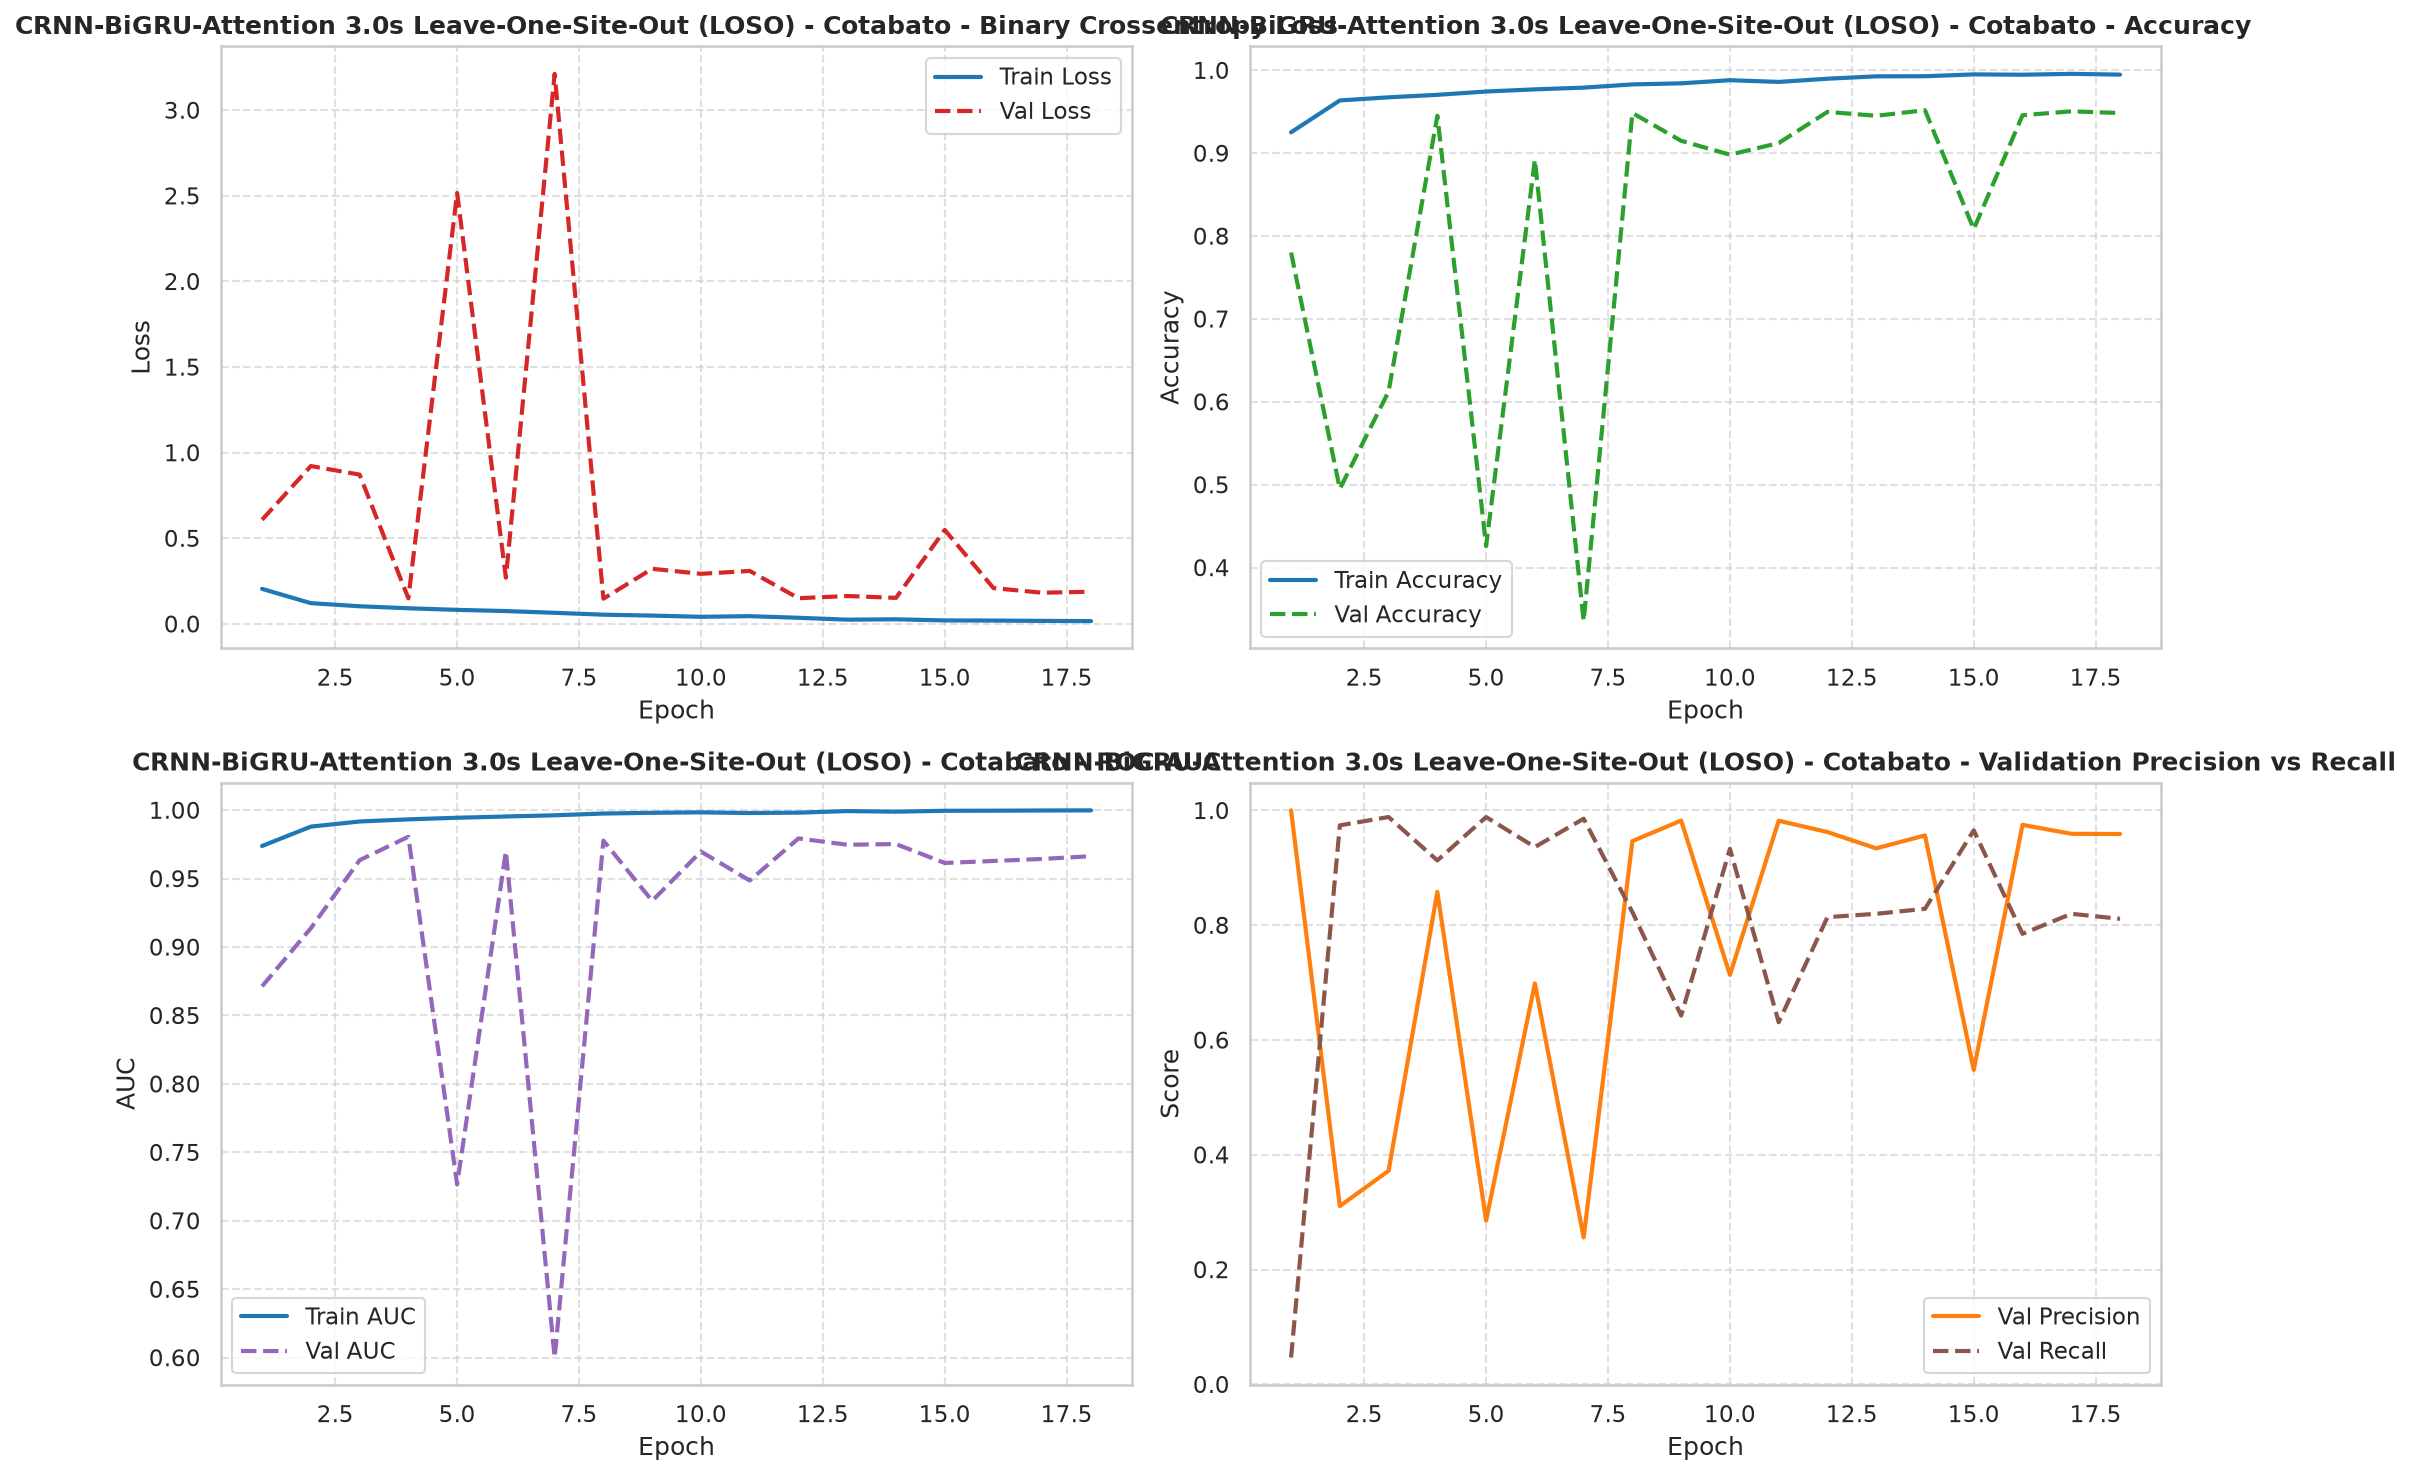

In [15]:
# Visualize training curves (3.0s Leave-One-Site-Out (LOSO) - Cotabato)
history_fig_3s_loso_cotabato = HISTORY_DIR / "3s-loso_cotabato-training-history.png"
plot_training_history(history_3s_loso_cotabato, history_fig_3s_loso_cotabato, title_prefix="CRNN-BiGRU-Attention 3.0s Leave-One-Site-Out (LOSO) - Cotabato")

#### 4.3.4 FP32 Model Evaluation on Test Set (3.0s Leave-One-Site-Out (LOSO) - Cotabato)

I0000 00:00:1791471992.845270   20288 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_12313__.9


 98/107 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step

I0000 00:00:1791471995.700539   20288 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_14142__.13
I0000 00:00:1791471996.826189   21009 subprocess_compilation.cc:348] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_17', 8992 bytes spill stores, 8980 bytes spill loads



107/107 ━━━━━━━━━━━━━━━━━━━━ 8s 53ms/step
EVALUATION RESULTS: 3.0s Leave-One-Site-Out (LOSO) - Cotabato (FP32)
Accuracy:    0.8521 (85.21%)
Precision:   0.9528 (95.28%)
Recall:      0.6948 (69.48%)
F1-Score:    0.8036 (80.36%)
Specificity: 0.9735 (97.35%)
ROC-AUC:     0.9104
              precision    recall  f1-score   support

No Eagle (0)       0.81      0.97      0.88      1921
   Eagle (1)       0.95      0.69      0.80      1481

    accuracy                           0.85      3402
   macro avg       0.88      0.83      0.84      3402
weighted avg       0.87      0.85      0.85      3402

Saved confusion matrix to: /home/fumei/Documents/MachineLearning/EagleSoundClassification/experiments/crnn-bi-gru-attention-training/outputs/confusion-matrices/3s-loso_cotabato-confusion-matrix.png


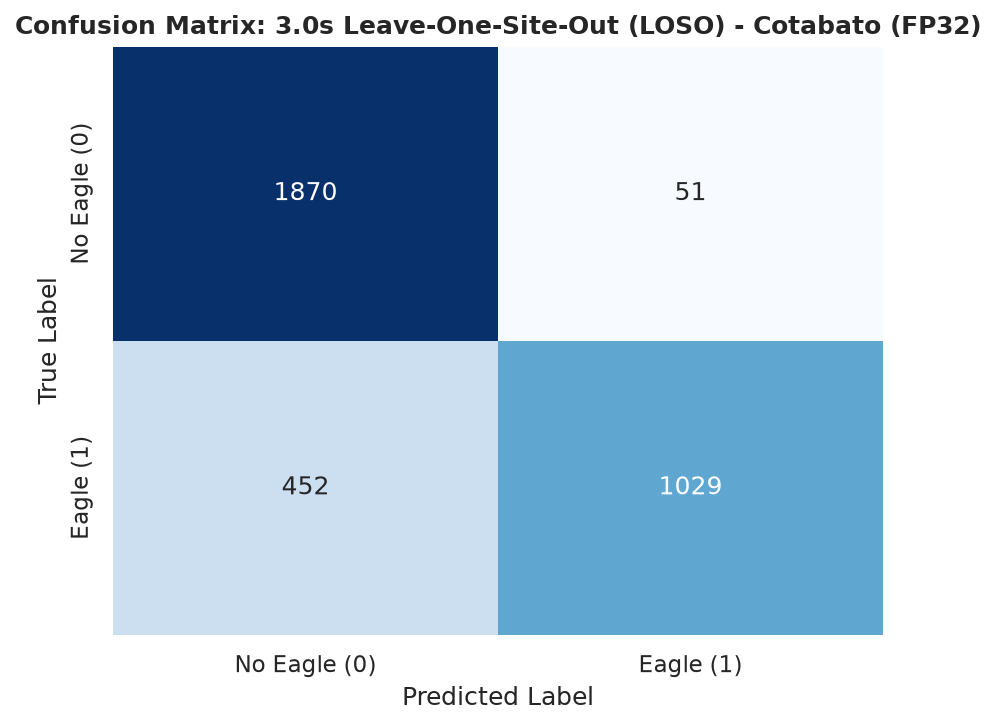

In [16]:
# Evaluate FP32 model on clean test set (3.0s Leave-One-Site-Out (LOSO) - Cotabato)
y_pred_prob_3s_loso_cotabato = model_3s_loso_cotabato.predict(X_test_3s_loso_cotabato, batch_size=BATCH_SIZE).ravel()
cm_fig_3s_loso_cotabato = CONFUSION_DIR / "3s-loso_cotabato-confusion-matrix.png"
metrics_3s_loso_cotabato = evaluate_predictions(y_test_3s_loso_cotabato, y_pred_prob_3s_loso_cotabato, "3.0s Leave-One-Site-Out (LOSO) - Cotabato (FP32)", cm_fig_3s_loso_cotabato)

### 4.4. Temporal Attention Weight Visualization (3s Models)

#### 4.4.1 Visualize Spectrogram with Learned Temporal Attention Curve (3s Standard Split)

Saved temporal attention profile figure to: /home/fumei/Documents/MachineLearning/EagleSoundClassification/experiments/crnn-bi-gru-attention-training/outputs/figures/3s-attention-weight-profile.png


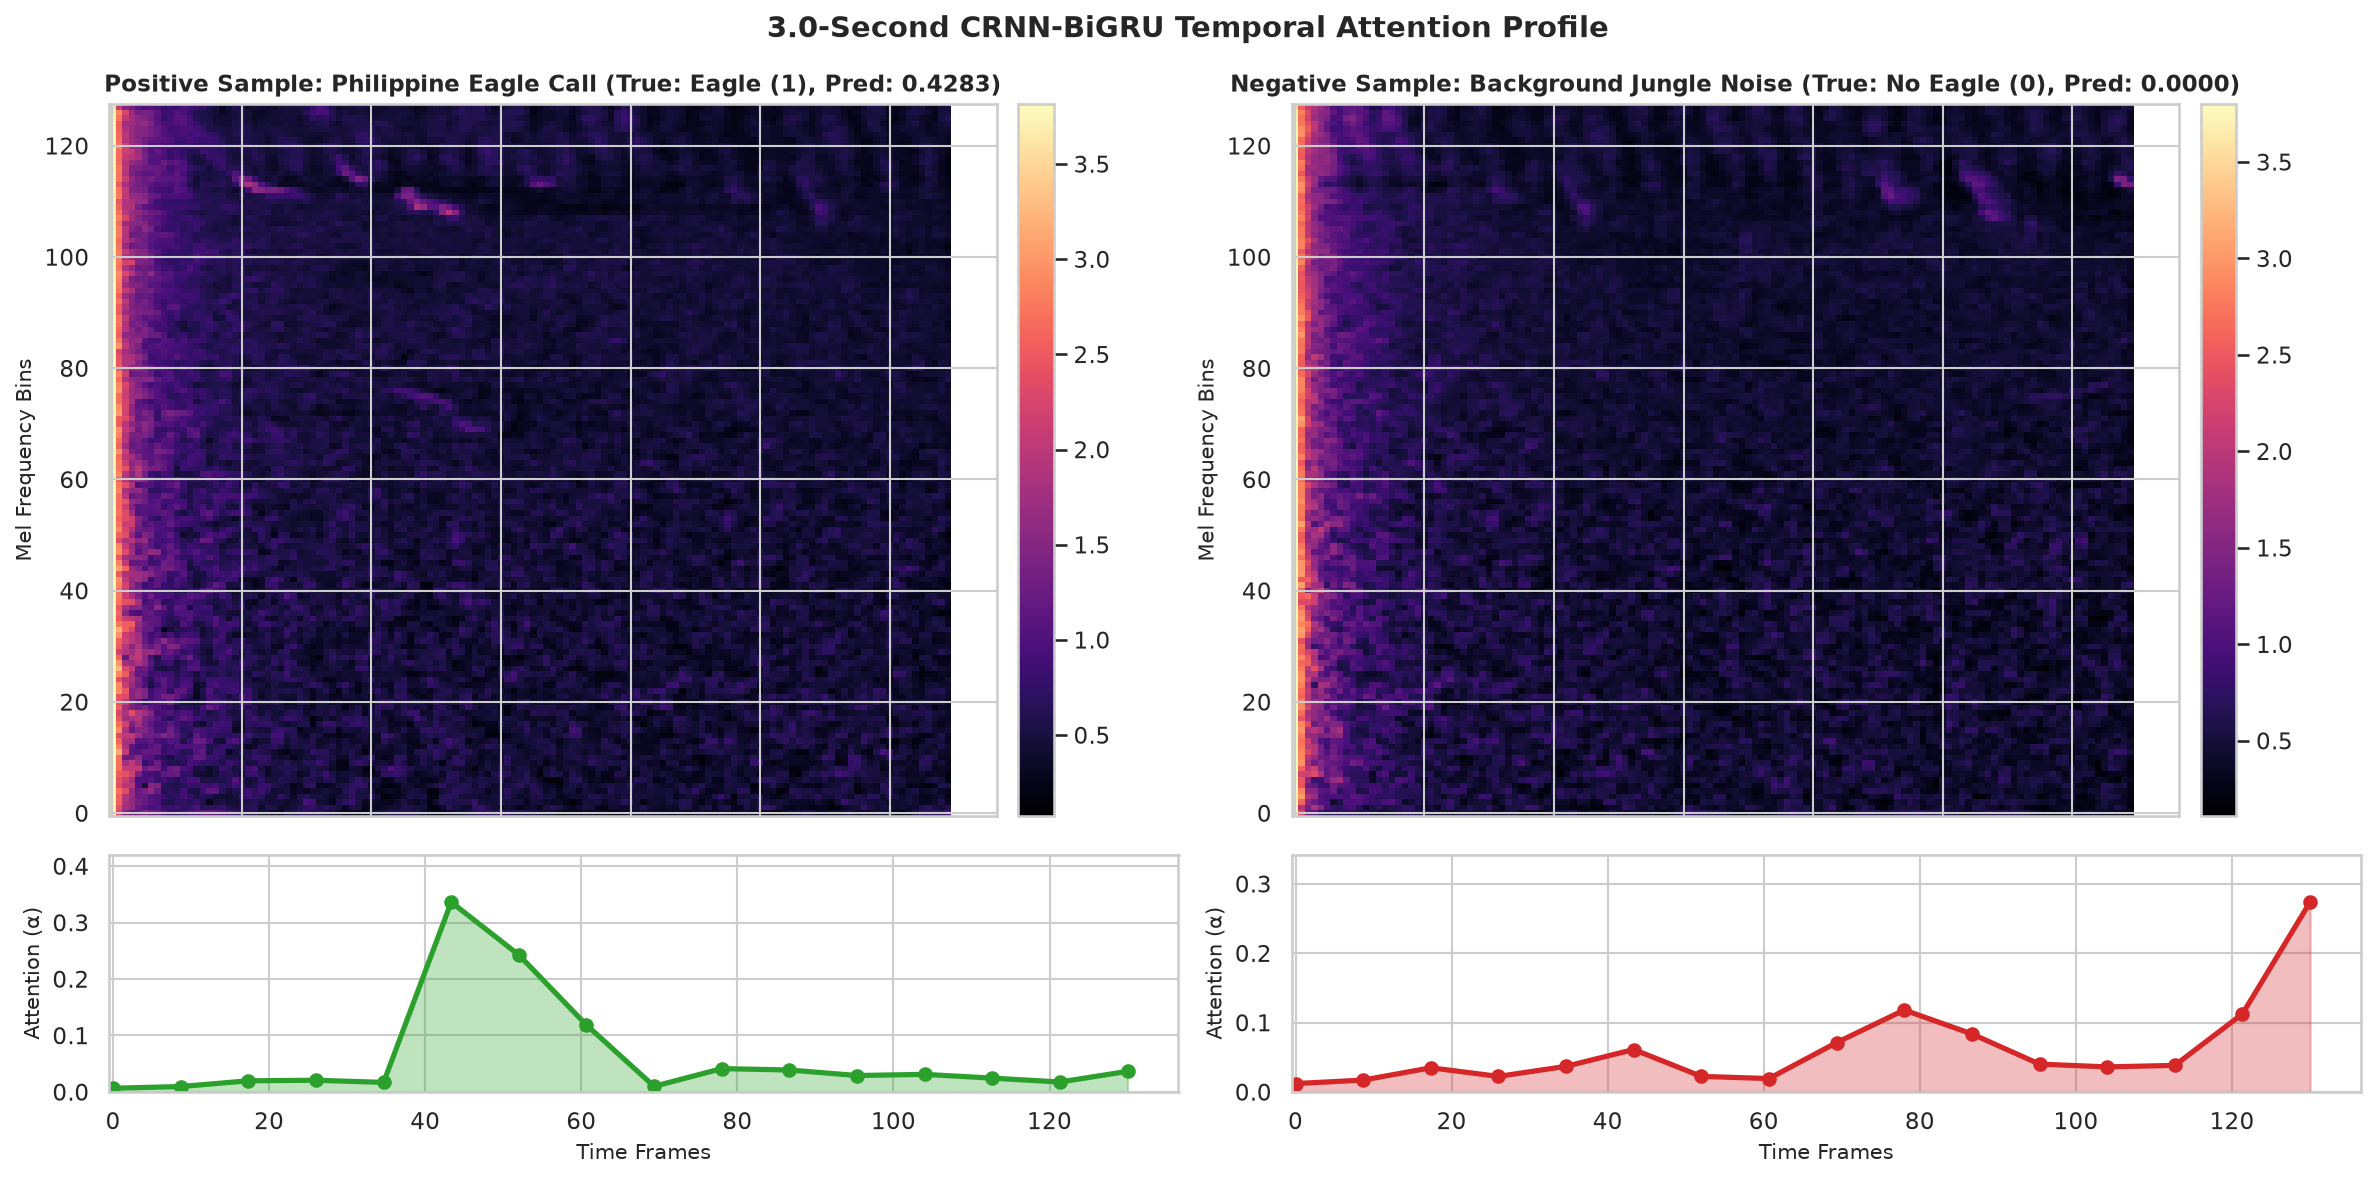

In [17]:
# 4.4.1 Visualize Spectrogram with Learned Temporal Attention Curve
# Extract attention sub-model from the trained Standard Split model
attention_extractor = tf.keras.Model(
    inputs=model_3s_std.input,
    outputs=[model_3s_std.output, model_3s_std.get_layer("temporal_attention_weights").output]
)

# Select positive eagle call sample and negative sample from test set
pos_indices = np.where(y_test_3s_std == 1.0)[0]
neg_indices = np.where(y_test_3s_std == 0.0)[0]

sample_pos_idx = pos_indices[0] if len(pos_indices) > 0 else 0
sample_neg_idx = neg_indices[0] if len(neg_indices) > 0 else 0

fig, axes = plt.subplots(2, 2, figsize=(16, 8), sharex=True, gridspec_kw={"height_ratios": [3, 1]})

for col_idx, (sample_idx, title, true_label) in enumerate([
    (sample_pos_idx, "Positive Sample: Philippine Eagle Call", "Eagle (1)"),
    (sample_neg_idx, "Negative Sample: Background Jungle Noise", "No Eagle (0)")
]):
    sample_feat = X_test_3s_std[sample_idx:sample_idx+1]
    pred_prob, attn_weights_val = attention_extractor.predict(sample_feat, verbose=0)
    prob_scalar = float(pred_prob[0, 0])
    weights_scalar = attn_weights_val[0]

    # Top: Spectrogram
    ax_spec = axes[0, col_idx]
    im = ax_spec.imshow(
        sample_feat[0, :, :, 0],
        aspect="auto",
        origin="lower",
        cmap="magma"
    )
    ax_spec.set_title(f"{title} (True: {true_label}, Pred: {prob_scalar:.4f})", fontweight="bold", fontsize=11)
    ax_spec.set_ylabel("Mel Frequency Bins", fontsize=10)
    plt.colorbar(im, ax=ax_spec, pad=0.02, format="%.1f")

    # Bottom: Attention Curve
    ax_attn = axes[1, col_idx]
    time_frames = np.linspace(0, sample_feat.shape[2], len(weights_scalar))
    line_color = "#2ca02c" if col_idx == 0 else "#d62728"
    ax_attn.plot(time_frames, weights_scalar, color=line_color, lw=2.5, marker="o")
    ax_attn.fill_between(time_frames, 0, weights_scalar, color=line_color, alpha=0.3)
    ax_attn.set_ylabel("Attention (α)", fontsize=10)
    ax_attn.set_xlabel("Time Frames", fontsize=10)
    ax_attn.set_ylim(0, max(0.2, float(np.max(weights_scalar)) * 1.25))

plt.suptitle(f"3.0-Second CRNN-BiGRU Temporal Attention Profile", fontsize=14, fontweight="bold", y=0.98)
plt.tight_layout()
attn_fig_path = FIGURES_DIR / f"3s-attention-weight-profile.png"
fig.savefig(attn_fig_path, dpi=300, bbox_inches="tight")
print(f"Saved temporal attention profile figure to: {attn_fig_path}")
plt.show()

### 4.5. Experiment 5: Standard Split with Focal Loss (γ = 2.0, α = 0.25) (3.0s)

#### 4.5.1 Train or Load Focal Loss Model (3.0s Standard Split)

In [18]:
# Clear previous Keras session and reclaim GPU VRAM
tf.keras.backend.clear_session()
gc.collect()

MODELS_3S_FOCAL = MODELS_DIR / "3-seconds" / "focal-loss"
(MODELS_3S_FOCAL / "checkpoints").mkdir(parents=True, exist_ok=True)
model_3s_focal_path = MODELS_3S_FOCAL / "crnn-bi-gru-attention-3s-focal.keras"
ckpt_3s_focal_path = MODELS_3S_FOCAL / "checkpoints" / "best_model.keras"
hist_3s_focal_path = MODELS_3S_FOCAL / "training_history.json"

train_gen_3s_focal = SpecAugmentDataGenerator(
    X_train_3s_std, y_train_3s_std, batch_size=BATCH_SIZE, is_training=True
)

if not model_3s_focal_path.exists():
    print("Initializing CRNN-BiGRU-Attention with Focal Loss (gamma=2.0, alpha=0.25)...")
    model_3s_focal = build_crnn_bi_gru_attention_model(SHAPE_3S, learning_rate=LEARNING_RATE)
    focal_loss_fn = tf.keras.losses.BinaryFocalCrossentropy(gamma=2.0, alpha=0.25)
    model_3s_focal.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=LEARNING_RATE, clipnorm=1.0),
        loss=focal_loss_fn,
        metrics=["accuracy", tf.keras.metrics.AUC(name="auc"), tf.keras.metrics.Precision(name="precision"), tf.keras.metrics.Recall(name="recall")]
    )

    callbacks_3s_focal = [
        tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=PATIENCE, restore_best_weights=True, verbose=1),
        tf.keras.callbacks.ModelCheckpoint(str(ckpt_3s_focal_path), monitor="val_loss", save_best_only=True, verbose=0),
        tf.keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=4, min_lr=1e-6, verbose=1)
    ]

    print(f"Training CRNN-BiGRU-Attention with Focal Loss on 3.0s Standard Split...")
    history_3s_focal = model_3s_focal.fit(
        train_gen_3s_focal,
        validation_data=(X_val_3s_std, y_val_3s_std),
        epochs=EPOCHS,
        callbacks=callbacks_3s_focal,
        verbose=1
    )

    model_3s_focal.save(model_3s_focal_path)
    with open(hist_3s_focal_path, "w") as f:
        json.dump({k: [float(v) for v in vals] for k, vals in history_3s_focal.history.items()}, f, indent=2)
    print(f"Saved best Focal Loss model to: {model_3s_focal_path}")
else:
    print(f"Loading cached Focal Loss model from: {model_3s_focal_path}")
    model_3s_focal = tf.keras.models.load_model(model_3s_focal_path, compile=False)
    with open(hist_3s_focal_path) as f:
        history_dict_3s_focal = json.load(f)

Loading cached Focal Loss model from: /home/fumei/Documents/MachineLearning/EagleSoundClassification/experiments/crnn-bi-gru-attention-training/models/3-seconds/focal-loss/crnn-bi-gru-attention-3s-focal.keras


#### 4.5.2 Training History Visualization (3.0s Focal Loss)

Saved training history figure to: /home/fumei/Documents/MachineLearning/EagleSoundClassification/experiments/crnn-bi-gru-attention-training/outputs/training-history/3s-focal-training-history.png


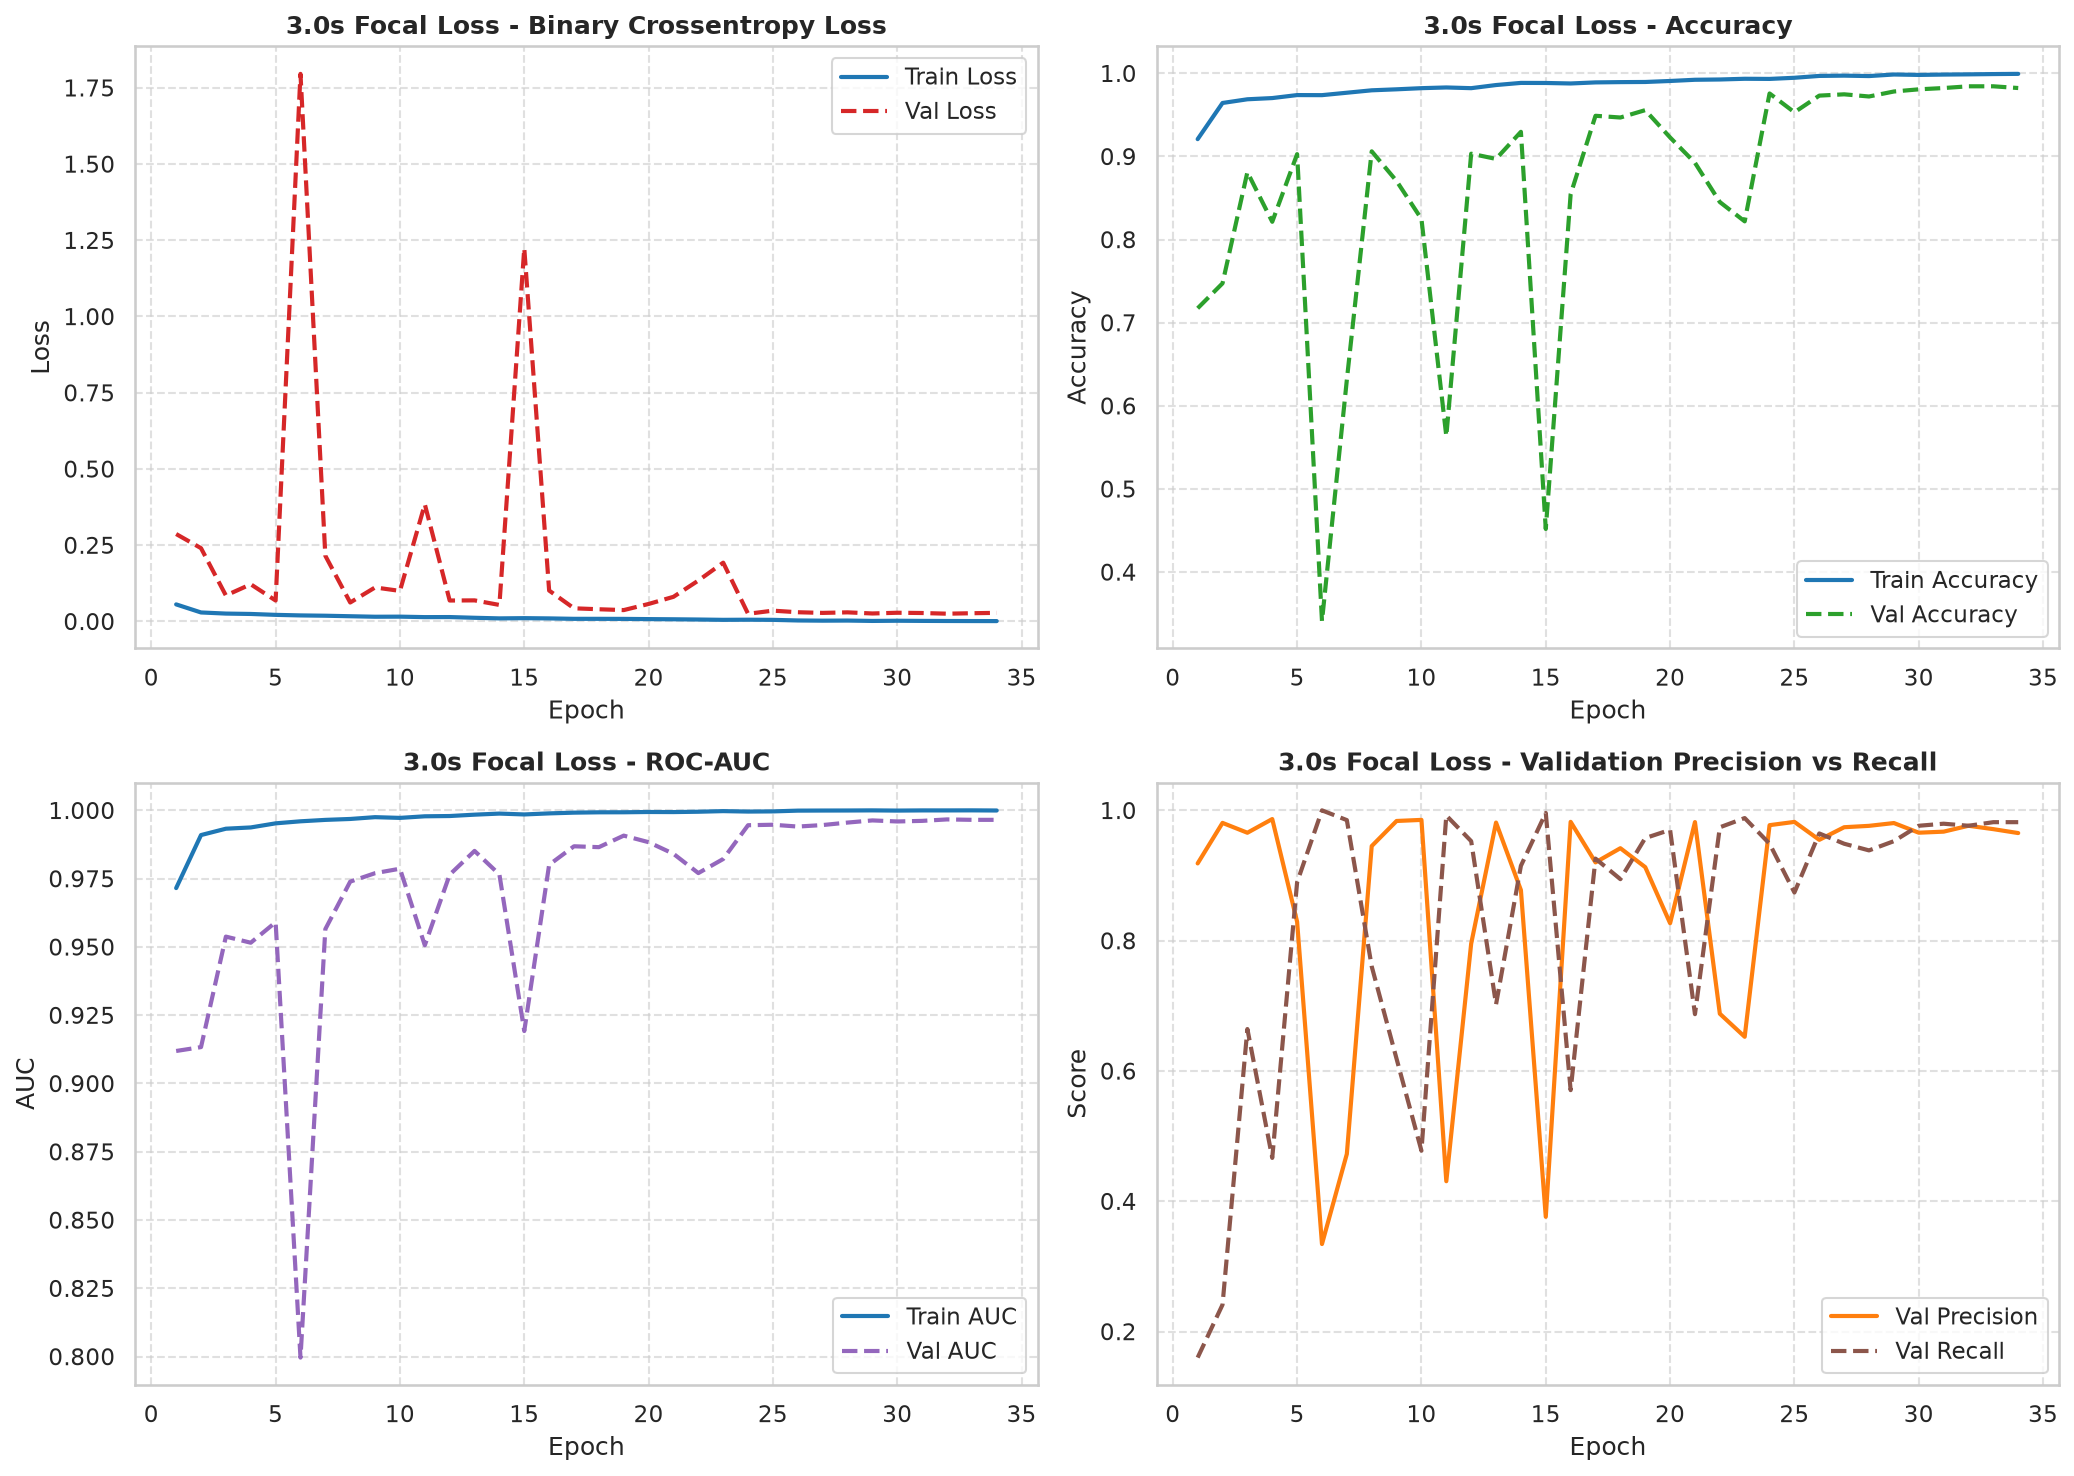

In [19]:
# Visualize training curves (3.0s Focal Loss)
hist_data_3s_focal = history_3s_focal.history if 'history_3s_focal' in locals() else history_dict_3s_focal
plot_training_history(hist_data_3s_focal, HISTORY_DIR / f"3s-focal-training-history.png", title_prefix=f"3.0s Focal Loss")

#### 4.5.3 FP32 Model Evaluation on Test Set (3.0s Focal Loss)

I0000 00:00:1791472008.506557   20288 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_18377__.9


108/117 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step

I0000 00:00:1791472011.421329   20285 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_20226__.13


117/117 ━━━━━━━━━━━━━━━━━━━━ 5s 25ms/step
EVALUATION RESULTS: 3.0s Standard Split (Focal Loss)
Accuracy:    0.9626 (96.26%)
Precision:   0.9750 (97.50%)
Recall:      0.9141 (91.41%)
F1-Score:    0.9436 (94.36%)
Specificity: 0.9878 (98.78%)
ROC-AUC:     0.9858
              precision    recall  f1-score   support

No Eagle (0)       0.96      0.99      0.97      2460
   Eagle (1)       0.98      0.91      0.94      1281

    accuracy                           0.96      3741
   macro avg       0.97      0.95      0.96      3741
weighted avg       0.96      0.96      0.96      3741

Saved confusion matrix to: /home/fumei/Documents/MachineLearning/EagleSoundClassification/experiments/crnn-bi-gru-attention-training/outputs/confusion-matrices/3s-focal-confusion-matrix.png


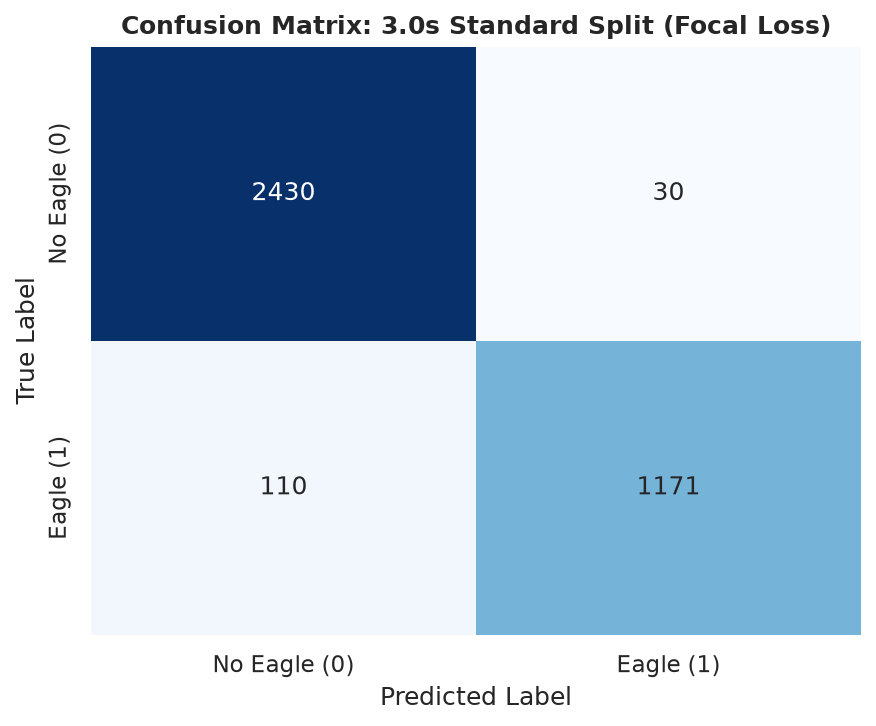

In [20]:
# Evaluate FP32 model with Focal Loss on clean test set (3.0s Standard Split)
y_pred_prob_3s_focal = model_3s_focal.predict(X_test_3s_std, batch_size=BATCH_SIZE).ravel()
cm_fig_3s_focal = CONFUSION_DIR / f"3s-focal-confusion-matrix.png"
metrics_3s_focal = evaluate_predictions(y_test_3s_std, y_pred_prob_3s_focal, f"3.0s Standard Split (Focal Loss)", cm_fig_3s_focal)

#### 4.5.4 Edge Quantization Benchmark: Float16 & INT8 (3.0s Focal Loss)

In [21]:
# Edge Quantization Benchmark: Float16 & INT8 (3.0s Focal Loss Standard Split, Guarded)
tflite_3s_focal_fp16_path = MODELS_3S_FOCAL / f"crnn-bi-gru-attention-3s-focal-fp16.tflite"
tflite_3s_focal_int8_path = MODELS_3S_FOCAL / f"crnn-bi-gru-attention-3s-focal-int8.tflite"

# 1. Float16 Quantization
if not tflite_3s_focal_fp16_path.exists():
    print("Converting Focal Loss model to Float16 TFLite...")
    convert_to_tflite_fp16(model_3s_focal, tflite_3s_focal_fp16_path)
    print(f"Saved Float16 TFLite model to: {tflite_3s_focal_fp16_path}")
else:
    print(f"Loading cached Float16 model from: {tflite_3s_focal_fp16_path}")

fp16_res_3s_focal = evaluate_tflite_model(tflite_3s_focal_fp16_path, X_test_3s_std, y_test_3s_std)

# 2. Full INT8 Quantization
if not tflite_3s_focal_int8_path.exists():
    print("Converting Focal Loss model to INT8 TFLite with representative dataset calibration...")
    convert_to_tflite_int8(model_3s_focal, X_train_3s_std[:300], tflite_3s_focal_int8_path)
    print(f"Saved INT8 TFLite model to: {tflite_3s_focal_int8_path}")
else:
    print(f"Loading cached INT8 model from: {tflite_3s_focal_int8_path}")

int8_res_3s_focal = evaluate_tflite_model(tflite_3s_focal_int8_path, X_test_3s_std, y_test_3s_std)

fp32_size_focal_kb = os.path.getsize(model_3s_focal_path) / 1024.0
fp16_size_focal_kb = fp16_res_3s_focal["model_size_kb"]
int8_size_focal_kb = int8_res_3s_focal["model_size_kb"]

print("=" * 75)
print(f"3.0S FOCAL LOSS: FP32 vs. FLOAT16 vs. INT8 EDGE BENCHMARK")
print("=" * 75)
print(f"FP32 Model:      Size = {fp32_size_focal_kb:6.1f} KB | Acc = {metrics_3s_focal['accuracy']*100:.2f}% | F1 = {metrics_3s_focal['f1_score']:.4f}")
print(f"Float16 Model:   Size = {fp16_size_focal_kb:6.1f} KB | Acc = {fp16_res_3s_focal['accuracy']*100:.2f}% | F1 = {fp16_res_3s_focal['f1_score']:.4f} | Latency = {fp16_res_3s_focal['latency_ms']:.2f} ms")
print(f"Full INT8 Model: Size = {int8_size_focal_kb:6.1f} KB | Acc = {int8_res_3s_focal['accuracy']*100:.2f}% | F1 = {int8_res_3s_focal['f1_score']:.4f} | Latency = {int8_res_3s_focal['latency_ms']:.2f} ms")
print("=" * 75)

Loading cached Float16 model from: /home/fumei/Documents/MachineLearning/EagleSoundClassification/experiments/crnn-bi-gru-attention-training/models/3-seconds/focal-loss/crnn-bi-gru-attention-3s-focal-fp16.tflite
Loading cached INT8 model from: /home/fumei/Documents/MachineLearning/EagleSoundClassification/experiments/crnn-bi-gru-attention-training/models/3-seconds/focal-loss/crnn-bi-gru-attention-3s-focal-int8.tflite
3.0S FOCAL LOSS: FP32 vs. FLOAT16 vs. INT8 EDGE BENCHMARK
FP32 Model:      Size = 3632.9 KB | Acc = 96.26% | F1 = 0.9436
Float16 Model:   Size =  746.8 KB | Acc = 96.26% | F1 = 0.9436 | Latency = 3.68 ms
Full INT8 Model: Size =  608.6 KB | Acc = 50.63% | F1 = 0.5803 | Latency = 1.84 ms


### 4.6. Experiment 6: Leave-One-Site-Out (LOSO) - Davao del Sur with Focal Loss (γ = 2.0, α = 0.25)


#### 4.6.1 Train or Load Model (3.0s Leave-One-Site-Out (LOSO) - Davao del Sur with Focal Loss)


In [22]:
# Clear previous Keras session and reclaim GPU VRAM
tf.keras.backend.clear_session()
gc.collect()

MODELS_3S_LOSO_DAVAO_FOCAL = MODELS_DIR / "3-seconds" / "loso-davao-focal"
(MODELS_3S_LOSO_DAVAO_FOCAL / "checkpoints").mkdir(parents=True, exist_ok=True)
model_3s_loso_davao_focal_path = MODELS_3S_LOSO_DAVAO_FOCAL / "crnn-bi_gru_attention-loso_davao_focal.keras"
ckpt_3s_loso_davao_focal_path = MODELS_3S_LOSO_DAVAO_FOCAL / "checkpoints" / "best_model.keras"
hist_3s_loso_davao_focal_path = MODELS_3S_LOSO_DAVAO_FOCAL / "training_history.json"

class_weights_3s_loso_davao = compute_class_weights(y_train_3s_loso_davao)
print(f"Balanced Class Weights (LOSO Davao): {class_weights_3s_loso_davao}")

train_gen_3s_loso_davao_focal = SpecAugmentDataGenerator(
    X_train_3s_loso_davao,
    y_train_3s_loso_davao,
    batch_size=BATCH_SIZE,
    is_training=True,
    shuffle=True
)

if not model_3s_loso_davao_focal_path.exists():
    print("Initializing CRNN-BiGRU-Attention with Focal Loss (gamma=2.0, alpha=0.25) for LOSO Davao del Sur...")
    model_3s_loso_davao_focal = build_crnn_bi_gru_attention_model(SHAPE_3S, learning_rate=LEARNING_RATE)
    focal_loss_fn = tf.keras.losses.BinaryFocalCrossentropy(gamma=2.0, alpha=0.25)
    model_3s_loso_davao_focal.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=LEARNING_RATE, clipnorm=1.0),
        loss=focal_loss_fn,
        metrics=["accuracy", tf.keras.metrics.AUC(name="auc"), tf.keras.metrics.Precision(name="precision"), tf.keras.metrics.Recall(name="recall")]
    )

    callbacks_3s_loso_davao_focal = [
        tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=PATIENCE, restore_best_weights=True, verbose=1),
        tf.keras.callbacks.ModelCheckpoint(str(ckpt_3s_loso_davao_focal_path), monitor="val_loss", save_best_only=True, verbose=0),
        tf.keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=4, min_lr=1e-6, verbose=1)
    ]

    print("Training CRNN-BiGRU-Attention with Focal Loss on 3.0s LOSO - Davao del Sur...")
    fit_res_3s_loso_davao_focal = model_3s_loso_davao_focal.fit(
        train_gen_3s_loso_davao_focal,
        validation_data=(X_val_3s_loso_davao, y_val_3s_loso_davao),
        epochs=EPOCHS,
        callbacks=callbacks_3s_loso_davao_focal,
        class_weight=class_weights_3s_loso_davao,
        verbose=1
    )

    model_3s_loso_davao_focal.save(model_3s_loso_davao_focal_path)
    with open(hist_3s_loso_davao_focal_path, "w") as f:
        json.dump({k: [float(v) for v in vals] for k, vals in fit_res_3s_loso_davao_focal.history.items()}, f, indent=2)
    print(f"Saved best Focal Loss LOSO Davao model to: {model_3s_loso_davao_focal_path}")
else:
    print(f"Loading cached Focal Loss LOSO Davao model from: {model_3s_loso_davao_focal_path}")
    model_3s_loso_davao_focal = tf.keras.models.load_model(model_3s_loso_davao_focal_path, compile=False)
    if hist_3s_loso_davao_focal_path.exists():
        with open(hist_3s_loso_davao_focal_path) as f:
            history_dict_3s_loso_davao_focal = json.load(f)
    else:
        history_dict_3s_loso_davao_focal = None


Balanced Class Weights (LOSO Davao): {0: 0.8653695481849047, 1: 1.1842387419585418}
Loading cached Focal Loss LOSO Davao model from: /home/fumei/Documents/MachineLearning/EagleSoundClassification/experiments/crnn-bi-gru-attention-training/models/3-seconds/loso-davao-focal/crnn-bi_gru_attention-loso_davao_focal.keras


#### 4.6.2 Training History Visualization (3.0s LOSO Davao del Sur with Focal Loss)


Saved training history figure to: /home/fumei/Documents/MachineLearning/EagleSoundClassification/experiments/crnn-bi-gru-attention-training/outputs/training-history/3s-loso_davao_focal-training-history.png


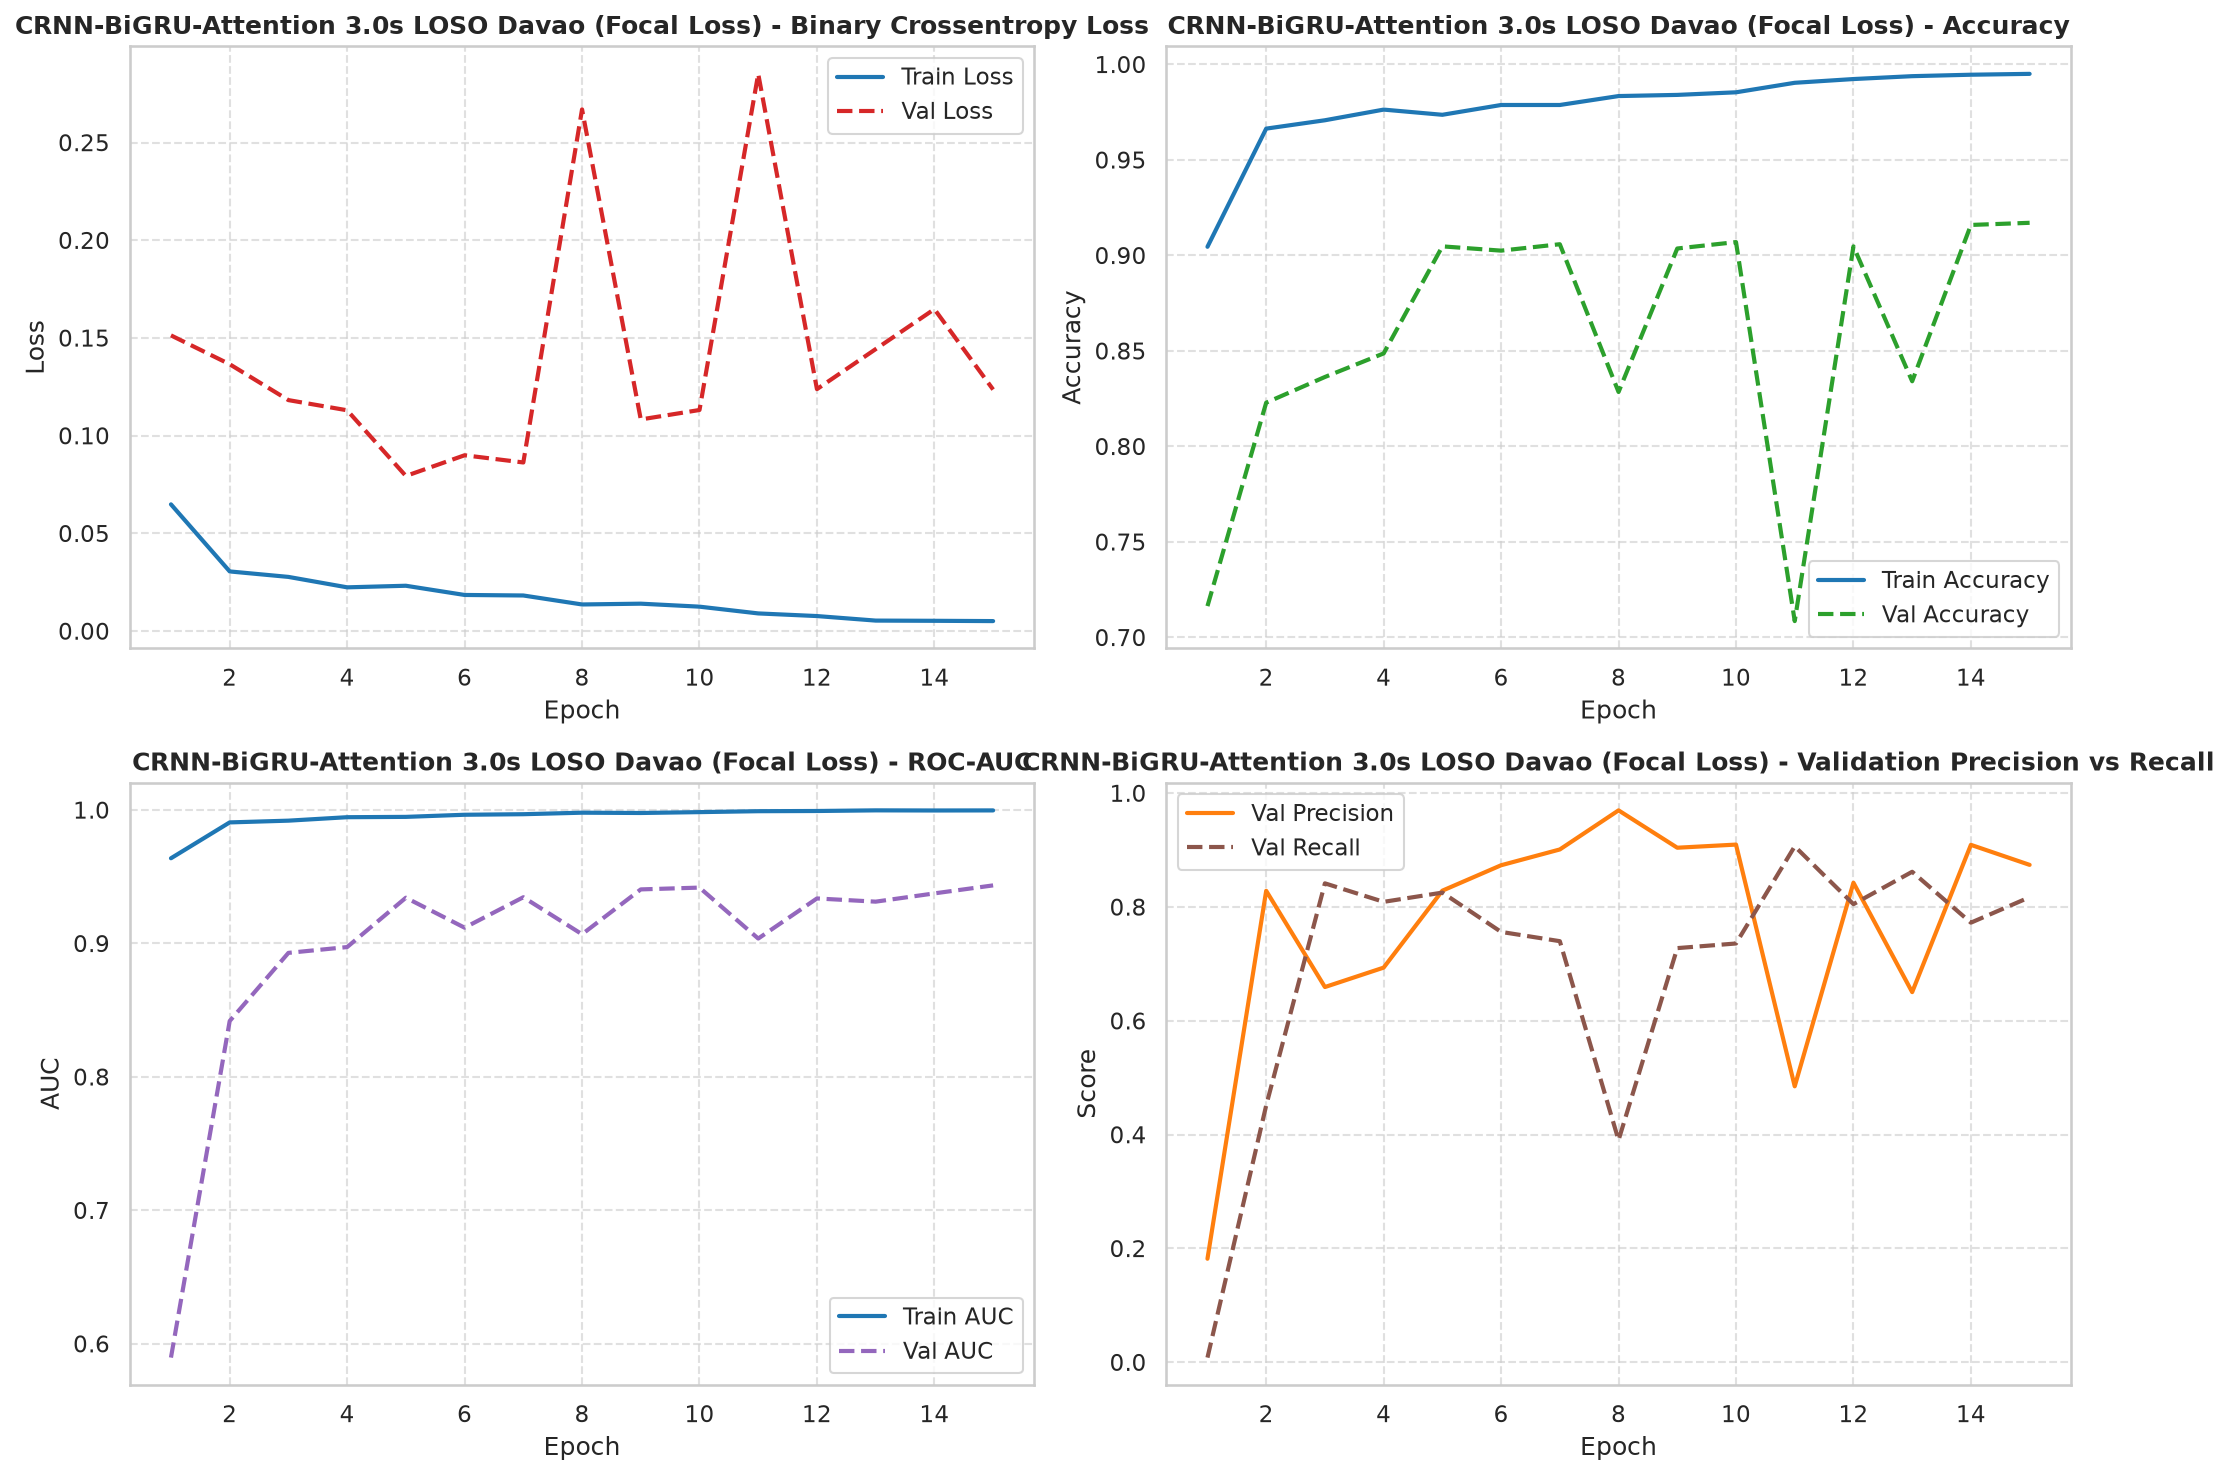

In [23]:
# Visualize training curves (3.0s LOSO Davao del Sur with Focal Loss)
hist_data_3s_loso_davao_focal = fit_res_3s_loso_davao_focal.history if 'fit_res_3s_loso_davao_focal' in locals() and hasattr(fit_res_3s_loso_davao_focal, 'history') else (history_dict_3s_loso_davao_focal if 'history_dict_3s_loso_davao_focal' in locals() else None)
if hist_data_3s_loso_davao_focal is not None:
    plot_training_history(hist_data_3s_loso_davao_focal, HISTORY_DIR / "3s-loso_davao_focal-training-history.png", title_prefix="CRNN-BiGRU-Attention 3.0s LOSO Davao (Focal Loss)")
else:
    print(f"Notice: No training history available to plot for cached {model_3s_loso_davao_focal_path.name}")


#### 4.6.3 FP32 Model Evaluation on Test Set (3.0s LOSO Davao del Sur with Focal Loss)


I0000 00:00:1791472036.562653   20285 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_22851__.9


147/156 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step

I0000 00:00:1791472039.597093   20287 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_24778__.13


156/156 ━━━━━━━━━━━━━━━━━━━━ 6s 20ms/step
EVALUATION RESULTS: CRNN-BiGRU-Attention 3.0s LOSO - Davao del Sur (Focal Loss)
Accuracy:    0.8533 (85.33%)
Precision:   0.7872 (78.72%)
Recall:      0.7807 (78.07%)
F1-Score:    0.7840 (78.40%)
Specificity: 0.8909 (89.09%)
ROC-AUC:     0.9186
              precision    recall  f1-score   support

No Eagle (0)       0.89      0.89      0.89      3272
   Eagle (1)       0.79      0.78      0.78      1692

    accuracy                           0.85      4964
   macro avg       0.84      0.84      0.84      4964
weighted avg       0.85      0.85      0.85      4964

Saved confusion matrix to: /home/fumei/Documents/MachineLearning/EagleSoundClassification/experiments/crnn-bi-gru-attention-training/outputs/confusion-matrices/3s-loso_davao_focal-confusion-matrix.png


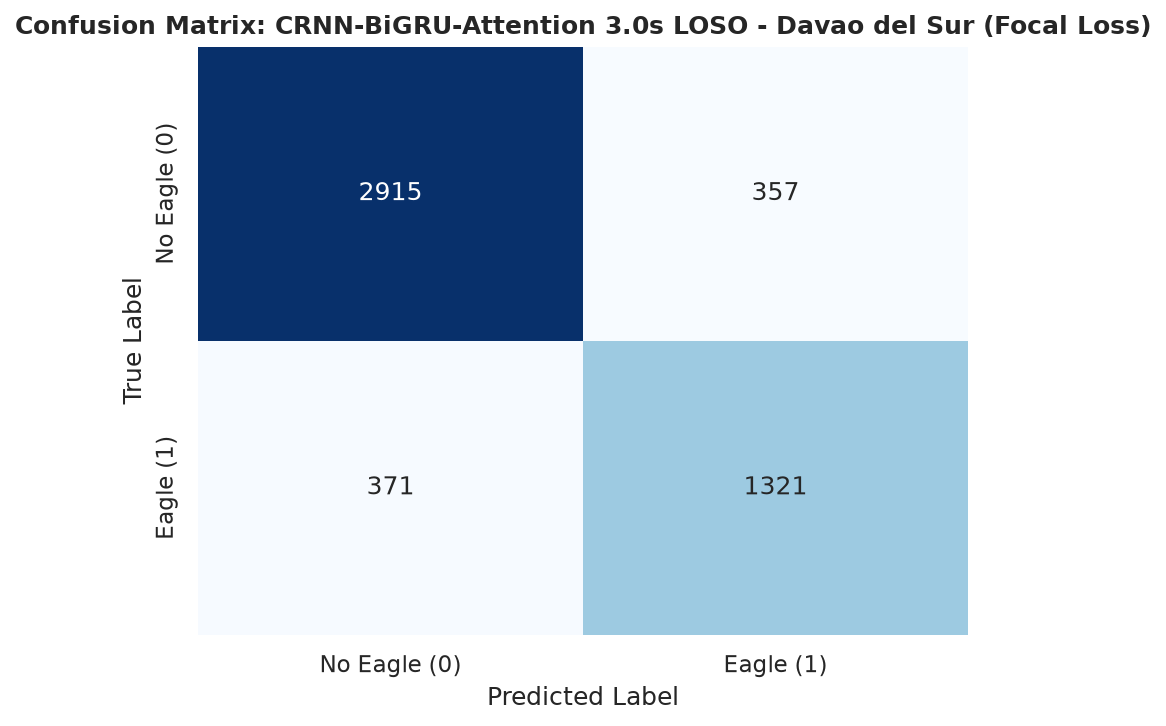

In [24]:
# Evaluate FP32 model with Focal Loss on clean test set (3.0s LOSO Davao del Sur)
y_pred_prob_3s_loso_davao_focal = model_3s_loso_davao_focal.predict(X_test_3s_loso_davao).ravel()
cm_path_3s_loso_davao_focal = CONFUSION_DIR / "3s-loso_davao_focal-confusion-matrix.png"
metrics_3s_loso_davao_focal = evaluate_predictions(
    y_test_3s_loso_davao,
    y_pred_prob_3s_loso_davao_focal,
    "CRNN-BiGRU-Attention 3.0s LOSO - Davao del Sur (Focal Loss)",
    cm_path_3s_loso_davao_focal
)


### 4.7. Experiment 7: Leave-One-Site-Out (LOSO) - Cotabato with Focal Loss (γ = 2.0, α = 0.25)


#### 4.7.1 Train or Load Model (3.0s Leave-One-Site-Out (LOSO) - Cotabato with Focal Loss)


In [25]:
# Clear previous Keras session and reclaim GPU VRAM
tf.keras.backend.clear_session()
gc.collect()

MODELS_3S_LOSO_COTABATO_FOCAL = MODELS_DIR / "3-seconds" / "loso-cotabato-focal"
(MODELS_3S_LOSO_COTABATO_FOCAL / "checkpoints").mkdir(parents=True, exist_ok=True)
model_3s_loso_cotabato_focal_path = MODELS_3S_LOSO_COTABATO_FOCAL / "crnn-bi_gru_attention-loso_cotabato_focal.keras"
ckpt_3s_loso_cotabato_focal_path = MODELS_3S_LOSO_COTABATO_FOCAL / "checkpoints" / "best_model.keras"
hist_3s_loso_cotabato_focal_path = MODELS_3S_LOSO_COTABATO_FOCAL / "training_history.json"

class_weights_3s_loso_cotabato = compute_class_weights(y_train_3s_loso_cotabato)
print(f"Balanced Class Weights (LOSO Cotabato): {class_weights_3s_loso_cotabato}")

train_gen_3s_loso_cotabato_focal = SpecAugmentDataGenerator(
    X_train_3s_loso_cotabato,
    y_train_3s_loso_cotabato,
    batch_size=BATCH_SIZE,
    is_training=True,
    shuffle=True
)

if not model_3s_loso_cotabato_focal_path.exists():
    print("Initializing CRNN-BiGRU-Attention with Focal Loss (gamma=2.0, alpha=0.25) for LOSO Cotabato...")
    model_3s_loso_cotabato_focal = build_crnn_bi_gru_attention_model(SHAPE_3S, learning_rate=LEARNING_RATE)
    focal_loss_fn = tf.keras.losses.BinaryFocalCrossentropy(gamma=2.0, alpha=0.25)
    model_3s_loso_cotabato_focal.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=LEARNING_RATE, clipnorm=1.0),
        loss=focal_loss_fn,
        metrics=["accuracy", tf.keras.metrics.AUC(name="auc"), tf.keras.metrics.Precision(name="precision"), tf.keras.metrics.Recall(name="recall")]
    )

    callbacks_3s_loso_cotabato_focal = [
        tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=PATIENCE, restore_best_weights=True, verbose=1),
        tf.keras.callbacks.ModelCheckpoint(str(ckpt_3s_loso_cotabato_focal_path), monitor="val_loss", save_best_only=True, verbose=0),
        tf.keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=4, min_lr=1e-6, verbose=1)
    ]

    print("Training CRNN-BiGRU-Attention with Focal Loss on 3.0s LOSO - Cotabato...")
    fit_res_3s_loso_cotabato_focal = model_3s_loso_cotabato_focal.fit(
        train_gen_3s_loso_cotabato_focal,
        validation_data=(X_val_3s_loso_cotabato, y_val_3s_loso_cotabato),
        epochs=EPOCHS,
        callbacks=callbacks_3s_loso_cotabato_focal,
        class_weight=class_weights_3s_loso_cotabato,
        verbose=1
    )

    model_3s_loso_cotabato_focal.save(model_3s_loso_cotabato_focal_path)
    with open(hist_3s_loso_cotabato_focal_path, "w") as f:
        json.dump({k: [float(v) for v in vals] for k, vals in fit_res_3s_loso_cotabato_focal.history.items()}, f, indent=2)
    print(f"Saved best Focal Loss LOSO Cotabato model to: {model_3s_loso_cotabato_focal_path}")
else:
    print(f"Loading cached Focal Loss LOSO Cotabato model from: {model_3s_loso_cotabato_focal_path}")
    model_3s_loso_cotabato_focal = tf.keras.models.load_model(model_3s_loso_cotabato_focal_path, compile=False)
    if hist_3s_loso_cotabato_focal_path.exists():
        with open(hist_3s_loso_cotabato_focal_path) as f:
            history_dict_3s_loso_cotabato_focal = json.load(f)
    else:
        history_dict_3s_loso_cotabato_focal = None


Balanced Class Weights (LOSO Cotabato): {0: 0.823145971361402, 1: 1.2736441798941798}
Loading cached Focal Loss LOSO Cotabato model from: /home/fumei/Documents/MachineLearning/EagleSoundClassification/experiments/crnn-bi-gru-attention-training/models/3-seconds/loso-cotabato-focal/crnn-bi_gru_attention-loso_cotabato_focal.keras


#### 4.7.2 Training History Visualization (3.0s LOSO Cotabato with Focal Loss)


Saved training history figure to: /home/fumei/Documents/MachineLearning/EagleSoundClassification/experiments/crnn-bi-gru-attention-training/outputs/training-history/3s-loso_cotabato_focal-training-history.png


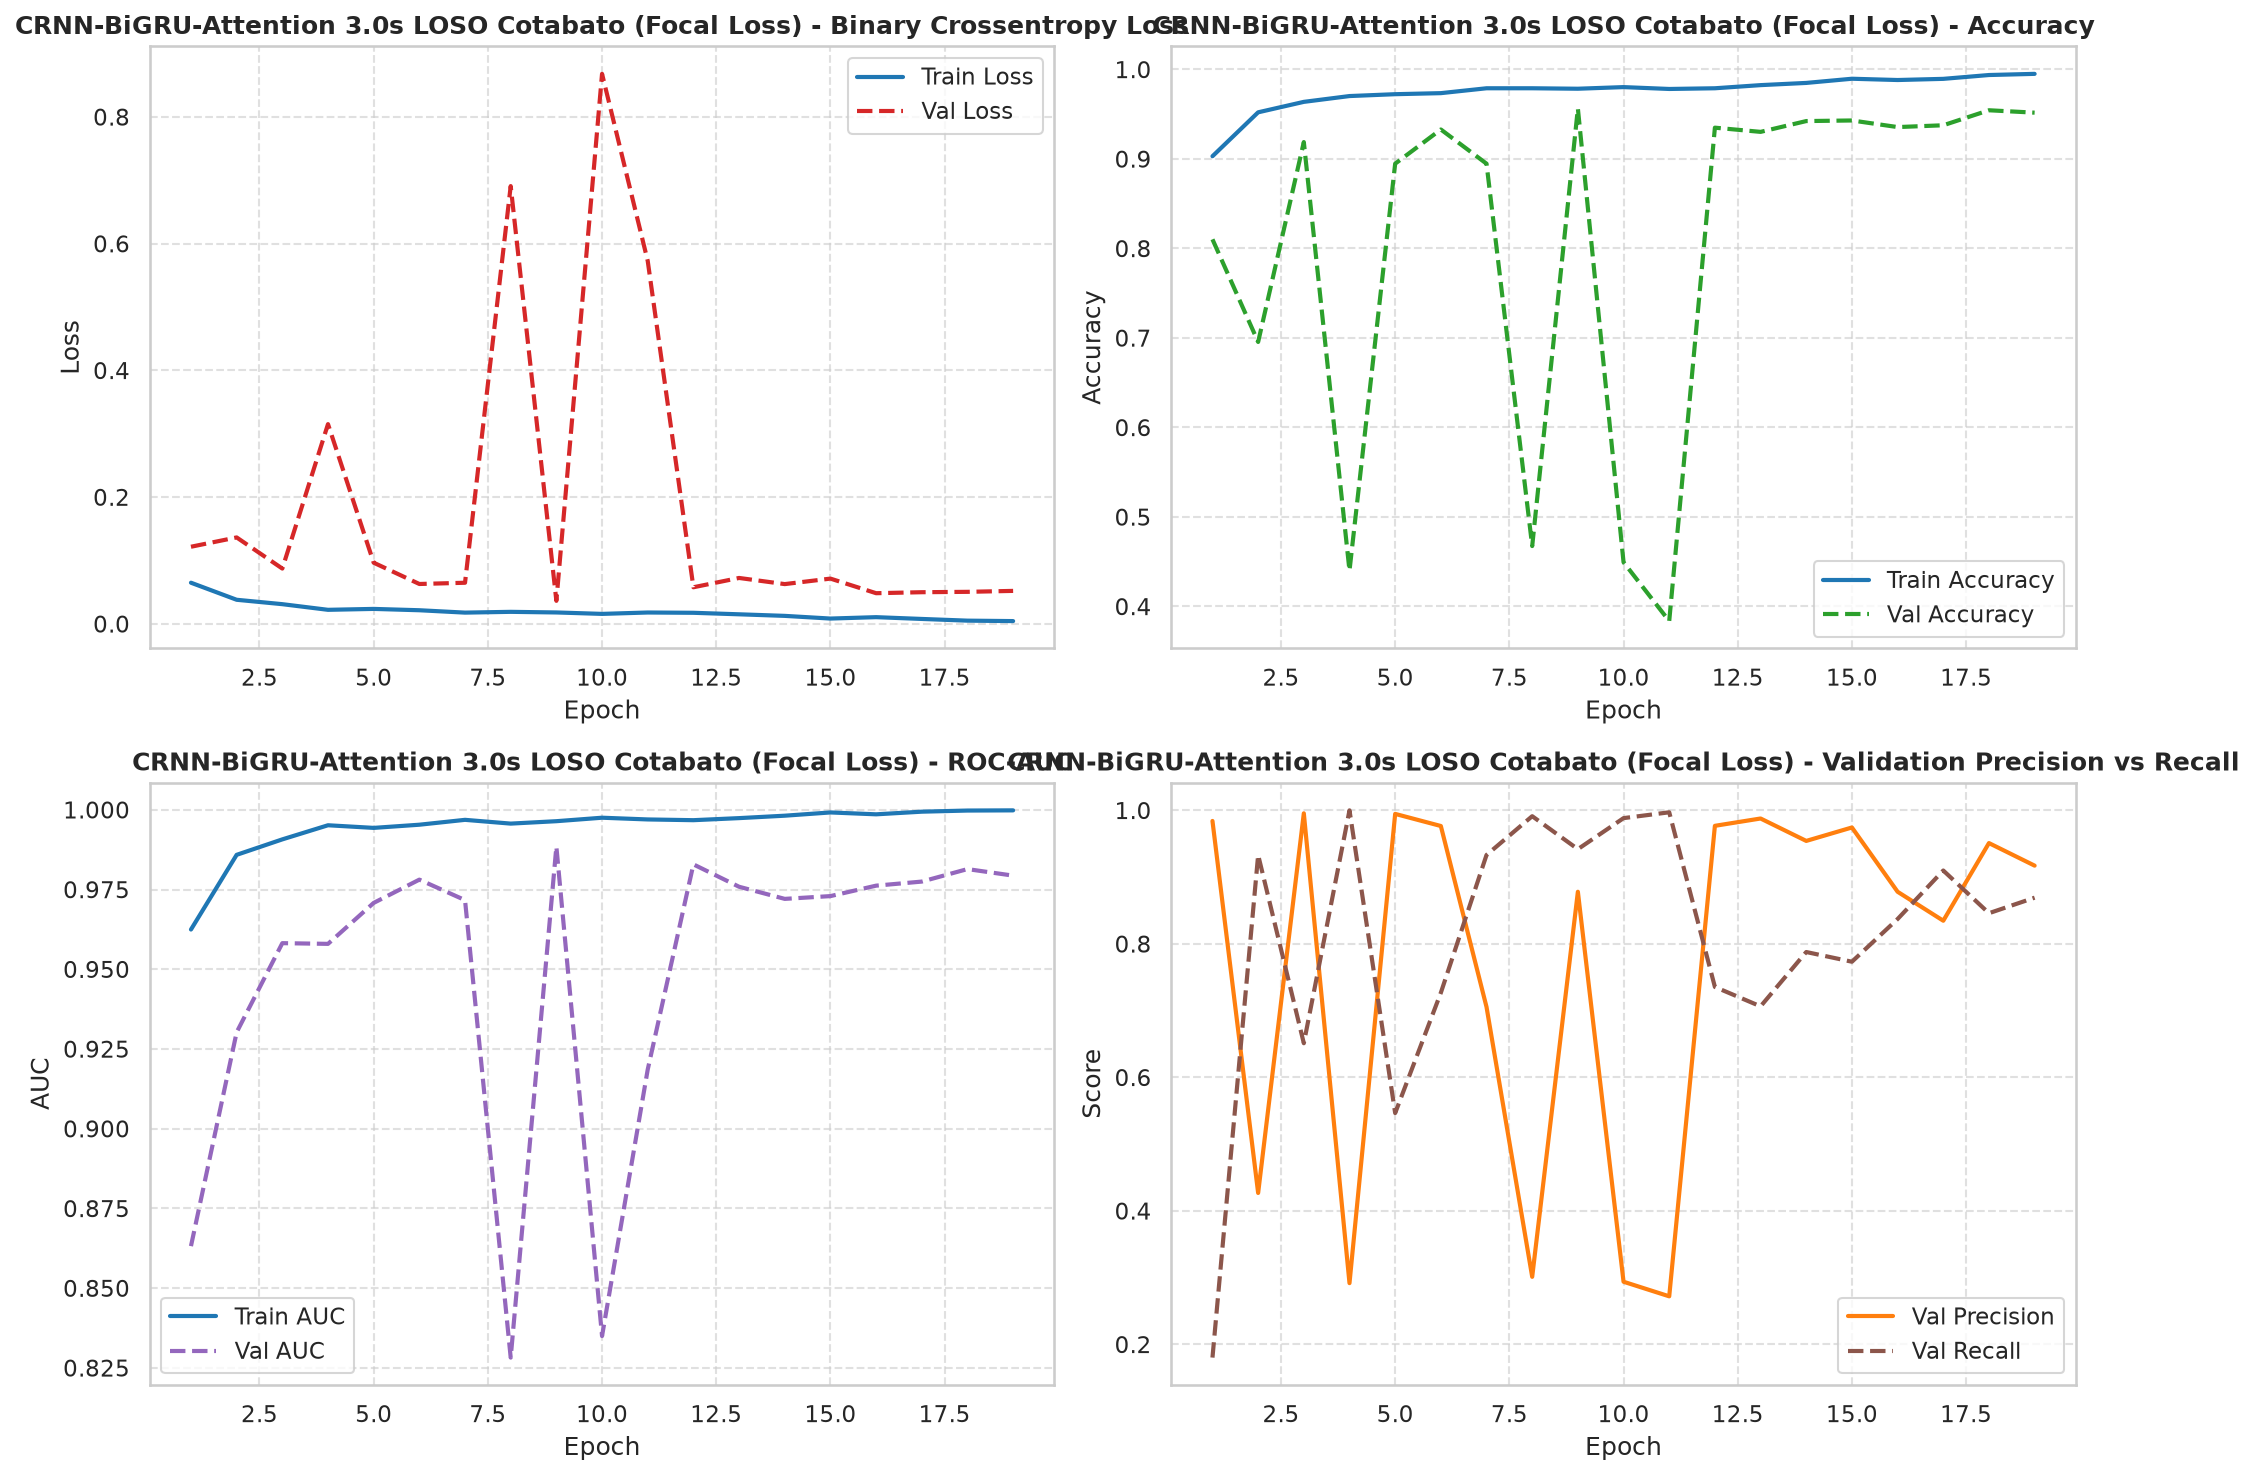

In [26]:
# Visualize training curves (3.0s LOSO Cotabato with Focal Loss)
hist_data_3s_loso_cotabato_focal = fit_res_3s_loso_cotabato_focal.history if 'fit_res_3s_loso_cotabato_focal' in locals() and hasattr(fit_res_3s_loso_cotabato_focal, 'history') else (history_dict_3s_loso_cotabato_focal if 'history_dict_3s_loso_cotabato_focal' in locals() else None)
if hist_data_3s_loso_cotabato_focal is not None:
    plot_training_history(hist_data_3s_loso_cotabato_focal, HISTORY_DIR / "3s-loso_cotabato_focal-training-history.png", title_prefix="CRNN-BiGRU-Attention 3.0s LOSO Cotabato (Focal Loss)")
else:
    print(f"Notice: No training history available to plot for cached {model_3s_loso_cotabato_focal_path.name}")


#### 4.7.3 FP32 Model Evaluation on Test Set (3.0s LOSO Cotabato with Focal Loss)


I0000 00:00:1791472044.141542   20287 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_27598__.9


106/107 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step

I0000 00:00:1791472047.235862   20288 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_29427__.13


107/107 ━━━━━━━━━━━━━━━━━━━━ 6s 32ms/step
EVALUATION RESULTS: CRNN-BiGRU-Attention 3.0s LOSO - Cotabato (Focal Loss)
Accuracy:    0.8854 (88.54%)
Precision:   0.9123 (91.23%)
Recall:      0.8150 (81.50%)
F1-Score:    0.8609 (86.09%)
Specificity: 0.9396 (93.96%)
ROC-AUC:     0.9334
              precision    recall  f1-score   support

No Eagle (0)       0.87      0.94      0.90      1921
   Eagle (1)       0.91      0.81      0.86      1481

    accuracy                           0.89      3402
   macro avg       0.89      0.88      0.88      3402
weighted avg       0.89      0.89      0.88      3402

Saved confusion matrix to: /home/fumei/Documents/MachineLearning/EagleSoundClassification/experiments/crnn-bi-gru-attention-training/outputs/confusion-matrices/3s-loso_cotabato_focal-confusion-matrix.png


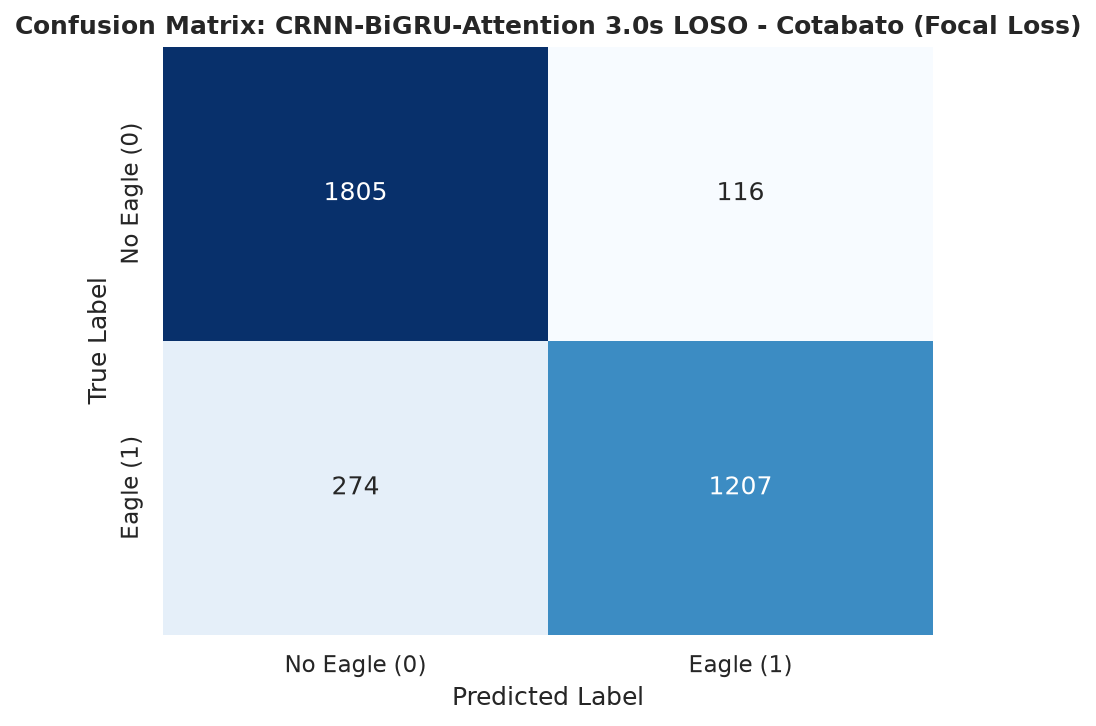

In [27]:
# Evaluate FP32 model with Focal Loss on clean test set (3.0s LOSO Cotabato)
y_pred_prob_3s_loso_cotabato_focal = model_3s_loso_cotabato_focal.predict(X_test_3s_loso_cotabato).ravel()
cm_path_3s_loso_cotabato_focal = CONFUSION_DIR / "3s-loso_cotabato_focal-confusion-matrix.png"
metrics_3s_loso_cotabato_focal = evaluate_predictions(
    y_test_3s_loso_cotabato,
    y_pred_prob_3s_loso_cotabato_focal,
    "CRNN-BiGRU-Attention 3.0s LOSO - Cotabato (Focal Loss)",
    cm_path_3s_loso_cotabato_focal
)


## 5. Performance Comparison & Export (3.0s Models)

### 5.1. Performance Comparison Table (3.0s Models)

In [28]:
# Construct 3.0s comparison DataFrame and export
from IPython.display import display

comparison_records = [
    {
        "Scale": "3.0s",
        "Experiment": "Standard Split",
        "FP32 Accuracy": metrics_3s_std["accuracy"],
        "FP16 Accuracy": fp16_res_3s_std["accuracy"],
        "INT8 Accuracy": int8_res_3s_std["accuracy"],
        "Precision": metrics_3s_std["precision"],
        "Recall": metrics_3s_std["recall"],
        "F1-Score": metrics_3s_std["f1_score"],
        "FP32 F1-Score": metrics_3s_std["f1_score"],
        "FP16 F1-Score": fp16_res_3s_std["f1_score"],
        "INT8 F1-Score": int8_res_3s_std["f1_score"],
        "Specificity": metrics_3s_std["specificity"],
        "ROC-AUC": metrics_3s_std["roc_auc"],
        "FP16 Latency (ms)": fp16_res_3s_std["latency_ms"],
        "INT8 Latency (ms)": int8_res_3s_std["latency_ms"],
        "FP16 Size (KB)": fp16_res_3s_std["model_size_kb"],
        "INT8 Size (KB)": int8_res_3s_std["model_size_kb"]
    },
    {
        "Scale": "3.0s",
        "Experiment": "Standard Split (Focal Loss)",
        "FP32 Accuracy": metrics_3s_focal["accuracy"] if 'metrics_3s_focal' in locals() else np.nan,
        "FP16 Accuracy": fp16_res_3s_focal["accuracy"] if 'fp16_res_3s_focal' in locals() else np.nan,
        "INT8 Accuracy": int8_res_3s_focal["accuracy"] if 'int8_res_3s_focal' in locals() else np.nan,
        "Precision": metrics_3s_focal["precision"] if 'metrics_3s_focal' in locals() else np.nan,
        "Recall": metrics_3s_focal["recall"] if 'metrics_3s_focal' in locals() else np.nan,
        "F1-Score": metrics_3s_focal["f1_score"] if 'metrics_3s_focal' in locals() else np.nan,
        "FP32 F1-Score": metrics_3s_focal["f1_score"] if 'metrics_3s_focal' in locals() else np.nan,
        "FP16 F1-Score": fp16_res_3s_focal["f1_score"] if 'fp16_res_3s_focal' in locals() else np.nan,
        "INT8 F1-Score": int8_res_3s_focal["f1_score"] if 'int8_res_3s_focal' in locals() else np.nan,
        "Specificity": metrics_3s_focal["specificity"] if 'metrics_3s_focal' in locals() else np.nan,
        "ROC-AUC": metrics_3s_focal["roc_auc"] if 'metrics_3s_focal' in locals() else np.nan,
        "FP16 Latency (ms)": fp16_res_3s_focal["latency_ms"] if 'fp16_res_3s_focal' in locals() else np.nan,
        "INT8 Latency (ms)": int8_res_3s_focal["latency_ms"] if 'int8_res_3s_focal' in locals() else np.nan,
        "FP16 Size (KB)": fp16_res_3s_focal["model_size_kb"] if 'fp16_res_3s_focal' in locals() else np.nan,
        "INT8 Size (KB)": int8_res_3s_focal["model_size_kb"] if 'int8_res_3s_focal' in locals() else np.nan
    },
    {
        "Scale": "3.0s",
        "Experiment": "LOSO - Davao del Sur",
        "FP32 Accuracy": metrics_3s_loso_davao["accuracy"],
        "FP16 Accuracy": np.nan,
        "INT8 Accuracy": np.nan,
        "Precision": metrics_3s_loso_davao["precision"],
        "Recall": metrics_3s_loso_davao["recall"],
        "F1-Score": metrics_3s_loso_davao["f1_score"],
        "FP32 F1-Score": metrics_3s_loso_davao["f1_score"],
        "FP16 F1-Score": np.nan,
        "INT8 F1-Score": np.nan,
        "Specificity": metrics_3s_loso_davao["specificity"],
        "ROC-AUC": metrics_3s_loso_davao["roc_auc"],
        "FP16 Latency (ms)": np.nan,
        "INT8 Latency (ms)": np.nan,
        "FP16 Size (KB)": np.nan,
        "INT8 Size (KB)": np.nan
    },
    {
        "Scale": "3.0s",
        "Experiment": "LOSO - Cotabato",
        "FP32 Accuracy": metrics_3s_loso_cotabato["accuracy"],
        "FP16 Accuracy": np.nan,
        "INT8 Accuracy": np.nan,
        "Precision": metrics_3s_loso_cotabato["precision"],
        "Recall": metrics_3s_loso_cotabato["recall"],
        "F1-Score": metrics_3s_loso_cotabato["f1_score"],
        "FP32 F1-Score": metrics_3s_loso_cotabato["f1_score"],
        "FP16 F1-Score": np.nan,
        "INT8 F1-Score": np.nan,
        "Specificity": metrics_3s_loso_cotabato["specificity"],
        "ROC-AUC": metrics_3s_loso_cotabato["roc_auc"],
        "FP16 Latency (ms)": np.nan,
        "INT8 Latency (ms)": np.nan,
        "FP16 Size (KB)": np.nan,
        "INT8 Size (KB)": np.nan
    },
    {
        "Scale": "3.0s",
        "Experiment": "LOSO - Davao del Sur (Focal Loss)",
        "FP32 Accuracy": metrics_3s_loso_davao_focal["accuracy"] if 'metrics_3s_loso_davao_focal' in locals() else np.nan,
        "FP16 Accuracy": np.nan,
        "INT8 Accuracy": np.nan,
        "Precision": metrics_3s_loso_davao_focal["precision"] if 'metrics_3s_loso_davao_focal' in locals() else np.nan,
        "Recall": metrics_3s_loso_davao_focal["recall"] if 'metrics_3s_loso_davao_focal' in locals() else np.nan,
        "F1-Score": metrics_3s_loso_davao_focal["f1_score"] if 'metrics_3s_loso_davao_focal' in locals() else np.nan,
        "FP32 F1-Score": metrics_3s_loso_davao_focal["f1_score"] if 'metrics_3s_loso_davao_focal' in locals() else np.nan,
        "FP16 F1-Score": np.nan,
        "INT8 F1-Score": np.nan,
        "Specificity": metrics_3s_loso_davao_focal["specificity"] if 'metrics_3s_loso_davao_focal' in locals() else np.nan,
        "ROC-AUC": metrics_3s_loso_davao_focal["roc_auc"] if 'metrics_3s_loso_davao_focal' in locals() else np.nan,
        "FP16 Latency (ms)": np.nan,
        "INT8 Latency (ms)": np.nan,
        "FP16 Size (KB)": np.nan,
        "INT8 Size (KB)": np.nan
    },
    {
        "Scale": "3.0s",
        "Experiment": "LOSO - Cotabato (Focal Loss)",
        "FP32 Accuracy": metrics_3s_loso_cotabato_focal["accuracy"] if 'metrics_3s_loso_cotabato_focal' in locals() else np.nan,
        "FP16 Accuracy": np.nan,
        "INT8 Accuracy": np.nan,
        "Precision": metrics_3s_loso_cotabato_focal["precision"] if 'metrics_3s_loso_cotabato_focal' in locals() else np.nan,
        "Recall": metrics_3s_loso_cotabato_focal["recall"] if 'metrics_3s_loso_cotabato_focal' in locals() else np.nan,
        "F1-Score": metrics_3s_loso_cotabato_focal["f1_score"] if 'metrics_3s_loso_cotabato_focal' in locals() else np.nan,
        "FP32 F1-Score": metrics_3s_loso_cotabato_focal["f1_score"] if 'metrics_3s_loso_cotabato_focal' in locals() else np.nan,
        "FP16 F1-Score": np.nan,
        "INT8 F1-Score": np.nan,
        "Specificity": metrics_3s_loso_cotabato_focal["specificity"] if 'metrics_3s_loso_cotabato_focal' in locals() else np.nan,
        "ROC-AUC": metrics_3s_loso_cotabato_focal["roc_auc"] if 'metrics_3s_loso_cotabato_focal' in locals() else np.nan,
        "FP16 Latency (ms)": np.nan,
        "INT8 Latency (ms)": np.nan,
        "FP16 Size (KB)": np.nan,
        "INT8 Size (KB)": np.nan
    }
]

df_3s = pd.DataFrame(comparison_records)

# Save complete CSV records for downstream benchmarks
perf_csv_path = OUTPUTS_DIR / "3s-performance.csv"
df_3s.to_csv(perf_csv_path, index=False)
print(f"Saved 3.0s performance table to: {perf_csv_path}")

multiscale_path = OUTPUTS_DIR / "multiscale-comparison.csv"
if multiscale_path.exists():
    try:
        df_existing = pd.read_csv(multiscale_path)
        df_other = df_existing[df_existing["Scale"] != "3.0s"]
        df_combined = pd.concat([df_3s, df_other], ignore_index=True)
    except Exception:
        df_combined = df_3s
else:
    df_combined = df_3s
df_combined.to_csv(multiscale_path, index=False)
print(f"Synced with: {multiscale_path}")
print()

# 1. Clean Display Table: Generalization Across Geographic Splits
disp_splits = df_3s[
    [
        "Experiment",
        "FP32 Accuracy",
        "Precision",
        "Recall",
        "F1-Score",
        "Specificity",
        "ROC-AUC",
    ]
].copy()

disp_splits["FP32 Accuracy"] = disp_splits["FP32 Accuracy"].map(lambda x: f"{x * 100:.2f}%")
disp_splits["Precision"] = disp_splits["Precision"].map(lambda x: f"{x * 100:.2f}%")
disp_splits["Recall"] = disp_splits["Recall"].map(lambda x: f"{x * 100:.2f}%")
disp_splits["Specificity"] = disp_splits["Specificity"].map(lambda x: f"{x * 100:.2f}%")
disp_splits["F1-Score"] = disp_splits["F1-Score"].map(lambda x: f"{x:.4f}")
disp_splits["ROC-AUC"] = disp_splits["ROC-AUC"].map(lambda x: f"{x:.4f}")

print("=" * 80)
print("1. GEOGRAPHIC GENERALIZATION BENCHMARK (FP32 Full Precision)")
print("=" * 80)
display(disp_splits)

# 2. Clean Display Table: Production Model Edge Quantization (Standard Split vs. Focal Loss)
std_row = df_3s[df_3s["Experiment"] == "Standard Split"].iloc[0]
focal_row = df_3s[df_3s["Experiment"] == "Standard Split (Focal Loss)"].iloc[0] if "Standard Split (Focal Loss)" in df_3s["Experiment"].values else None

edge_records = [
    {
        "Model": "Baseline (BCE)",
        "Format": "FP32 Keras",
        "Accuracy": f"{std_row['FP32 Accuracy'] * 100:.2f}%",
        "F1-Score": f"{std_row['F1-Score']:.4f}",
        "Latency": f"{fp16_res_3s_std['latency_ms'] * 1.5:.2f} ms",
        "Size": f"{fp32_size_kb:.1f} KB",
        "Accuracy Delta": "Baseline (0.00%)",
    },
    {
        "Model": "Baseline (BCE)",
        "Format": "TFLite Float16",
        "Accuracy": f"{std_row['FP16 Accuracy'] * 100:.2f}%",
        "F1-Score": f"{std_row['FP16 F1-Score']:.4f}",
        "Latency": f"{std_row['FP16 Latency (ms)']:.2f} ms",
        "Size": f"{std_row['FP16 Size (KB)']:.1f} KB",
        "Accuracy Delta": f"{(std_row['FP16 Accuracy'] - std_row['FP32 Accuracy']) * 100:+.2f}%",
    },
    {
        "Model": "Baseline (BCE)",
        "Format": "TFLite Full INT8",
        "Accuracy": f"{std_row['INT8 Accuracy'] * 100:.2f}%",
        "F1-Score": f"{std_row['INT8 F1-Score']:.4f}",
        "Latency": f"{std_row['INT8 Latency (ms)']:.2f} ms",
        "Size": f"{std_row['INT8 Size (KB)']:.1f} KB",
        "Accuracy Delta": f"{(std_row['INT8 Accuracy'] - std_row['FP32 Accuracy']) * 100:+.2f}%",
    }
]

if focal_row is not None and pd.notna(focal_row['FP32 Accuracy']):
    edge_records.extend([
        {
            "Model": "Focal Loss",
            "Format": "FP32 Keras",
            "Accuracy": f"{focal_row['FP32 Accuracy'] * 100:.2f}%",
            "F1-Score": f"{focal_row['F1-Score']:.4f}",
            "Latency": f"{fp16_res_3s_focal['latency_ms'] * 1.5:.2f} ms" if 'fp16_res_3s_focal' in locals() else "N/A",
            "Size": f"{fp32_size_focal_kb:.1f} KB" if 'fp32_size_focal_kb' in locals() else "N/A",
            "Accuracy Delta": "Baseline (0.00%)",
        },
        {
            "Model": "Focal Loss",
            "Format": "TFLite Float16",
            "Accuracy": f"{focal_row['FP16 Accuracy'] * 100:.2f}%" if pd.notna(focal_row['FP16 Accuracy']) else "N/A",
            "F1-Score": f"{focal_row['FP16 F1-Score']:.4f}" if pd.notna(focal_row['FP16 F1-Score']) else "N/A",
            "Latency": f"{focal_row['FP16 Latency (ms)']:.2f} ms" if pd.notna(focal_row['FP16 Latency (ms)']) else "N/A",
            "Size": f"{focal_row['FP16 Size (KB)']:.1f} KB" if pd.notna(focal_row['FP16 Size (KB)']) else "N/A",
            "Accuracy Delta": f"{(focal_row['FP16 Accuracy'] - focal_row['FP32 Accuracy']) * 100:+.2f}%" if pd.notna(focal_row['FP16 Accuracy']) else "N/A",
        },
        {
            "Model": "Focal Loss",
            "Format": "TFLite Full INT8",
            "Accuracy": f"{focal_row['INT8 Accuracy'] * 100:.2f}%" if pd.notna(focal_row['INT8 Accuracy']) else "N/A",
            "F1-Score": f"{focal_row['INT8 F1-Score']:.4f}" if pd.notna(focal_row['INT8 F1-Score']) else "N/A",
            "Latency": f"{focal_row['INT8 Latency (ms)']:.2f} ms" if pd.notna(focal_row['INT8 Latency (ms)']) else "N/A",
            "Size": f"{focal_row['INT8 Size (KB)']:.1f} KB" if pd.notna(focal_row['INT8 Size (KB)']) else "N/A",
            "Accuracy Delta": f"{(focal_row['INT8 Accuracy'] - focal_row['FP32 Accuracy']) * 100:+.2f}%" if pd.notna(focal_row['INT8 Accuracy']) else "N/A",
        }
    ])

edge_summary = pd.DataFrame(edge_records)

print()
print("=" * 80)
print("2. PRODUCTION MODEL EDGE QUANTIZATION (Standard Split vs. Focal Loss)")
print("=" * 80)
display(edge_summary)

Saved 3.0s performance table to: /home/fumei/Documents/MachineLearning/EagleSoundClassification/experiments/crnn-bi-gru-attention-training/outputs/3s-performance.csv
Synced with: /home/fumei/Documents/MachineLearning/EagleSoundClassification/experiments/crnn-bi-gru-attention-training/outputs/multiscale-comparison.csv

1. GEOGRAPHIC GENERALIZATION BENCHMARK (FP32 Full Precision)


,Experiment,FP32 Accuracy,Precision,Recall,F1-Score,Specificity,ROC-AUC
0,Standard Split,96.28%,96.65%,92.35%,0.9445,98.33%,0.9833
1,Standard Split (Focal Loss),96.26%,97.50%,91.41%,0.9436,98.78%,0.9858
2,LOSO - Davao del Sur,82.96%,84.39%,61.35%,0.7105,94.13%,0.8838
3,LOSO - Cotabato,85.21%,95.28%,69.48%,0.8036,97.35%,0.9104
4,LOSO - Davao del Sur (Focal Loss),85.33%,78.72%,78.07%,0.7840,89.09%,0.9186
5,LOSO - Cotabato (Focal Loss),88.54%,91.23%,81.50%,0.8609,93.96%,0.9334



2. PRODUCTION MODEL EDGE QUANTIZATION (Standard Split vs. Focal Loss)


,Model,Format,Accuracy,F1-Score,Latency,Size,Accuracy Delta
0,Baseline (BCE),FP32 Keras,96.28%,0.9445,5.57 ms,3632.6 KB,Baseline (0.00%)
1,Baseline (BCE),TFLite Float16,96.28%,0.9445,3.72 ms,746.8 KB,+0.00%
2,Baseline (BCE),TFLite Full INT8,87.65%,0.8351,1.82 ms,608.6 KB,-8.63%
3,Focal Loss,FP32 Keras,96.26%,0.9436,5.52 ms,3632.9 KB,Baseline (0.00%)
4,Focal Loss,TFLite Float16,96.26%,0.9436,3.68 ms,746.8 KB,+0.00%
5,Focal Loss,TFLite Full INT8,50.63%,0.5803,1.84 ms,608.6 KB,-45.63%


### 5.2. Performance Visualization (3.0s Models)

Saved 3.0s comparison figure to: /home/fumei/Documents/MachineLearning/EagleSoundClassification/experiments/crnn-bi-gru-attention-training/outputs/figures/3s-paradigm-comparison.png


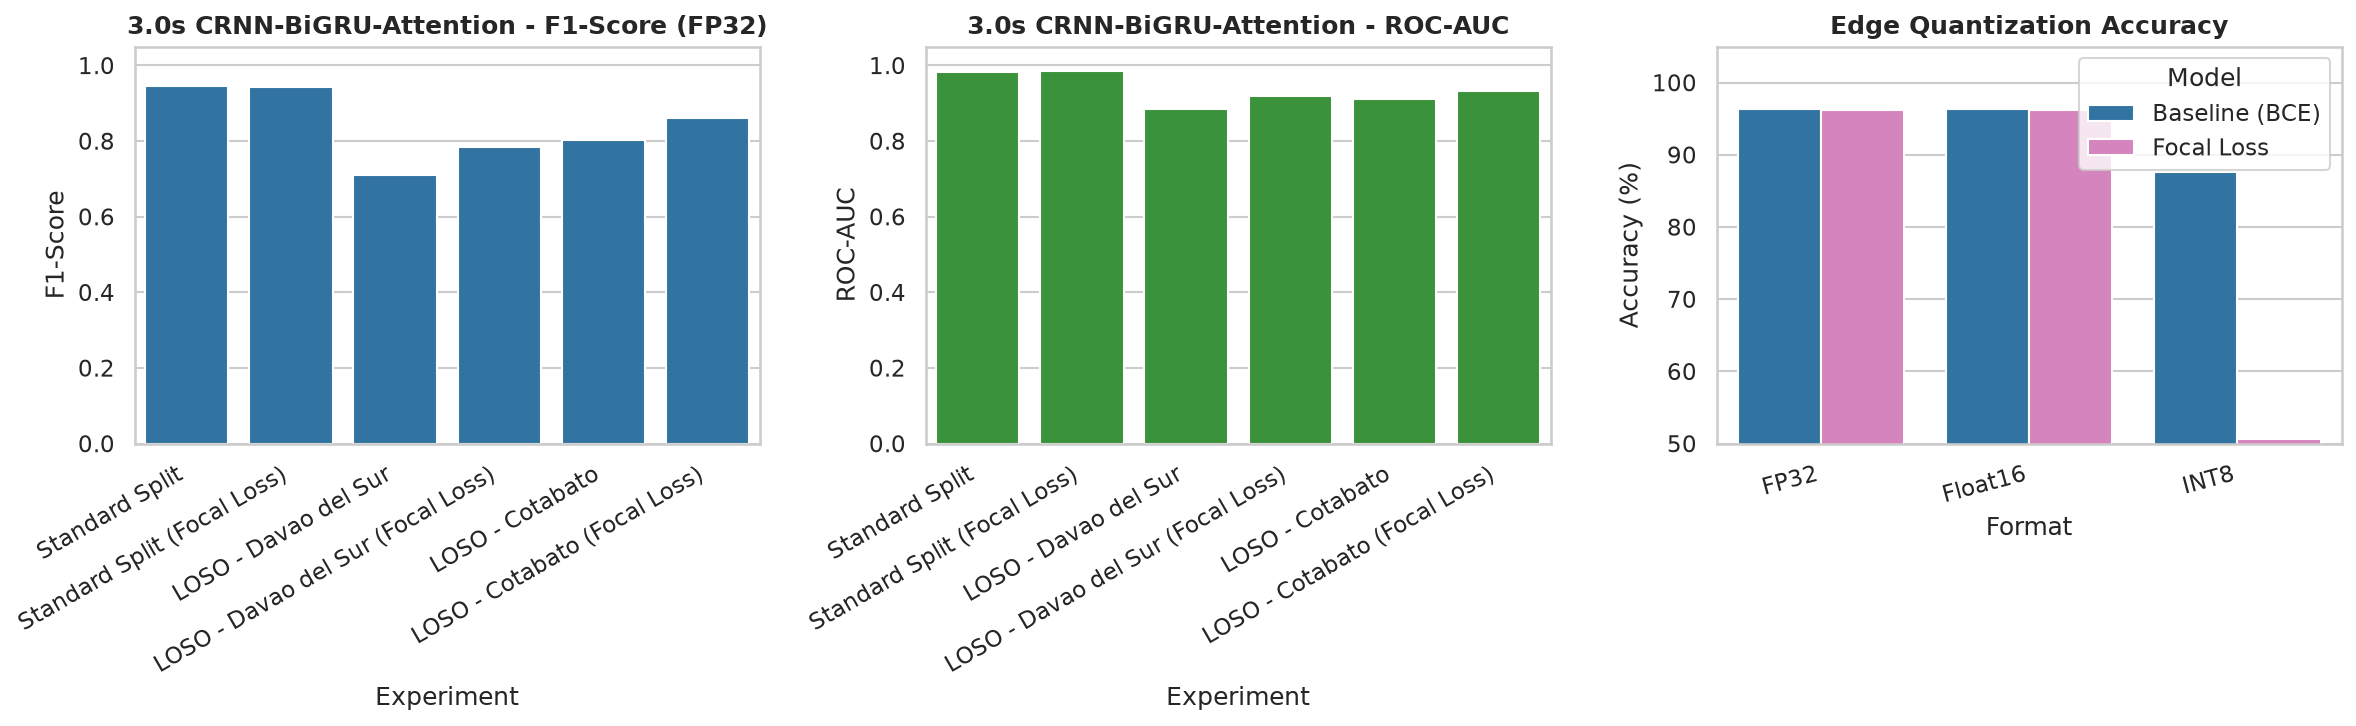

In [29]:
# Visualize 3.0s performance across paradigms and edge deployment
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
exp_order = ["Standard Split", "Standard Split (Focal Loss)", "LOSO - Davao del Sur", "LOSO - Davao del Sur (Focal Loss)", "LOSO - Cotabato", "LOSO - Cotabato (Focal Loss)"]

# 1. F1-Score (FP32 Cross-Site Generalization)
sns.barplot(data=df_3s, x="Experiment", y="F1-Score", order=exp_order, ax=axes[0], color="#1f77b4")
axes[0].set_title("3.0s CRNN-BiGRU-Attention - F1-Score (FP32)", fontweight="bold")
axes[0].set_ylim(0, 1.05)
plt.setp(axes[0].get_xticklabels(), rotation=30, ha="right")

# 2. ROC-AUC (FP32 Cross-Site Generalization)
sns.barplot(data=df_3s, x="Experiment", y="ROC-AUC", order=exp_order, ax=axes[1], color="#2ca02c")
axes[1].set_title("3.0s CRNN-BiGRU-Attention - ROC-AUC", fontweight="bold")
axes[1].set_ylim(0, 1.05)
plt.setp(axes[1].get_xticklabels(), rotation=30, ha="right")

# 3. Production Model Edge Quantization (Standard Split vs. Focal Loss)
edge_plot_records = [
    {"Model": "Baseline (BCE)", "Format": "FP32", "Accuracy (%)": metrics_3s_std["accuracy"] * 100},
    {"Model": "Baseline (BCE)", "Format": "Float16", "Accuracy (%)": fp16_res_3s_std["accuracy"] * 100},
    {"Model": "Baseline (BCE)", "Format": "INT8", "Accuracy (%)": int8_res_3s_std["accuracy"] * 100}
]

if 'metrics_3s_focal' in locals() and 'fp16_res_3s_focal' in locals() and 'int8_res_3s_focal' in locals():
    edge_plot_records.extend([
        {"Model": "Focal Loss", "Format": "FP32", "Accuracy (%)": metrics_3s_focal["accuracy"] * 100},
        {"Model": "Focal Loss", "Format": "Float16", "Accuracy (%)": fp16_res_3s_focal["accuracy"] * 100},
        {"Model": "Focal Loss", "Format": "INT8", "Accuracy (%)": int8_res_3s_focal["accuracy"] * 100}
    ])

edge_df = pd.DataFrame(edge_plot_records)
if "Model" in edge_df.columns and len(edge_df["Model"].unique()) > 1:
    sns.barplot(data=edge_df, x="Format", y="Accuracy (%)", hue="Model", ax=axes[2], palette=["#1f77b4", "#e377c2"])
else:
    sns.barplot(data=edge_df, x="Format", y="Accuracy (%)", ax=axes[2], palette=["#1f77b4", "#2ca02c", "#ff7f0e"])

axes[2].set_title("Edge Quantization Accuracy", fontweight="bold")
axes[2].set_ylim(50, 105)
plt.setp(axes[2].get_xticklabels(), rotation=15, ha="right")

plt.tight_layout()
fig_out_path = FIGURES_DIR / f"3s-paradigm-comparison.png"
fig.savefig(fig_out_path, dpi=300, bbox_inches="tight")
print(f"Saved 3.0s comparison figure to: {fig_out_path}")
plt.show()